# 일지테크 품질 데이터 분석 및 보고 자동화

| 장 | 내용 | 결과 폴더 (`output/`) |
|---|---|---|
| 1 | CQI 점수 자동 산출. 첨부1 불량 데이터로 18개 지표 실적을 계산하고 첨부3 산식으로 점수를 매긴 뒤 첨부3 회사 값과 대조 | `cqi/` |
| 2 | 월 품질실적보고 자동 작성. 원천 데이터 통합 CSV, 당월 CQI와 전월 대비 증감, 슬라이드별 표와 그래프, 첨부2 양식 PPT 작성 (AI 문구 제외) | `integrated/`, `report/` |
| 3 | "AI 분석 평가" 문구. 슬라이드 1의 ①금월 평가 ②개선성과 ③주요이슈 문구를 CQI 산식 분해, 원천 데이터 원인 분석, 과거 추이 비교로 작성 | `report/` |
| 4 | 영역별 상관분석. 고객, 프레스·조립, 협력사별로 어떤 유형이 어디서 언제 많이 나는지 교차표, 통계 검정, 그래프로 확인 | `analysis/` |
| 5 | 불량 예측. 사내 공정 불량 품번, 주요 라인 순위, 협력사·품번을 예측. 여러 ML 모델과 앙상블을 비교하고 학습·검증·테스트 기간을 나눠 평가 | `prediction/` |
| 6 | 데이터 대기 항목. 데이터가 없어 남겨 둔 부분과 데이터가 들어왔을 때 반영되는 방식 | - |

### 실행 방법
- 위에서부터 순서대로 실행합니다(Run All).
- 커널은 conda `project` 환경을 씁니다(pandas, scikit-learn, scipy, matplotlib, openpyxl, python-pptx). python-pptx가 없으면 PPT 작성만 건너뛰고 나머지는 그대로 실행됩니다.
- 새 데이터는 첨부1과 같은 형식의 엑셀을 `data/raw/추가전달자료/<받은 날짜>/`에 넣고 다시 실행하면 됩니다. 가장 최근 달이 보고 월로 잡히고, 다른 달을 보려면 아래 `REPORT_MONTH`를 바꿉니다.

## 0. 준비

### 0-1. 라이브러리, 설정, 폴더

- `REPORT_MONTH`: 보고할 달. `None`이면 데이터의 마지막 달을 씁니다.
- `USE_COMPANY_VALUE_IF_MISSING`: 원천 데이터가 없어 계산할 수 없는 칸(예: 8월 협력사 입고수량)을 첨부3 회사 값으로 채울지 정합니다. 채운 칸은 결과표 `출처` 열에 `첨부3 회사값`으로 남고, 원천 데이터가 들어오면 계산값으로 바뀝니다.

In [2]:
import re, io, zipfile, copy, warnings, unicodedata, fnmatch
from pathlib import Path

import numpy as np
import pandas as pd
import openpyxl
from openpyxl.utils import get_column_letter
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from IPython.display import display

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 220)
pd.set_option('display.max_colwidth', 70)

REPORT_MONTH = None
CQI_YEAR = 2026
SITE = '본사'
USE_COMPANY_VALUE_IF_MISSING = True
RANDOM_STATE = 42

PROJECT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'README.md').exists())
RAW_DIR    = PROJECT_DIR / 'data' / 'raw'
BASE_DIR   = RAW_DIR / '데이터'
ADD_DIR    = RAW_DIR / '추가전달자료'
MANUAL_DIR = PROJECT_DIR / 'data' / 'manual'
OUT_DIR    = PROJECT_DIR / 'output'
OUT = {name: OUT_DIR / name for name in ['integrated', 'cqi', 'report', 'analysis', 'prediction', 'figures']}
for folder in [MANUAL_DIR, *OUT.values()]:
    folder.mkdir(parents=True, exist_ok=True)

print('프로젝트 폴더 :', PROJECT_DIR)
print('pandas', pd.__version__, '| openpyxl', openpyxl.__version__)

프로젝트 폴더 : /Users/hyeonsoo/Desktop/PILAB/IljiTech
pandas 3.0.6 | openpyxl 3.1.5


### 0-2. 그래프 스타일

In [3]:
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
ACCENT, GRAY = PALETTE[0], '#c3c2b7'
INK, INK2, MUTED, GRID = '#0b0b0b', '#52514e', '#898781', '#e1e0d9'
STATUS_COLOR = {'양호': '#0ca30c', '주의': '#fab219', '미흡': '#d03b3b', '미입력': '#898781'}
SEQ_CMAP = LinearSegmentedColormap.from_list('seq_blue', ['#f7f9fc', '#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
DIV_CMAP = LinearSegmentedColormap.from_list('div_blue_red', ['#1c5cab', '#86b6ef', '#f0efec', '#f2a3a2', '#c73a39'])

def pick_korean_font():
    available = {f.name for f in font_manager.fontManager.ttflist}
    for name in ['Apple SD Gothic Neo', 'NanumGothic', 'Malgun Gothic', 'Noto Sans CJK KR', 'AppleGothic']:
        if name in available:
            return name
    return 'sans-serif'

import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

plt.rcParams.update({
    'font.family': pick_korean_font(), 'axes.unicode_minus': False,
    'figure.dpi': 100, 'savefig.dpi': 160, 'savefig.bbox': 'tight',
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.edgecolor': GRAY, 'axes.labelcolor': INK2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.labelsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'axes.axisbelow': True,
    'grid.color': GRID, 'grid.linewidth': 0.8, 'grid.linestyle': '-',
    'xtick.color': MUTED, 'ytick.color': MUTED, 'xtick.labelcolor': INK2, 'ytick.labelcolor': INK2,
    'legend.frameon': False, 'legend.fontsize': 9,
    'axes.prop_cycle': plt.cycler(color=PALETTE), 'lines.linewidth': 2,
})

def save_fig(fig, name):
    path = OUT['figures'] / f'{name}.png'
    fig.savefig(path)
    return path

print('그래프 글꼴:', plt.rcParams['font.family'])

그래프 글꼴: ['Apple SD Gothic Neo']


### 0-3. 원천 파일 찾기

파일 이름 일부로 찾기 때문에 같은 형식의 파일을 폴더에 넣어 두면 다음 실행 때 같이 읽힙니다.

| 용도 | 위치와 파일 이름 | 비고 |
|---|---|---|
| 불량 데이터 (첨부1 형식) | `추가전달자료/**/*불량 데이터*.xlsx` | 매월 받는 기본 형식. 파일이 여러 개면 같은 달은 가장 최근 파일 사용 |
| CQI 점수 계산 (첨부3) | `추가전달자료/**/*CQI*.xlsx` | 목표, 배점, 점수 산식을 여기서 읽음. 목표가 바뀌어도 코드는 그대로 |
| 월 품질실적보고 양식 (첨부2) | `추가전달자료/**/*월 품질실적보고 양식*.pptx` | PPT 작성 양식 |
| 분석유형 (첨부4) | `추가전달자료/**/*분석유형*.xlsx` | 4, 5장 분석 항목 기준 |
| 협력사 입고수량 (SAP) | `raw/**/협력사입고수량*.xlsx` | 입고불량 PPM 분모 |
| 기존 월 품질실적보고 | `데이터/보고서/월 품질실적보고.pptx` | 26년 1~7월 협력사 입고수량 포함 |

In [4]:
def nfc(text):
    return unicodedata.normalize('NFC', str(text))


def find_files(root, pattern):
    files = [p for p in Path(root).rglob('*')
             if p.is_file() and not p.name.startswith('~$') and fnmatch.fnmatch(nfc(p.name), nfc(pattern))]
    return sorted(files, key=lambda p: (nfc(p.parent.name), p.stat().st_mtime))

FILES = {
    '불량 데이터(첨부1 형식)': find_files(ADD_DIR, '*불량 데이터*.xlsx'),
    'CQI 점수 계산(첨부3)':    find_files(ADD_DIR, '*CQI*.xlsx'),
    '월보고 양식(첨부2)':      find_files(ADD_DIR, '*월 품질실적보고 양식*.pptx'),
    '분석유형(첨부4)':         find_files(ADD_DIR, '*분석유형*.xlsx'),
    '협력사 입고수량(SAP)':    find_files(RAW_DIR, '협력사입고수량*.xlsx'),
    '기존 월보고(PPT)':        find_files(BASE_DIR, '월 품질실적보고.pptx'),
}
display(pd.DataFrame([{'용도': k, '파일 수': len(v), '파일 (data/raw 기준)': ' | '.join(nfc(p.relative_to(RAW_DIR)) for p in v)}
                      for k, v in FILES.items()]))

for must in ['불량 데이터(첨부1 형식)', 'CQI 점수 계산(첨부3)']:
    assert FILES[must], f'필수 파일이 없습니다: {must}'

,용도,파일 수,파일 (data/raw 기준)
0,불량 데이터(첨부1 형식),1,추가전달자료/2026-10-01/첨부1. 25년 9월 ~ 26년 8월 불량 데이터 1.xlsx
1,CQI 점수 계산(첨부3),1,추가전달자료/2026-10-01/첨부3. 복사본 CQI 점수 계산.xlsx
2,월보고 양식(첨부2),1,추가전달자료/2026-10-01/첨부2. 26년 월 품질실적보고 양식.pptx
3,분석유형(첨부4),1,추가전달자료/2026-10-01/첨부4. 분석유형.xlsx
4,협력사 입고수량(SAP),1,데이터/협력사입고수량(본사).xlsx
5,기존 월보고(PPT),1,데이터/보고서/월 품질실적보고.pptx


---
## 1. CQI 점수 자동 산출

### 1-1. CQI 구조와 점수 산식

CQI는 지표별로 목표 대비 실적을 점수로 바꿔 더한 100점 만점 점수입니다. 이번에 자동으로 계산하는 범위는 본사 80점(고객 35, 공정 25, 협력사 20)입니다. 예방품질(10점)은 별도 수기 기록이고 품질비용(10점)은 별도 보고서라서 받은 데이터로는 계산할 수 없습니다. 이 두 항목은 첨부3에 회사가 적은 값이나 `data/manual/`에 직접 입력한 값을 더해 100점 총점을 만듭니다.

| 대분류 (배점) | 세부 | 지표 | 배점 | 목표 | 점수 방식 | 좋은 방향 |
|---|---|---|---|---|---|---|
| 고객품질 (35) | 고객 | 고객불량 (등록 PPM) | 15 | 1 | 역수형 | 낮을수록 |
| | | 고객실질 PPM | 10 | 39 | 역수형 | 낮을수록 |
| | | 고객등록률 | 10 | 2.4 | 역수형 | 낮을수록 |
| 공정품질 (25) | 블랭크 (5) | 공정불량 PPM / 초도합격률 / 폐기비 | 2 / 1 / 2 | 690 / 99.9% / 490만원 | 선형 / 초도형 / 선형 | 낮을수록 / 높을수록 / 낮을수록 |
| | 프레스 (10) | 공정불량 PPM / 초도합격률 / 재작업비 / 폐기비 / 유출률 | 5 / 1 / 1 / 1 / 2 | 463 / 99.9% / 2.9만원 / 134만원 / 11% | 선형 / 초도형 / 선형 / 선형 / 선형 | |
| | 조립 (10) | 공정불량 PPM / 초도합격률 / 재작업비 / 폐기비 / 유출률 | 5 / 1 / 1 / 1 / 2 | 133 / 99.9% / 7.2만원 / 26만원 / 11% | 선형 / 초도형 / 선형 / 선형 / 선형 | |
| 협력사품질 (20) | 협력사 | 입고불량 PPM / LOT 발생률 | 10 / 10 | 22 / 15.7% | 역수형 | 낮을수록 |
| 예방품질 (10) | 신차 5, 양산 5 | 수기 점수 | 10 | - | 입력값 그대로 | - |
| 품질비용 (10) | 실패비용(Q-COST) 비율 | | 10 | 0.079 | 선형 | 낮을수록 |

목표와 배점은 코드에 적지 않고 첨부3에서 읽습니다(F열 목표, AE열 배점, S열 수식으로 점수 방식 구분). 대분류 배점(달성률, 상태 계산에 씀)도 지표 배점을 더해서 만듭니다. 목표나 배점이 바뀌면 새 첨부3 파일만 넣으면 됩니다. 첨부3에 행이 추가되어 지표 위치가 바뀌면 1-6에서 행 이름이 맞지 않는다는 오류를 내고 멈춥니다.

점수 방식은 첨부3 S열 수식을 그대로 옮겼습니다. 배점은 $W$, 목표는 $T$, 실적은 $x$입니다.

| 방식 | 첨부3 엑셀 수식 | 수식 | 의미 |
|---|---|---|---|
| 역수형 | `IF(x=0, W, MIN(W, T/x*W))` | $S=\begin{cases}W & (x=0)\\[2pt] \min\!\left(W,\ \dfrac{T}{x}\,W\right) & (x>0)\end{cases}$ | 목표 이하면 만점, 목표의 2배면 절반 |
| 선형 | `MAX(0, MIN(W, W*(1.7 - x/T)))` | $S=\min\!\left(W,\ \max\!\left(0,\ W\left(1.7-\dfrac{x}{T}\right)\right)\right)$ | 목표와 같으면 70%. 목표보다 30% 좋아야 만점이고 목표의 1.7배면 0점 |
| 초도형 | `((x-T)/(100-T)*0.3+0.7)*1` | $S=W\left(0.7+0.3\cdot\dfrac{x-T}{100-T}\right)$ | 목표와 같으면 70%, 100%면 만점. 수식에 상·하한이 없어 99.67% 미만이면 음수가 됨 (회사 확인 필요) |

- 달성률 = 점수 ÷ 배점
- 대분류 점수는 세부 지표 점수의 합입니다. CQI(자동, 80점) = 고객 + 공정 + 협력사, CQI 총점(100점) = 80점 + 예방품질 + 품질비용

### 1-2. 지표별 실적 산식

점수를 매기려면 먼저 18개 지표의 실적(x)을 원천 데이터로 계산해야 합니다. 아래 산식은 첨부1(25.9~26.8 불량 데이터)로 계산해서 첨부3 회사 값과 맞춰 본 것입니다.

| 지표 | 실적 산식 | 반올림 | 근거 |
|---|---|---|---|
| 고객불량(등록 PPM) | 등록 수량 ÷ 고객 납품수량 × 10⁶ | 0.1 | 10/1 메일 "고객등록 0건"에 따라 0. 등록 열이 생기면 그 값을 사용 |
| 고객실질 PPM | 고객실질 수량 ÷ 고객 납품수량 × 10⁶. 수량은 고객실질 시트 전체(본사+경주) | 0.1 | 1~8월 회사 값과 일치. 첨부4 "고객 불량은 본사/경주 통합 관리" |
| 고객등록률 | 등록 건수 ÷ 실질 건수 × 100 | 0.1 | 산식 확인 필요. 등록 0건이라 지금은 0 |
| 공정불량 PPM (블랭크·프레스·조립) | (폐기 + 수정 수량) ÷ 공정 생산수량 × 10⁶ | 0.1 | 집계기준 |
| 초도합격률 | 100 − 공정불량 PPM ÷ 10⁴ | 블랭크·프레스 0.01, 조립 0.001 | 첨부3 값과 자릿수까지 일치. 산식 자체는 확인 필요 |
| 폐기비 / 재작업비 | `구분`이 폐기 / 수정인 기록의 금액 합 | 1원 | 회사 값과 일치 |
| 프레스 유출률 | A ÷ (프레스 불량 건수 + A) × 100<br>A = 조립 불량 중 귀책처가 `생산1과`·`원자재`인 건수 | 0.01 | 10/1 메일 "조립라인에서 발생한 프레스 귀책품". 7월을 빼면 회사 값과 일치 (1-7) |
| 조립 유출률 | C ÷ (조립 불량 건수 + C) × 100<br>C = 고객실질 중 공장구분이 `본사`인 건수 | 0.01 | 10/1 메일 "고객실질 불량 발생 수". 8월을 빼면 회사 값과 일치 (1-7) |
| 입고불량 PPM | 협력사 불량 수량 ÷ 협력사 입고수량(반품 음수 포함 순입고) × 10⁶ | 0.1 | 집계기준. 입고수량은 1-4에서 준비 |
| LOT 발생률 | LOT 건수(수량이 적힌 건) ÷ 협력사 불량 건수 × 100 | 0.1 | 7/30 길창(수량 빈칸)을 빼면 회사 값과 일치 |

- 건수는 기록(행) 수, 수량은 수량 열의 합입니다.
- 유출률은 앞 공정에서 걸러내지 못하고 다음 단계로 넘어간 비율입니다. 다음 단계에서 발견된 건 ÷ (자기 공정에서 잡은 건 + 다음 단계에서 발견된 건)으로 계산합니다.
- 첨부3에 실적이 반올림된 값으로 들어가 있어서 점수도 반올림한 실적으로 계산합니다.

### 1-3. 첨부1 불량 데이터 불러오기

첨부1에는 불량 시트 6개와 수량 시트 1개가 있고, 시트마다 1행은 제목, 2행이 열 이름입니다.
- 첨부1 안에 완전히 같은 기록이 있습니다(프레스 2건, 블랭크 12건). 이 기록까지 넣어야 회사 값과 맞아서 행 단위 중복 제거는 하지 않았습니다. 파일이 여러 개면 같은 달은 가장 최근 파일의 기록만 씁니다.
- `납품수량` 시트에는 월 이름(9월, 10월 …)만 있어서, 같은 파일의 불량 데이터 첫 달(첨부1은 2025-09)을 기준으로 연도를 붙입니다. 한 달치 파일(예: 9월분)도 같은 방식으로 읽습니다.
- P로 시작하는 품번(리비안 R2 등)은 26년 8월부터 집계합니다. 첨부1에는 이미 반영되어 있지만 원천 파일을 그대로 넣는 경우를 생각해 코드에서 한 번 더 거릅니다.

In [5]:
ATT1_SHEETS = {
    '고객실질':         ('고객실질', '발생일자'),
    '블랭크(본사)':     ('블랭크',   '폐기일'),
    '프레스(본사)':     ('프레스',   '폐기일'),
    '조립(본사)':       ('조립',     '폐기일'),
    '협력사(본사)':     ('협력사',   '발생일'),
    '협력사(본사)_LOT': ('협력사LOT', '발생일'),
}
P_PART_FROM = pd.Period('2026-08', freq='M')


def latest_file_per_month(frames):
    by_month = {}
    for df in frames:
        for ym, part in df.groupby('년월'):
            by_month[ym] = part
    return pd.concat(by_month.values(), ignore_index=True) if by_month else pd.DataFrame()


def read_defect_sheets(files):
    data, first_month = {}, {}
    for sheet, (area, date_col) in ATT1_SHEETS.items():
        frames = []
        for f in files:
            if sheet not in pd.ExcelFile(f).sheet_names:
                print(f'⚠ {f.name}: "{sheet}" 시트가 없어 건너뜀 (시트 이름이 바뀌었으면 ATT1_SHEETS를 고치세요)')
                continue
            df = pd.read_excel(f, sheet_name=sheet, header=1)
            df = df.loc[:, ~df.columns.astype(str).str.startswith('Unnamed')]
            df['일자'] = pd.to_datetime(df[date_col], errors='coerce')
            df = df[df['일자'].notna()].copy()
            df['년월'] = df['일자'].dt.to_period('M')
            df['원천파일'] = f.name
            frames.append(df)
            if len(df):
                first_month[f] = min(first_month.get(f, df['년월'].min()), df['년월'].min())
        data[area] = latest_file_per_month(frames).sort_values('일자', kind='stable').reset_index(drop=True)
    return data, first_month


def month_labels_to_periods(labels, anchor):
    periods = []
    for lab in labels:
        m = int(re.sub(r'\D', '', str(lab)))
        if not periods:
            candidates = [pd.Period(year=anchor.year + dy, month=m, freq='M') for dy in (-1, 0, 1)]
            p = min(candidates, key=lambda c: abs(c.ordinal - anchor.ordinal))
        else:
            p = periods[-1] + 1
            while p.month != m:
                p += 1
        periods.append(p)
    return periods


def read_volume_sheet(files, anchors):
    frames = []
    for f in files:
        raw = pd.read_excel(f, sheet_name='납품수량', header=None)
        rows = {}
        for i in range(len(raw)):
            cols = [j for j, v in enumerate(raw.iloc[i]) if isinstance(v, str) and re.fullmatch(r'\s*\d{1,2}월\s*', v)]
            if not cols or cols[0] == 0 or str(raw.iat[i, cols[0] - 1]).strip() not in ('월', '구분'):
                continue
            periods = month_labels_to_periods([raw.iat[i, j] for j in cols], anchors[f])
            k = i + 1
            while k < len(raw) and isinstance(raw.iat[k, cols[0] - 1], str):
                rows[raw.iat[k, cols[0] - 1].strip()] = pd.Series([raw.iat[k, j] for j in cols], index=periods, dtype=float)
                k += 1
        vol = pd.DataFrame(rows).rename(columns={'수량': '고객납품', '블랭크': '블랭크생산', '프레스': '프레스생산', '조립': '조립생산'})
        frames.append(vol)
    vol = pd.concat(frames)
    vol = vol[~vol.index.duplicated(keep='last')].sort_index()
    vol.index.name = '년월'
    return vol


DEFECT_FILES = FILES['불량 데이터(첨부1 형식)']
D, FILE_FIRST_MONTH = read_defect_sheets(DEFECT_FILES)

for area, df in D.items():
    if '품번' in df:
        is_p = df['품번'].fillna('').astype(str).str.upper().str.startswith('P')
        drop = is_p & (df['년월'] < P_PART_FROM)
        if drop.any():
            print(f'{area}: P품번 {drop.sum()}건 제외 (26년 8월 이전)')
        D[area] = df[~drop].reset_index(drop=True)

for area in ['협력사', '협력사LOT']:
    D[area]['협력사'] = D[area]['협력사'].astype(str).str.strip()

VOL = read_volume_sheet(DEFECT_FILES, FILE_FIRST_MONTH)
MONTHS = VOL.index
LAST_MONTH = MONTHS.max()

summary = pd.DataFrame([{
    '영역': area, '기록 수': len(df), '시작': df['일자'].min().date(), '끝': df['일자'].max().date(),
    '수량 합계': df['수량'].sum(),
    '금액 합계(원)': df['금액'].sum() if '금액' in df else (df['폐기금액'].sum() if '폐기금액' in df else np.nan),
} for area, df in D.items()])
display(summary)
display(VOL.T.astype('Int64'))

,영역,기록 수,시작,끝,수량 합계,금액 합계(원)
0,고객실질,130,2025-09-01,2026-08-27,219.0,NaN
1,블랭크,2331,2025-09-01,2026-08-31,8779.0,62178804.0
2,프레스,600,2025-09-01,2026-08-31,2425.0,17614454.0
3,조립,107,2025-09-02,2026-08-27,265.0,3612487.0
4,협력사,227,2025-09-01,2026-08-31,403.0,NaN
5,협력사LOT,19,2026-01-19,2026-08-27,1792.0,NaN


년월,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
고객납품,506254,466196,545078,556475,535505,399909,570230,482088,454013,574672,420793,227987
블랭크생산,1406481,1170992,1426605,1459576,1291351,1048322,1358099,1383915,1259677,1361627,1347806,697426
프레스생산,1366378,1184111,1361554,1467610,1298508,1016104,1317818,1374806,1216912,1401074,1288646,678305
조립생산,171939,158666,174927,177400,180109,142410,206640,155367,155740,196875,145857,146646


### 1-4. 협력사 입고수량 준비

첨부1에는 입고불량 PPM의 분모인 협력사 입고수량이 없습니다. 받은 파일 중 입고수량이 들어 있는 곳을 찾아 아래 순서로 씁니다.

1. SAP 원천 `협력사입고수량(본사).xlsx` (26.5~7월): 본사 플랜트(1010) 입고 수량 합계, 반품 음수 포함
2. 기존 월 품질실적보고 PPT (26.1~7월): 본사 협력사 슬라이드에 들어 있는 엑셀 표 `※ 협력사품질(月)`의 `입고수량` 행
3. 수기 입력 `data/manual/협력사입고수량_월별.csv`: 회사에서 월 합계만 받을 때 적는 파일. 위 두 곳에 없는 달만 채움

26년 8월 입고수량은 어느 파일에도 없습니다. `USE_COMPANY_VALUE_IF_MISSING=True`이면 8월 입고불량 PPM은 첨부3 회사값(45.0)을 쓰고, SAP 파일이나 수기 입력이 들어오면 그 값으로 다시 계산합니다.

In [6]:
def receipts_from_sap(files):
    parts = []
    for f in files:
        d = pd.read_excel(f)
        if not {'입고일자', '수량'} <= set(d.columns):
            continue
        if '플랜트' in d:
            d = d[d['플랜트'].astype(str) == '1010']
        parts.append(d.groupby(pd.to_datetime(d['입고일자']).dt.to_period('M'))['수량'].sum().astype(float))
    if not parts:
        return pd.Series(dtype=float)
    out = pd.concat(parts)
    return out[~out.index.duplicated(keep='last')].sort_index()


def slide_texts_and_embeddings(pptx_path):
    z = zipfile.ZipFile(pptx_path)
    names = [n for n in z.namelist() if re.fullmatch(r'ppt/slides/slide\d+\.xml', n)]
    slides = []
    for name in sorted(names, key=lambda n: int(re.search(r'(\d+)\.xml$', n).group(1))):
        text = ' '.join(re.findall(r'<a:t>([^<]*)</a:t>', z.read(name).decode('utf8')))
        rels = z.read(name.replace('slides/', 'slides/_rels/') + '.rels').decode('utf8')
        embeds = ['ppt/embeddings/' + e for e in re.findall(r'embeddings/([^"]+\.xlsx)', rels)]
        slides.append((text, embeds))
    return z, slides


def receipts_from_old_report(pptx_path, site=SITE):
    z, slides = slide_texts_and_embeddings(pptx_path)
    for text, embeds in slides:
        if '협력사' not in text or site not in text:
            continue
        found = re.search(r'집계기간\s*:\s*(\d{2})/', text)
        year = 2000 + int(found.group(1)) if found else CQI_YEAR
        for e in embeds:
            ws = openpyxl.load_workbook(io.BytesIO(z.read(e)), data_only=True).worksheets[0]
            rows = list(ws.iter_rows(values_only=True))
            header = next((r for r in rows if r and r[0] == '구분'), None)
            values = next((r for r in rows if r and r[0] == '입고수량'), None)
            if header and values:
                out = {pd.Period(year=year, month=int(h[:-1]), freq='M'): v
                       for h, v in zip(header, values) if isinstance(h, str) and re.fullmatch(r'\d{1,2}월', h) and isinstance(v, (int, float))}
                return pd.Series(out, dtype=float).sort_index()
    return pd.Series(dtype=float)


def receipts_from_manual(path):
    if not path.exists():
        pd.DataFrame({'년월': [], '입고수량': [], '비고': []}).to_csv(path, index=False, encoding='utf-8-sig')
        return pd.Series(dtype=float)
    m = pd.read_csv(path).dropna(subset=['입고수량'])
    return pd.Series(m['입고수량'].astype(float).values, index=pd.PeriodIndex(m['년월'].astype(str), freq='M'))


sources = [('SAP 원천', receipts_from_sap(FILES['협력사 입고수량(SAP)'])),
           ('기존 월보고 PPT', receipts_from_old_report(FILES['기존 월보고(PPT)'][0]) if FILES['기존 월보고(PPT)'] else pd.Series(dtype=float)),
           ('수기 입력', receipts_from_manual(MANUAL_DIR / '협력사입고수량_월별.csv'))]

RECEIPTS, RECEIPTS_SRC = pd.Series(np.nan, index=MONTHS), pd.Series('없음', index=MONTHS)
for src_name, s in sources:
    fill = s.index.intersection(MONTHS)
    fill = [m for m in fill if pd.isna(RECEIPTS[m])]
    RECEIPTS[fill] = s[fill]
    RECEIPTS_SRC[fill] = src_name

compare = pd.DataFrame({name: s.reindex(MONTHS) for name, s in sources})
compare['사용값'] = RECEIPTS
compare['사용 출처'] = RECEIPTS_SRC
display(compare)

,SAP 원천,기존 월보고 PPT,수기 입력,사용값,사용 출처
년월,,,,,
2025-09,NaN,NaN,NaN,NaN,없음
2025-10,NaN,NaN,NaN,NaN,없음
2025-11,NaN,NaN,NaN,NaN,없음
2025-12,NaN,NaN,NaN,NaN,없음
2026-01,NaN,1440548.0,NaN,1440548.0,기존 월보고 PPT
2026-02,NaN,1178697.0,NaN,1178697.0,기존 월보고 PPT
2026-03,NaN,1873479.0,NaN,1873479.0,기존 월보고 PPT
2026-04,NaN,1498688.0,NaN,1498688.0,기존 월보고 PPT
2026-05,1310289.0,1308179.0,NaN,1310289.0,SAP 원천


SAP 원천과 기존 월보고 값이 둘 다 있는 5~7월은 차이가 0.2% 이하입니다. 추출 시점 차이로 보이며 회사 확인 필요. 26년 1~4월은 기존 월보고 값만 있고, 25년 9~12월과 26년 8월은 입고수량이 없음.

### 1-5. 월별 지표 실적 계산

1-2의 산식을 코드로 옮겼습니다. 나중에 숫자를 따라가 볼 수 있도록 최종 실적과 함께 분자, 분모(수량, 건수)도 결과표에 남겼습니다.

In [7]:
PRESS_RESP_IN_ASM = ['생산1과', '원자재']
REG_COL = next((c for c in D['고객실질'].columns if '등록' in str(c)), None)


def compute_actuals(D, vol, receipts):
    M = vol.index

    def count(df, mask=None):
        df = df if mask is None else df[mask]
        return df.groupby('년월').size().reindex(M, fill_value=0).astype(float)

    def total(df, col, mask=None):
        df = df if mask is None else df[mask]
        return df.groupby('년월')[col].sum().reindex(M, fill_value=0).astype(float)

    cu, sp, lot = D['고객실질'], D['협력사'], D['협력사LOT']
    A = pd.DataFrame(index=M)

    A['고객_납품수량'] = vol['고객납품']
    A['고객_실질수량'] = total(cu, '수량')
    A['고객_실질건수'] = count(cu)
    A['고객_등록수량'] = total(cu, REG_COL) if REG_COL else 0.0
    A['고객_등록건수'] = count(cu, cu[REG_COL].fillna(0) > 0) if REG_COL else 0.0
    A['고객_등록PPM'] = A['고객_등록수량'] / A['고객_납품수량'] * 1e6
    A['고객_실질PPM'] = A['고객_실질수량'] / A['고객_납품수량'] * 1e6
    A['고객_등록률'] = (A['고객_등록건수'] / A['고객_실질건수'].replace(0, np.nan) * 100).fillna(0)

    for area in ['블랭크', '프레스', '조립']:
        df = D[area]
        amount = '금액' if '금액' in df else '폐기금액'
        A[f'{area}_생산수량'] = vol[f'{area}생산']
        A[f'{area}_불량수량'] = total(df, '수량')
        A[f'{area}_불량건수'] = count(df)
        A[f'{area}_PPM'] = A[f'{area}_불량수량'] / A[f'{area}_생산수량'] * 1e6
        A[f'{area}_초도'] = 100 - A[f'{area}_PPM'] / 1e4
        A[f'{area}_폐기비'] = total(df, amount, df['구분'] == '폐기')
        A[f'{area}_재작업비'] = total(df, amount, df['구분'] == '수정')

    asm = D['조립']
    A['프레스_유출건수'] = count(asm, asm['귀책처'].isin(PRESS_RESP_IN_ASM))
    A['프레스_유출률'] = A['프레스_유출건수'] / (A['프레스_불량건수'] + A['프레스_유출건수']) * 100
    A['조립_유출건수'] = count(cu, cu['공장구분'] == SITE)
    A['조립_유출률'] = A['조립_유출건수'] / (A['조립_불량건수'] + A['조립_유출건수']) * 100

    A['협력사_입고수량'] = receipts.reindex(M)
    A['협력사_불량수량'] = total(sp, '수량')
    A['협력사_불량건수'] = count(sp)
    A['협력사_입고PPM'] = A['협력사_불량수량'] / A['협력사_입고수량'] * 1e6
    A['협력사_LOT건수'] = count(lot, lot['수량'].notna())
    A['협력사_LOT률'] = A['협력사_LOT건수'] / A['협력사_불량건수'] * 100
    return A


ACT_RAW = compute_actuals(D, VOL, RECEIPTS)
ACT_RAW.round(2).T

년월,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
고객_납품수량,506254.00,466196.00,545078.00,556475.00,535505.00,399909.00,570230.00,482088.00,454013.00,574672.00,420793.00,227987.00
고객_실질수량,14.00,17.00,31.00,14.00,22.00,9.00,20.00,29.00,21.00,9.00,23.00,10.00
고객_실질건수,10.00,11.00,16.00,8.00,13.00,5.00,12.00,16.00,12.00,4.00,17.00,6.00
고객_등록수량,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
고객_등록건수,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
고객_등록PPM,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
고객_실질PPM,27.65,36.47,56.87,25.16,41.08,22.51,35.07,60.15,46.25,15.66,54.66,43.86
고객_등록률,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
블랭크_생산수량,1406481.00,1170992.00,1426605.00,1459576.00,1291351.00,1048322.00,1358099.00,1383915.00,1259677.00,1361627.00,1347806.00,697426.00
블랭크_불량수량,953.00,686.00,693.00,852.00,738.00,611.00,703.00,522.00,599.00,1026.00,813.00,583.00


### 1-6. 첨부3에서 목표, 배점, 산식을 읽고 점수 계산

- 첨부3 `본사` 시트의 행 번호와 지표를 `IND` 표로 짝지어 두고, 해당 행의 F열(목표), AE열(배점), S열(점수 수식)을 읽습니다.
- 점수 방식은 S열 수식 모양으로 구분합니다. `1.7-`가 있으면 선형, `*0.3+0.7`이면 초도형, `MIN(…/…)`이면 역수형, `=G29`처럼 실적을 그대로 가져오면 수기입니다.
- 회사가 입력한 월별 실적(G~R열)과 점수(S~AD열)도 같이 읽어 1-7 대조에 씁니다.
- 읽기 전에 행마다 지표 이름(D·E열)이 `IND`의 지표명과 맞는지, S열 수식이 위 네 방식 중 하나인지 확인합니다. 다르면 오류를 내고 멈춥니다(첨부3에 행이 추가된 경우 `IND`의 `첨부3행`을 고쳐야 함).

In [8]:
IND = pd.DataFrame([
    ('고객_등록PPM',   '고객품질',   '고객',   '고객불량(등록)', 5,  1, 'PPM', '낮을수록'),
    ('고객_실질PPM',   '고객품질',   '고객',   '고객실질',       6,  1, 'PPM', '낮을수록'),
    ('고객_등록률',    '고객품질',   '고객',   '고객등록률',     7,  1, '%',   '낮을수록'),
    ('블랭크_PPM',     '공정품질',   '블랭크', '공정불량',       9,  1, 'PPM', '낮을수록'),
    ('블랭크_초도',    '공정품질',   '블랭크', '초도합격률',    10,  2, '%',   '높을수록'),
    ('블랭크_폐기비',  '공정품질',   '블랭크', '폐기비',        11,  0, '원',  '낮을수록'),
    ('프레스_PPM',     '공정품질',   '프레스', '공정불량',      13,  1, 'PPM', '낮을수록'),
    ('프레스_초도',    '공정품질',   '프레스', '초도합격률',    14,  2, '%',   '높을수록'),
    ('프레스_재작업비', '공정품질',  '프레스', '재작업비',      15,  0, '원',  '낮을수록'),
    ('프레스_폐기비',  '공정품질',   '프레스', '폐기비',        16,  0, '원',  '낮을수록'),
    ('프레스_유출률',  '공정품질',   '프레스', '유출률',        17,  2, '%',   '낮을수록'),
    ('조립_PPM',       '공정품질',   '조립',   '공정불량',      19,  1, 'PPM', '낮을수록'),
    ('조립_초도',      '공정품질',   '조립',   '초도합격률',    20,  3, '%',   '높을수록'),
    ('조립_재작업비',  '공정품질',   '조립',   '재작업비',      21,  0, '원',  '낮을수록'),
    ('조립_폐기비',    '공정품질',   '조립',   '폐기비',        22,  0, '원',  '낮을수록'),
    ('조립_유출률',    '공정품질',   '조립',   '유출률',        23,  2, '%',   '낮을수록'),
    ('협력사_입고PPM', '협력사품질', '협력사', '입고불량',      26,  1, 'PPM', '낮을수록'),
    ('협력사_LOT률',   '협력사품질', '협력사', 'LOT발생률',     27,  1, '%',   '낮을수록'),
], columns=['지표키', '대분류', '세부', '지표명', '첨부3행', '반올림', '단위', '좋은방향']).set_index('지표키')

MANUAL_IND = pd.DataFrame([
    ('예방_신차', '예방품질', '신차', '신차', 29, 1, '점', '높을수록'),
    ('예방_양산', '예방품질', '양산', '양산', 30, 1, '점', '높을수록'),
    ('품질비용',  '품질비용', '품질비용', '실패비용(Q-COST)', 32, 3, '비율', '낮을수록'),
], columns=IND.reset_index().columns).set_index('지표키')


def formula_kind(formula):
    f = str(formula).replace(' ', '').upper()
    if '1.7-' in f:
        return '선형'
    if '*0.3+0.7' in f:
        return '초도형'
    if 'MIN(' in f and '/' in f:
        return '역수형'
    if re.fullmatch(r'=[A-Z]+\d+', f):
        return '수기'
    return '알수없음'


def check_cqi_row(ws, row, key, name, formula):
    label = next((str(ws.cell(row, c).value) for c in (5, 4) if ws.cell(row, c).value not in (None, '')), '')
    a, b = label.replace(' ', ''), name.replace(' ', '')
    if not a or (a not in b and b not in a):
        raise ValueError(f'첨부3 {row}행 이름이 "{label}"(으)로 {key}({name})와 다릅니다. 첨부3에 행이 추가됐으면 IND의 첨부3행을 고치세요.')
    if formula_kind(formula) == '알수없음':
        raise ValueError(f'첨부3 S{row} 수식으로 점수 방식을 알 수 없습니다: {formula}')


def read_cqi_book(path, sheet=SITE, year=CQI_YEAR):
    wb_f = openpyxl.load_workbook(path, data_only=False)[sheet]
    wb_v = openpyxl.load_workbook(path, data_only=True)[sheet]
    months = pd.period_range(f'{year}-01', f'{year}-12', freq='M')
    act_cols = [get_column_letter(c) for c in range(7, 19)]
    score_cols = [get_column_letter(c) for c in range(19, 31)]
    spec, act, score = [], {}, {}
    names = pd.concat([IND, MANUAL_IND])['지표명']
    for key, row in pd.concat([IND, MANUAL_IND])['첨부3행'].items():
        formula = wb_f[f'S{row}'].value
        check_cqi_row(wb_v, row, key, names[key], formula)
        spec.append({'지표키': key, '목표': wb_v[f'F{row}'].value, '배점': wb_v[f'AE{row}'].value,
                     '점수방식': formula_kind(formula), '첨부3 S열 수식': formula})
        act[key] = [wb_v[f'{c}{row}'].value for c in act_cols]
        score[key] = [wb_v[f'{c}{row}'].value for c in score_cols]
    total = pd.Series([wb_v[f'{c}33'].value for c in score_cols], index=months, name='CQI 총점(첨부3)')
    return (pd.DataFrame(spec).set_index('지표키'), pd.DataFrame(act, index=months), pd.DataFrame(score, index=months), total)


CQI_BOOK = FILES['CQI 점수 계산(첨부3)'][-1]
SPEC, COMPANY_ACT, COMPANY_SCORE, COMPANY_TOTAL = read_cqi_book(CQI_BOOK)
IND = IND.join(SPEC)
MANUAL_IND = MANUAL_IND.join(SPEC)
display(IND[['대분류', '세부', '지표명', '배점', '목표', '점수방식', '단위', '좋은방향', '첨부3 S열 수식']])
print('대분류별 배점 합계:', IND.groupby('대분류', sort=False)['배점'].sum().to_dict(), '→ 자동 산출', IND['배점'].sum(), '점')

,대분류,세부,지표명,배점,목표,점수방식,단위,좋은방향,첨부3 S열 수식
지표키,,,,,,,,,
고객_등록PPM,고객품질,고객,고객불량(등록),15,1,역수형,PPM,낮을수록,"=IF(G5="""","""",IF(G5=0,15,MIN(15,$F5/G5*15)))"
고객_실질PPM,고객품질,고객,고객실질,10,39,역수형,PPM,낮을수록,"=IF(G6="""","""",IF(G6=0,10,MIN(10,$F6/G6*10)))"
고객_등록률,고객품질,고객,고객등록률,10,2.4,역수형,%,낮을수록,"=IF(G7="""","""",IF(G7=0,10,MIN(10,$F7/G7*10)))"
블랭크_PPM,공정품질,블랭크,공정불량,2,690,선형,PPM,낮을수록,"=IF(G9="""","""",MAX(0,MIN(2,2*(1.7-G9/$F9))))"
블랭크_초도,공정품질,블랭크,초도합격률,1,99.9,초도형,%,높을수록,"=IF(G10="""","""",((G10-$F10)/(100-$F10)*0.3+0.7)*1)"
블랭크_폐기비,공정품질,블랭크,폐기비,2,4900000,선형,원,낮을수록,"=IF(G11="""","""",MAX(0,MIN(2,2*(1.7-G11/$F11))))"
프레스_PPM,공정품질,프레스,공정불량,5,463,선형,PPM,낮을수록,"=IF(G13="""","""",MAX(0,MIN(5,5*(1.7-G13/$F13))))"
프레스_초도,공정품질,프레스,초도합격률,1,99.9,초도형,%,높을수록,"=IF(G14="""","""",((G14-$F14)/(100-$F14)*0.3+0.7)*1)"
프레스_재작업비,공정품질,프레스,재작업비,1,29000,선형,원,낮을수록,"=IF(G15="""","""",MAX(0,MIN(1,1*(1.7-G15/$F15))))"


대분류별 배점 합계: {'고객품질': 35, '공정품질': 25, '협력사품질': 20} → 자동 산출 80 점


In [9]:
def cqi_score(x, kind, weight, target):
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return np.nan
    if kind == '역수형':
        return float(weight) if x == 0 else min(weight, target / x * weight)
    if kind == '선형':
        return max(0.0, min(weight, weight * (1.7 - x / target)))
    if kind == '초도형':
        return ((x - target) / (100 - target) * 0.3 + 0.7) * weight
    if kind == '수기':
        return x
    raise ValueError(kind)


def to_number(v):
    return float(v) if isinstance(v, (int, float)) and not isinstance(v, bool) else np.nan


def excel_round(values, digits):
    v = np.asarray(values, dtype=float)
    scale = 10.0 ** digits
    return np.sign(v) * np.floor(np.abs(v) * scale + 0.5 + 1e-9) / scale


ACT_CALC = pd.DataFrame({k: excel_round(ACT_RAW[k], int(IND.at[k, '반올림'])) for k in IND.index}, index=ACT_RAW.index)

ACT = ACT_CALC.copy()
ACT_SRC = pd.DataFrame('계산', index=ACT.index, columns=ACT.columns)
ACT_SRC[ACT.isna()] = '없음'
if USE_COMPANY_VALUE_IF_MISSING:
    for k in IND.index:
        for m in ACT.index[ACT[k].isna()]:
            v = to_number(COMPANY_ACT.at[m, k]) if m in COMPANY_ACT.index else np.nan
            if not np.isnan(v):
                ACT.at[m, k], ACT_SRC.at[m, k] = v, '첨부3 회사값'

SCORE = pd.DataFrame({k: [cqi_score(x, IND.at[k, '점수방식'], IND.at[k, '배점'], IND.at[k, '목표']) for x in ACT[k]]
                      for k in IND.index}, index=ACT.index)

manual_path = MANUAL_DIR / '수기입력_CQI.csv'
if not manual_path.exists():
    pd.DataFrame({'년월': [str(m) for m in pd.period_range(f'{CQI_YEAR}-01', f'{CQI_YEAR}-12', freq='M')],
                  '예방_신차': np.nan, '예방_양산': np.nan, '품질비용': np.nan}).to_csv(manual_path, index=False, encoding='utf-8-sig')
manual = pd.read_csv(manual_path)
manual.index = pd.PeriodIndex(manual.pop('년월').astype(str), freq='M')

MANUAL_ACT = pd.DataFrame(index=ACT.index, columns=MANUAL_IND.index, dtype=float)
MANUAL_SRC = pd.DataFrame('없음', index=ACT.index, columns=MANUAL_IND.index)
filled_months = [m for m in COMPANY_ACT.index if any(not np.isnan(to_number(COMPANY_ACT.at[m, k])) for k in IND.index)]
for k in MANUAL_IND.index:
    for m in ACT.index:
        v_manual = to_number(manual.at[m, k]) if m in manual.index else np.nan
        v_book = to_number(COMPANY_ACT.at[m, k]) if m in COMPANY_ACT.index else np.nan
        if not np.isnan(v_manual):
            MANUAL_ACT.at[m, k], MANUAL_SRC.at[m, k] = v_manual, '수기 입력'
        elif not np.isnan(v_book):
            MANUAL_ACT.at[m, k], MANUAL_SRC.at[m, k] = v_book, '첨부3'
        elif MANUAL_IND.at[k, '점수방식'] == '수기' and m in filled_months:
            MANUAL_ACT.at[m, k], MANUAL_SRC.at[m, k] = 0.0, '첨부3(빈칸=0점)'
MANUAL_SCORE = pd.DataFrame({k: [cqi_score(x, MANUAL_IND.at[k, '점수방식'], MANUAL_IND.at[k, '배점'], MANUAL_IND.at[k, '목표'])
                                 for x in MANUAL_ACT[k]] for k in MANUAL_IND.index}, index=ACT.index)


def summarize_scores(score, manual_score):
    t = pd.DataFrame(index=score.index)
    for (cat, sub), keys in IND.groupby(['대분류', '세부'], sort=False).groups.items():
        if cat == '공정품질':
            t[f'공정품질_{sub}'] = score[list(keys)].sum(axis=1, min_count=len(keys))
    for cat, keys in IND.groupby('대분류', sort=False).groups.items():
        t[cat] = score[list(keys)].sum(axis=1, min_count=len(keys))
    t['CQI_자동(80)'] = t[['고객품질', '공정품질', '협력사품질']].sum(axis=1, min_count=3)
    t['예방품질'] = manual_score[['예방_신차', '예방_양산']].sum(axis=1, min_count=2)
    t['품질비용'] = manual_score['품질비용']
    t['CQI_총점(100)'] = t[['CQI_자동(80)', '예방품질', '품질비용']].sum(axis=1, min_count=3)
    return t


TOTALS = summarize_scores(SCORE, MANUAL_SCORE)
CQI_MONTHS = TOTALS.index[(TOTALS.index.year == CQI_YEAR) & TOTALS['CQI_자동(80)'].notna().values]

show = pd.concat([SCORE.rename(columns=lambda k: f"{IND.at[k, '세부']} {IND.at[k, '지표명']}"), TOTALS], axis=1).loc[CQI_MONTHS].T
show.columns = [str(c) for c in show.columns]
display(show.round(2))
print('입고불량 PPM 출처:', ACT_SRC.loc[CQI_MONTHS, '협력사_입고PPM'].to_dict())

,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
고객 고객불량(등록),15.00,15.00,15.00,15.00,15.00,15.00,15.00,15.00
고객 고객실질,9.49,10.00,10.00,6.48,8.42,10.00,7.13,8.88
고객 고객등록률,10.00,10.00,10.00,10.00,10.00,10.00,10.00,10.00
블랭크 공정불량,1.74,1.71,1.90,2.00,2.00,1.22,1.65,0.98
블랭크 초도합격률,0.82,0.82,0.85,0.88,0.85,0.76,0.82,0.76
블랭크 폐기비,1.25,1.74,1.21,1.70,1.66,0.79,1.25,1.60
프레스 공정불량,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00
프레스 초도합격률,0.94,0.97,0.94,0.97,0.97,0.94,0.94,0.91
프레스 재작업비,0.00,1.00,1.00,0.40,1.00,0.51,1.00,1.00
프레스 폐기비,0.42,1.00,0.94,0.48,0.64,0.57,0.21,0.89


입고불량 PPM 출처: {Period('2026-01', 'M'): '계산', Period('2026-02', 'M'): '계산', Period('2026-03', 'M'): '계산', Period('2026-04', 'M'): '계산', Period('2026-05', 'M'): '계산', Period('2026-06', 'M'): '계산', Period('2026-07', 'M'): '계산', Period('2026-08', 'M'): '첨부3 회사값'}


### 1-7. 첨부3 회사 값과 대조

회사가 계산한 첨부3 값(CQI)과 같게 나오는 것입니다. 26년 1~8월, 18개 지표, 모두 144칸의 실적과 점수를 비교했습니다.
- 실적: 회사값으로 채우기 전의 계산값과 첨부3 G~N열 비교
- 점수: 계산한 실적으로 매긴 점수와 첨부3 S~Z열 비교 (차이 0.005점 미만이면 일치로 봄)

In [10]:
def explain(ours, theirs):
    if isinstance(theirs, str):
        return f"회사값이 글자('{theirs.strip()}')라 엑셀에서 #VALUE! 발생"
    if np.isnan(ours):
        return '원천 데이터 없음 → 직접 계산 불가 [데이터 대기]'
    return '값 차이 → 집계 기준·원천 차이 [확인 필요]'


SCORE_CALC = pd.DataFrame({k: [cqi_score(x, IND.at[k, '점수방식'], IND.at[k, '배점'], IND.at[k, '목표']) for x in ACT_CALC[k]]
                           for k in IND.index}, index=ACT_CALC.index)
rows = []
check_months = [m for m in filled_months if m in ACT_CALC.index]
for m in check_months:
    for k in IND.index:
        ours_a, theirs_a = ACT_CALC.at[m, k], COMPANY_ACT.at[m, k]
        ours_s, theirs_s = SCORE_CALC.at[m, k], COMPANY_SCORE.at[m, k]
        a_ok = (not np.isnan(ours_a)) and isinstance(theirs_a, (int, float)) and abs(ours_a - theirs_a) < 1e-6
        s_ok = (not np.isnan(ours_s)) and isinstance(theirs_s, (int, float)) and abs(ours_s - theirs_s) < 0.005
        rows.append({'년월': str(m), '지표': f"{IND.at[k, '세부']} {IND.at[k, '지표명']}", '지표키': k,
                     '실적(계산)': ours_a, '실적(첨부3)': theirs_a, '실적 일치': a_ok,
                     '점수(계산)': None if np.isnan(ours_s) else round(ours_s, 3),
                     '점수(첨부3)': round(theirs_s, 3) if isinstance(theirs_s, (int, float)) else theirs_s, '점수 일치': s_ok,
                     '사유': '' if (a_ok and s_ok) else explain(ours_a, theirs_a)})
VALID = pd.DataFrame(rows)

n = len(VALID)
print(f'대조 기간: {check_months[0]} ~ {check_months[-1]} ({len(check_months)}개월 × {len(IND)}개 지표 = {n}칸)')
print(f"  실적 일치: {VALID['실적 일치'].sum()} / {n} 칸")
print(f"  점수 일치: {VALID['점수 일치'].sum()} / {n} 칸")
display(VALID[~(VALID['실적 일치'] & VALID['점수 일치'])].drop(columns='지표키'))

대조 기간: 2026-01 ~ 2026-08 (8개월 × 18개 지표 = 144칸)
  실적 일치: 139 / 144 칸
  점수 일치: 142 / 144 칸


,년월,지표,실적(계산),실적(첨부3),실적 일치,점수(계산),점수(첨부3),점수 일치,사유
34,2026-02,협력사 입고불량,17.0,17.4,False,10.0,10.0,True,값 차이 → 집계 기준·원천 차이 [확인 필요]
52,2026-03,협력사 입고불량,17.6,18.0,False,10.0,10.0,True,값 차이 → 집계 기준·원천 차이 [확인 필요]
118,2026-07,프레스 유출률,2.0,0.0,False,2.0,2.0,True,값 차이 → 집계 기준·원천 차이 [확인 필요]
141,2026-08,조립 유출률,0.0,-,False,2.0,#VALUE!,False,회사값이 글자('-')라 엑셀에서 #VALUE! 발생
142,2026-08,협력사 입고불량,NaN,45.0,False,NaN,4.889,False,원천 데이터 없음 → 직접 계산 불가 [데이터 대기]


In [11]:
total_cmp = pd.DataFrame({'CQI 자동(80)': TOTALS.loc[check_months, 'CQI_자동(80)'].round(2),
                          '예방품질': TOTALS.loc[check_months, '예방품질'],
                          '품질비용': TOTALS.loc[check_months, '품질비용'].round(2),
                          'CQI 총점(계산)': TOTALS.loc[check_months, 'CQI_총점(100)'].round(2),
                          'CQI 총점(첨부3)': COMPANY_TOTAL.reindex(check_months).map(lambda v: round(v, 2) if isinstance(v, float) else v)})
total_cmp.index = total_cmp.index.astype(str)
total_cmp.T

,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
CQI 자동(80),69.76,76.05,70.15,72.9,75.53,70.58,69.7,71.14
예방품질,0.0,0.0,0.0,0.0,8.0,8.0,0.0,0.0
품질비용,10.0,10.0,10.0,10.0,9.28,10.0,9.91,7.0
CQI 총점(계산),79.76,86.05,80.15,82.9,92.81,88.58,79.61,78.14
CQI 총점(첨부3),79.76,86.05,80.15,82.9,92.81,88.58,79.61,#VALUE!


대조 결과

- 고객실질 PPM, 블랭크·프레스·조립의 공정불량 PPM, 초도합격률, 폐기비, 재작업비, LOT 발생률은 1~8월 모두 회사 값과 같습니다. 1-2 산식이 회사 방식과 같다고 볼 수 있습니다.
- 값이 다른 칸과 이유 (위 표 `사유` 열)
  - 7월 프레스 유출률: 회사 0%, 계산값 2.0%. 7월 조립 불량 중 귀책 `원자재` 1건(7/8 CN7PE 굴곡)이 있는데 회사는 0으로 처리했습니다. 둘 다 만점(2점)이라 CQI에는 영향이 없고, 처리 기준은 회사 확인이 필요합니다.
  - 8월 조립 유출률: 회사 칸에 `-`가 들어 있어 엑셀에서 `#VALUE!`가 납니다. 그래서 첨부3의 8월 공정품질과 총점도 `#VALUE!`입니다. 8월 고객실질 중 본사 건이 0건이라 계산값은 0%(만점)입니다.
  - 2·3월 입고불량 PPM: 기존 월보고 입고수량으로 계산하면 17.0, 17.6이고 회사는 17.4, 18.0입니다. 회사가 다른 시점의 입고수량을 쓴 것으로 보입니다. 둘 다 목표(22) 이하라 점수는 만점으로 같고, 회사 확인이 필요합니다.
  - 8월 입고불량 PPM: 8월 입고수량이 없어 계산하지 못했습니다. 보고서에는 회사값(45.0)을 쓰고 출처를 표시했습니다.
- 정리하면 144칸 중 139칸은 같은 산식으로 실적까지 일치했습니다. 나머지 5칸 중 4칸은 입고수량 원천의 차이나 부재(2·3·8월 입고불량), 회사 엑셀 입력 문제(8월 조립 유출률 `-`)로 설명됩니다. 7월 프레스 유출률은 회사가 0으로 처리한 이유를 알 수 없어서 산식이 다른 것인지 아직 판단할 수 없습니다(요구사항 8장 5번 질문). 8월 CQI 총점은 첨부3에서는 `#VALUE!`지만 여기서는 계산됩니다.

### 1-8. 결과 저장

In [12]:
def period_index_to_str(df):
    out = df.copy()
    out.index = out.index.astype(str)
    return out

ind_table = pd.concat([IND, MANUAL_IND]).reset_index()
ind_table.to_csv(OUT['cqi'] / 'CQI_지표정의.csv', index=False, encoding='utf-8-sig')
period_index_to_str(ACT_RAW).to_csv(OUT['cqi'] / 'CQI_실적_계산과정_월별.csv', encoding='utf-8-sig')

long = []
for k in IND.index:
    for m in ACT.index:
        long.append({'년월': str(m), '지표키': k, '대분류': IND.at[k, '대분류'], '세부': IND.at[k, '세부'], '지표명': IND.at[k, '지표명'],
                     '단위': IND.at[k, '단위'], '목표': IND.at[k, '목표'], '배점': IND.at[k, '배점'],
                     '실적': ACT.at[m, k], '실적 출처': ACT_SRC.at[m, k], '점수': SCORE.at[m, k],
                     '달성률': SCORE.at[m, k] / IND.at[k, '배점']})
for k in MANUAL_IND.index:
    for m in ACT.index:
        long.append({'년월': str(m), '지표키': k, '대분류': MANUAL_IND.at[k, '대분류'], '세부': MANUAL_IND.at[k, '세부'],
                     '지표명': MANUAL_IND.at[k, '지표명'], '단위': MANUAL_IND.at[k, '단위'], '목표': MANUAL_IND.at[k, '목표'],
                     '배점': MANUAL_IND.at[k, '배점'], '실적': MANUAL_ACT.at[m, k], '실적 출처': MANUAL_SRC.at[m, k],
                     '점수': MANUAL_SCORE.at[m, k], '달성률': MANUAL_SCORE.at[m, k] / MANUAL_IND.at[k, '배점']})
CQI_LONG = pd.DataFrame(long)
CQI_LONG.to_csv(OUT['cqi'] / 'CQI_지표별_실적과점수_월별.csv', index=False, encoding='utf-8-sig')
period_index_to_str(TOTALS).to_csv(OUT['cqi'] / 'CQI_합계_월별.csv', encoding='utf-8-sig')
VALID.to_csv(OUT['cqi'] / 'CQI_검증_첨부3대조.csv', index=False, encoding='utf-8-sig')
print('저장:', *sorted(p.name for p in OUT['cqi'].glob('*.csv')), sep='\n  ')

저장:
  CQI_검증_첨부3대조.csv
  CQI_실적_계산과정_월별.csv
  CQI_지표별_실적과점수_월별.csv
  CQI_지표정의.csv
  CQI_합계_월별.csv


---
## 2. 월 품질실적보고 자동 작성

매월 데이터를 넣으면 첨부2 양식(13장)의 숫자, 표, 그래프가 채워지도록 만드는 것이 목표입니다. 2-1 통합 CSV, 2-2 당월 CQI와 전월 대비 증감, 2-3 슬라이드별 표, 2-4 그래프, 2-5 PPT 작성 순서로 진행합니다.

- 슬라이드 1의 개선성과, 주요이슈 문구는 AI 분석이 필요한 부분이라 이 장에서는 비워 두고 3장에서 채웁니다. 금월 평가는 숫자로만 만드는 문장("CQI ○○점으로 전월 대비 ○○점 개선")이라 여기서 넣습니다.
- 상세표의 `개선방안`, `일정`은 데이터에 없어서 담당자가 직접 씁니다.
- 경주는 공정·협력사 데이터를 아직 받지 못해 `데이터 없음`으로 표시합니다.

### 2-1. 원천 데이터 통합 CSV

영역마다 열 이름과 표기가 다릅니다(`폐기일`/`발생일`, `불량유형`/`내용`, `CN7 PE`/`CN7PE` 등). 분석과 보고에 같이 쓰려고 하나의 표로 합치고 표기를 맞춘 열을 따로 만들었습니다. 원래 값은 `_원본` 열에 남겨 두었습니다.

| 통일 열 | 규칙 | 예 |
|---|---|---|
| `차종` | 공백·하이픈 제거, 대문자 | `CN7 PE` → `CN7PE`, `CN7-HEV` → `CN7HEV` |
| `차종그룹` | 파생 표기(PE·HEV·EV·F/L·S/B·24MY) 제거 | `CN7PE` → `CN7`, `JX1S/B` → `JX1` |
| `불량유형` | 괄호 설명·차종·부위 접두어 제거, 같은 뜻 통일 | `SX2 EV FLR 변형` → `변형`, `NECK` → `네크`, `파트오조립` → `PART오조립` |
| `귀책처` | 같은 부서의 표기 변경 통일 | `원자재팀`(25.9~12월) → `원자재`(25.11월~). 같은 부서로 판단했으나 확인 필요 |
| `귀책그룹` | 원자재 / 생산 / 블랭크 / 협력사·도급사 / 보전 / 품질 / 개발·기술 / 기타 | `생산1과` → 생산 |
| `협력사` | 협력사 시트는 `협력사` 열, 고객·조립은 귀책처 `협력사(○○)`에서 추출 | `협력사(우영산업)` → 우영산업 |
| `라인` | 프레스·블랭크는 폐기처(P-1~P-6, B-1·B-2), 조립은 라인 정보가 없어 차종그룹으로 대신, 고객은 발생처(HMC 공장), 협력사는 발생처 | |
| `사업장` | 고객실질의 공장구분: 본사 / 경주(경주1~3공장 + 유창 직납) / 기타(문산 등) | 집계기준 "유창 직납은 경주로 포함" |

조립 불량 데이터에 `라인` 열이 생기면 그 열을 그대로 씁니다.

In [13]:
CAR_SUFFIX = r'(F/L|S/B|PHEV|HEV|EV|PE|24MY)+$'
TYPE_SYNONYM = {'NECK': '네크', 'CRACK': '크랙', '파트오조립': 'PART오조립', '스크라치': '스크래치', 'T/OUT': 'T/O'}
PART_WORDS = {'FLR', 'DOOR', 'SIDE', 'DASH', 'COWL', 'HOOD', 'PNL', 'FR', 'RR', 'LH', 'RH'}
RESP_SYNONYM = {'원자재팀': '원자재'}


def norm_car(x):
    return np.nan if pd.isna(x) else re.sub(r'[\s\-]', '', str(x)).upper()


def car_group(x):
    s = norm_car(x)
    return s if pd.isna(s) else (re.sub(CAR_SUFFIX, '', s) or s)


def norm_defect(x, car_codes):
    if pd.isna(x) or not str(x).strip():
        return '미기재'
    s = re.sub(r'\(.*?\)', '', str(x)).strip()
    tokens = [t for t in s.split() if t.upper() not in PART_WORDS and norm_car(t) not in car_codes]
    s = ''.join(tokens) if tokens else s.replace(' ', '')
    return TYPE_SYNONYM.get(s.upper(), s)


def resp_group(x):
    s = str(x)
    if s.startswith('협력사') or s.startswith('도급사'):
        return '협력사·도급사'
    if '원자재' in s:
        return '원자재'
    if '블랭크' in s:
        return '블랭크'
    if '개발' in s or '기술' in s:
        return '개발·기술'
    if s.startswith('생산') or '수정반' in s:
        return '생산'
    if '보전' in s:
        return '보전'
    if '품질' in s:
        return '품질'
    return '기타'


def supplier_from_resp(x):
    m = re.match(r'\s*(협력사|도급사)\((.+)\)', str(x))
    return m.group(2).strip() if m else np.nan


def site_of(plant):
    s = str(plant)
    if s == '본사':
        return '본사'
    if s.startswith('경주') or '유창' in s:
        return '경주'
    return '기타'


def build_integrated(D):
    car_codes = set()
    for df in D.values():
        for col in ['차종', '차종/기종']:
            if col in df:
                car_codes |= set(df[col].dropna().map(norm_car)) | set(df[col].dropna().map(car_group))
    car_codes |= {'EV', 'HEV', 'PHEV', 'PE', 'F/L', 'S/B'}

    frames = []
    for sheet, (area, _) in ATT1_SHEETS.items():
        df = D[area]
        col = lambda name, default=np.nan: df[name] if name in df else pd.Series(default, index=df.index)
        car_raw = col('차종') if '차종' in df else col('차종/기종')
        resp_raw = col('귀책처') if '귀책처' in df else ('협력사(' + col('협력사').astype(str) + ')')
        x = pd.DataFrame({
            '영역': area,
            '공장구분': col('공장구분', SITE),
            '일자': df['일자'],
            '년월': df['년월'].astype(str),
            '차종_원본': car_raw,
            '품번': col('품번'),
            '품명': col('품명'),
            '불량유형_원본': col('불량유형') if '불량유형' in df else col('내용'),
            '귀책처_원본': resp_raw,
            '처리구분': col('구분'),
            '수량': col('수량'),
            '금액': col('금액') if '금액' in df else col('폐기금액'),
            '발생처': col('발생처'),
            '폐기처': col('폐기처'),
            '비고': col('비고'),
            '협력사': col('협력사') if '협력사' in df else resp_raw.map(supplier_from_resp),
            '조립라인_원본': col('라인'),
            '원천파일': df['원천파일'],
            '원천시트': sheet,
        })
        frames.append(x)
    I = pd.concat(frames, ignore_index=True)

    I['사업장'] = I['공장구분'].map(site_of)
    I['요일'] = I['일자'].dt.dayofweek.map(dict(enumerate('월화수목금토일')))
    I['일'] = I['일자'].dt.day
    I['순'] = pd.cut(I['일'], [0, 10, 20, 31], labels=['상순(1~10일)', '중순(11~20일)', '하순(21~말일)']).astype(str)
    I['차종'] = I['차종_원본'].map(norm_car)
    I['차종그룹'] = I['차종_원본'].map(car_group)
    I['불량유형'] = I['불량유형_원본'].map(lambda v: norm_defect(v, car_codes))
    I['귀책처'] = I['귀책처_원본'].map(lambda v: RESP_SYNONYM.get(str(v).strip(), str(v).strip()) if pd.notna(v) else np.nan)
    I['귀책그룹'] = I['귀책처'].map(resp_group)
    I['P품번'] = I['품번'].fillna('').astype(str).str.upper().str.startswith('P')

    asm_has_line = '라인' in D['조립'].columns
    I['라인'] = np.select(
        [I['영역'].isin(['프레스', '블랭크']), I['영역'] == '조립', I['영역'].isin(['고객실질', '협력사', '협력사LOT'])],
        [I['폐기처'], I['조립라인_원본'] if asm_has_line else I['차종그룹'], I['발생처']], default=np.nan)
    I['라인_기준'] = np.select([I['영역'].isin(['프레스', '블랭크']), I['영역'] == '조립'],
                              ['폐기처', '라인' if asm_has_line else '차종그룹(라인 대용)'], default='발생처')
    order = ['영역', '사업장', '공장구분', '일자', '년월', '요일', '순', '일', '라인', '라인_기준', '발생처', '폐기처',
             '차종_원본', '차종', '차종그룹', '품번', '품명', 'P품번', '불량유형_원본', '불량유형',
             '귀책처_원본', '귀책처', '귀책그룹', '협력사', '처리구분', '수량', '금액', '비고', '원천파일', '원천시트']
    return I[order]


DEFECTS = build_integrated(D)
DEFECTS.to_csv(OUT['integrated'] / '불량_통합.csv', index=False, encoding='utf-8-sig')

MONTHLY_QTY = VOL.rename(columns=lambda c: f'{c}수량').assign(협력사입고수량=RECEIPTS, 협력사입고수량_출처=RECEIPTS_SRC)
period_index_to_str(MONTHLY_QTY).to_csv(OUT['integrated'] / '월별_수량.csv', encoding='utf-8-sig')

print(f"통합 불량 데이터: {len(DEFECTS):,}행 × {DEFECTS.shape[1]}열 → output/integrated/불량_통합.csv")
display(DEFECTS.groupby('영역', sort=False).agg(기록수=('수량', 'size'), 수량=('수량', 'sum'), 금액=('금액', 'sum'),
                                              시작=('일자', 'min'), 끝=('일자', 'max'), 품번수=('품번', 'nunique'),
                                              차종수_원본=('차종_원본', 'nunique'), 차종수_통일=('차종', 'nunique'),
                                              유형수_원본=('불량유형_원본', 'nunique'), 유형수_통일=('불량유형', 'nunique')))

changed = DEFECTS[DEFECTS['불량유형_원본'].astype(str).str.strip() != DEFECTS['불량유형']]
print('불량유형 표기를 바꾼 예:')
display(changed.groupby(['영역', '불량유형_원본', '불량유형']).size().rename('건수').reset_index())
DEFECTS.head(3)

통합 불량 데이터: 3,414행 × 30열 → output/integrated/불량_통합.csv


,기록수,수량,금액,시작,끝,품번수,차종수_원본,차종수_통일,유형수_원본,유형수_통일
영역,,,,,,,,,,
고객실질,130,219.0,0.0,2025-09-01,2026-08-27,37,15,15,36,32
블랭크,2331,8779.0,62178804.0,2025-09-01,2026-08-31,238,46,43,2,2
프레스,600,2425.0,17614454.0,2025-09-01,2026-08-31,107,38,31,19,19
조립,107,265.0,3612487.0,2025-09-02,2026-08-27,35,18,14,17,16
협력사,227,403.0,0.0,2025-09-01,2026-08-31,145,19,19,34,33
협력사LOT,19,1792.0,0.0,2026-01-19,2026-08-27,16,10,10,14,14


불량유형 표기를 바꾼 예:


,영역,불량유형_원본,불량유형,건수
0,고객실질,CN7 FLR 홀 누락(PNL 이종),홀누락,1
1,고객실질,LX3 DOOR 변형,변형,1
2,고객실질,NX4 SIDE 볼트분리,볼트분리,1
3,고객실질,SX2 EV FLR STUD 위치불량,STUD위치불량,1
4,고객실질,SX2 EV FLR 변형,변형,1
5,고객실질,SX2 HEV FLR PART오조립,PART오조립,1
6,고객실질,TAPE 실러 오부착,TAPE실러오부착,1
7,조립,NECK,네크,1
8,조립,T/OUT,T/O,1
9,조립,스크라치,스크래치,1


,영역,사업장,공장구분,일자,년월,요일,순,일,라인,라인_기준,발생처,폐기처,차종_원본,차종,차종그룹,품번,품명,P품번,불량유형_원본,불량유형,귀책처_원본,귀책처,귀책그룹,협력사,처리구분,수량,금액,비고,원천파일,원천시트
0,고객실질,본사,본사,2025-09-01,2025-09,월,상순(1~10일),1,HMC 3공장,발생처,HMC 3공장,NaN,CN7PE,CN7PE,CN7,77220-AA500,PNL ASSY-RR DR INR RH,False,홀누락,홀누락,협력사(대신정공),협력사(대신정공),협력사·도급사,대신정공,NaN,1.0,NaN,NaN,첨부1. 25년 9월 ~ 26년 8월 불량 데이터 1.xlsx,고객실질
1,고객실질,경주,경주3공장,2025-09-03,2025-09,수,상순(1~10일),3,HMC 1공장,발생처,HMC 1공장,NaN,SX2,SX2,SX2,65500-BE000,PNL&MEMBER ASSY-RR FLOOR,False,PART오조립,PART오조립,생산,생산,생산,NaN,NaN,1.0,NaN,NaN,첨부1. 25년 9월 ~ 26년 8월 불량 데이터 1.xlsx,고객실질
2,고객실질,본사,본사,2025-09-08,2025-09,월,상순(1~10일),8,HMC 2공장,발생처,HMC 2공장,NaN,JX1S/B,JX1S/B,JX1,71554-T6700,EXTN-SIDE OTR RR LWR LH,False,홀누락,홀누락,협력사(성심정밀),협력사(성심정밀),협력사·도급사,성심정밀,NaN,1.0,NaN,NaN,첨부1. 25년 9월 ~ 26년 8월 불량 데이터 1.xlsx,고객실질


### 2-2. 당월 CQI와 전월 대비 증감

보고 월(`RM`)과 전월(`PM`)의 지표별 실적과 점수를 나란히 놓고 증감을 계산합니다.
- 실적 판정은 지표마다 좋은 방향을 따릅니다. PPM, 비용, 유출률, LOT 발생률은 낮아지면 `개선`, 초도합격률은 높아지면 `개선`입니다.
- 점수 증감은 올라가면 ▲, 내려가면 ▼로 표시합니다.
- 실적 증감은 지표의 반올림 자릿수까지 표시합니다(초도합격률은 블랭크·프레스 0.01, 조립 0.001).
- 대분류 배점은 첨부3에서 읽은 지표 배점을 더해서 만듭니다.
- 실적 출처가 `첨부3 회사값`인 칸은 원천 데이터가 없어 회사 값을 가져온 칸입니다.

In [14]:
RM = pd.Period(REPORT_MONTH, freq='M') if REPORT_MONTH else LAST_MONTH
PM = RM - 1
REPORT_MONTHS = pd.period_range(f'{RM.year}-01', RM, freq='M')
RMS = RM.strftime('%Y%m')
REPORT_DIR = OUT['report'] / RMS
REPORT_DIR.mkdir(parents=True, exist_ok=True)

W_CAT = pd.concat([IND, MANUAL_IND]).groupby('대분류', sort=False)['배점'].sum()
W_SUB = IND[IND['대분류'] == '공정품질'].groupby('세부', sort=False)['배점'].sum()
CAT_WEIGHT = {'고객품질': W_CAT['고객품질'], **{f'공정품질_{s}': w for s, w in W_SUB.items()}, '공정품질': W_CAT['공정품질'],
              '협력사품질': W_CAT['협력사품질'], 'CQI_자동(80)': IND['배점'].sum(), '예방품질': W_CAT['예방품질'],
              '품질비용': W_CAT['품질비용'], 'CQI_총점(100)': W_CAT.sum()}


def value_at(df, month, col):
    return df.at[month, col] if (month in df.index and col in df.columns) else np.nan


def arrow(d, digits=1):
    if pd.isna(d):
        return '-'
    if round(d, digits) == 0:
        return '-'
    return f"{'▲' if d > 0 else '▼'}{abs(d):,.{digits}f}"


def judge(delta, good_dir):
    if pd.isna(delta) or delta == 0:
        return '동일' if delta == 0 else '-'
    return '개선' if (delta < 0) == (good_dir == '낮을수록') else '악화'


def cqi_compare(cur, prev):
    ind_rows = []
    for k, r in IND.iterrows():
        a0, a1 = value_at(ACT, prev, k), value_at(ACT, cur, k)
        s0, s1 = value_at(SCORE, prev, k), value_at(SCORE, cur, k)
        ind_rows.append({'대분류': r['대분류'], '세부': r['세부'], '지표': r['지표명'], '단위': r['단위'], '목표': r['목표'], '배점': r['배점'],
                         '전월 실적': a0, '당월 실적': a1, '실적 증감': a1 - a0, '실적 판정': judge(a1 - a0, r['좋은방향']),
                         '전월 점수': s0, '당월 점수': s1, '점수 증감': s1 - s0, '달성률': s1 / r['배점'],
                         '당월 실적 출처': value_at(ACT_SRC, cur, k), '지표키': k})
    cat_rows = []
    for c, w in CAT_WEIGHT.items():
        s0, s1 = value_at(TOTALS, prev, c), value_at(TOTALS, cur, c)
        cat_rows.append({'구분': c, '배점': w, '전월 점수': s0, '당월 점수': s1, '점수 증감': s1 - s0, '달성률': s1 / w})
    return pd.DataFrame(ind_rows), pd.DataFrame(cat_rows)


CMP_IND, CMP_CAT = cqi_compare(RM, PM)
print(f'보고 월: {RM}  (전월 {PM})')
display(CMP_CAT.assign(**{'점수 증감': CMP_CAT['점수 증감'].map(lambda d: arrow(d, 2)),
                          '달성률': CMP_CAT['달성률'].map(lambda v: '-' if pd.isna(v) else f'{v:.1%}')}).round(2))

view = CMP_IND.copy()
view['실적 증감'] = [arrow(d, int(IND.at[k, '반올림'])) for d, k in zip(view['실적 증감'], view['지표키'])]
view['점수 증감'] = view['점수 증감'].map(lambda d: arrow(d, 2))
view['달성률'] = view['달성률'].map(lambda v: '-' if pd.isna(v) else f'{v:.0%}')
display(view.drop(columns='지표키').round(3))

CMP_IND.to_csv(REPORT_DIR / f'CQI_지표별_전월대비_{RMS}.csv', index=False, encoding='utf-8-sig')
CMP_CAT.to_csv(REPORT_DIR / f'CQI_대분류별_전월대비_{RMS}.csv', index=False, encoding='utf-8-sig')

보고 월: 2026-08  (전월 2026-07)


,구분,배점,전월 점수,당월 점수,점수 증감,달성률
0,고객품질,35,32.13,33.88,▲1.75,96.8%
1,공정품질_블랭크,5,3.72,3.33,▼0.39,66.7%
2,공정품질_프레스,10,9.15,9.80,▲0.66,98.0%
3,공정품질_조립,10,7.99,9.23,▲1.24,92.3%
4,공정품질,25,20.86,22.37,▲1.51,89.5%
5,협력사품질,20,16.71,14.89,▼1.82,74.4%
6,CQI_자동(80),80,69.70,71.14,▲1.45,88.9%
7,예방품질,10,0.00,0.00,-,0.0%
8,품질비용,10,9.91,7.00,▼2.91,70.0%
9,CQI_총점(100),100,79.61,78.14,▼1.46,78.1%


,대분류,세부,지표,단위,목표,배점,전월 실적,당월 실적,실적 증감,실적 판정,전월 점수,당월 점수,점수 증감,달성률,당월 실적 출처
0,고객품질,고객,고객불량(등록),PPM,1.0,15,0.000,0.000,-,동일,15.000,15.000,-,100%,계산
1,고객품질,고객,고객실질,PPM,39.0,10,54.700,43.900,▼10.8,개선,7.130,8.884,▲1.75,89%,계산
2,고객품질,고객,고객등록률,%,2.4,10,0.000,0.000,-,동일,10.000,10.000,-,100%,계산
3,공정품질,블랭크,공정불량,PPM,690.0,2,603.200,835.900,▲232.7,악화,1.652,0.977,▼0.67,49%,계산
4,공정품질,블랭크,초도합격률,%,99.9,1,99.940,99.920,▼0.02,악화,0.820,0.760,▼0.06,76%,계산
5,공정품질,블랭크,폐기비,원,4900000.0,2,5266085.000,4419133.000,"▼846,952",개선,1.251,1.596,▲0.35,80%,계산
6,공정품질,프레스,공정불량,PPM,463.0,5,225.800,287.500,▲61.7,악화,5.000,5.000,-,100%,계산
7,공정품질,프레스,초도합격률,%,99.9,1,99.980,99.970,▼0.01,악화,0.940,0.910,▼0.03,91%,계산
8,공정품질,프레스,재작업비,원,29000.0,1,0.000,0.000,-,동일,1.000,1.000,-,100%,계산
9,공정품질,프레스,폐기비,원,1340000.0,1,2001805.000,1079051.000,"▼922,754",개선,0.206,0.895,▲0.69,89%,계산


### 2-3. 슬라이드별 보고서 표

첨부2 양식 순서대로 슬라이드마다 들어갈 숫자를 표로 만듭니다. 표는 `output/report/<보고월>/` 아래 엑셀 파일 하나에 시트별로도 저장해서 PPT 없이 붙여 넣을 때도 쓸 수 있습니다.

| 슬라이드 | 표 이름 | 내용 |
|---|---|---|
| 1 | `S01_종합` | 종합 CQI(100점, 자동 80점), 전월, 증감 (본사 / 경주) |
| 2 | `S02_대분류` | 대분류별 배점, 당월 점수, 달성률, 상태. 상태 기준(달성률 90% 이상 양호, 70% 이상 주의, 그 아래 미흡)은 양식에 없어서 따로 정함. 예방품질·품질비용이 첨부3 빈칸이라 0점으로 계산된 달은 `미입력` |
| 4 | `S04_고객_월별` | 고객품질 지표별 점수 추이 |
| 5·6 | `S05_고객등록_월별`, `S06_고객실질_월별` | 납품수량, 불량수량, PPM 목표/실적, 누계 |
| 6 | `S06_고객실질_공장별/차종별/유형별`, `S06_고객실질_상세` | 당월 항목별 분석과 상세 목록 |
| 7 | `S07_공정_월별`, `S07_공정_상세` | 블랭크·프레스·조립 점수 추이, 당월 손실금액 상위 불량 |
| 8~10 | `S08_블랭크_…`, `S09_프레스_…`, `S10_조립_…` | 생산·불량수량, PPM, 초도합격률, 손실비, 유출률 추이, 당월 귀책처별·유형별 |
| 11 | `S11_협력사_…` | 입고수량, 불량수량, 입고 PPM, LOT 발생률 추이, 당월 협력사별·차종별·유형별 |
| 12·13 | `S12_예방품질`, `S13_품질비용` | 수기 입력값 (첨부3 / `data/manual/수기입력_CQI.csv`) |

In [15]:
def status_of(rate):
    if pd.isna(rate):
        return '-'
    return '양호' if rate >= 0.9 else ('주의' if rate >= 0.7 else '미흡')


def blank_manual(key, month):
    return value_at(MANUAL_SRC, month, key) in ('첨부3(빈칸=0점)', '없음')


def manual_blank(cat, month):
    keys = MANUAL_IND.index[MANUAL_IND['대분류'] == cat]
    return len(keys) > 0 and all(blank_manual(k, month) for k in keys)


def monthly_table(rows, cumulative=None):
    t = pd.DataFrame({name: pd.Series(s).reindex(REPORT_MONTHS) for name, s in rows.items()}).T
    t.columns = [f'{m.month}월' for m in REPORT_MONTHS]
    if cumulative is not None:
        t['누계'] = pd.Series(cumulative)
    return t


def items_table(df, by, n=6, other='그 외'):
    g = df.groupby(by).agg(건수=('수량', 'size'), 수량=('수량', 'sum'), 금액=('금액', 'sum'))
    g = g.sort_values(['수량', '건수'], ascending=False)
    if len(g) > n:
        g = pd.concat([g.iloc[:n], g.iloc[n:].sum().to_frame(other).T])
    g.loc['합계'] = g.sum()
    g.index.name = by
    return g


def month_qty(area, mask=None):
    df = D[area] if mask is None else D[area][mask]
    return df.groupby('년월')['수량'].sum().reindex(MONTHS, fill_value=0)


def process_monthly(area):
    df = D[area]
    rows = {'생산수량': ACT_RAW[f'{area}_생산수량'],
            '불량수량(폐기)': month_qty(area, df['구분'] == '폐기'),
            '불량수량(수정)': month_qty(area, df['구분'] == '수정'),
            '불량수량(합계)': ACT_RAW[f'{area}_불량수량'],
            'PPM 목표': pd.Series(IND.at[f'{area}_PPM', '목표'], index=MONTHS),
            'PPM 실적': ACT[f'{area}_PPM'],
            '초도합격률(%)': ACT[f'{area}_초도'],
            '폐기비(원)': ACT[f'{area}_폐기비']}
    if area != '블랭크':
        rows['재작업비(원)'] = ACT[f'{area}_재작업비']
        rows['유출률(%)'] = ACT[f'{area}_유출률']
    rows['CQI 점수'] = TOTALS[f'공정품질_{area}']
    sel = REPORT_MONTHS
    cum = {'생산수량': ACT_RAW.loc[sel, f'{area}_생산수량'].sum(),
           '불량수량(폐기)': rows['불량수량(폐기)'][sel].sum(), '불량수량(수정)': rows['불량수량(수정)'][sel].sum(),
           '불량수량(합계)': ACT_RAW.loc[sel, f'{area}_불량수량'].sum(), 'PPM 목표': IND.at[f'{area}_PPM', '목표'],
           'PPM 실적': ACT_RAW.loc[sel, f'{area}_불량수량'].sum() / ACT_RAW.loc[sel, f'{area}_생산수량'].sum() * 1e6,
           '폐기비(원)': ACT.loc[sel, f'{area}_폐기비'].sum()}
    if area != '블랭크':
        cum['재작업비(원)'] = ACT.loc[sel, f'{area}_재작업비'].sum()
    return monthly_table(rows, cum)


def process_items(area, month):
    df = DEFECTS[(DEFECTS['영역'] == area) & (DEFECTS['년월'] == str(month))]
    if df.empty:
        return pd.DataFrame(columns=['합계 수량']), items_table(df, '불량유형')
    cnt = df.pivot_table(index='귀책처', columns='처리구분', values='수량', aggfunc='count', fill_value=0)
    qty = df.pivot_table(index='귀책처', columns='처리구분', values='수량', aggfunc='sum', fill_value=0)
    resp = pd.concat({'건수': cnt, '수량': qty}, axis=1)
    resp.columns = [f'{kind} {what}' for what, kind in resp.columns]
    resp['합계 수량'] = df.groupby('귀책처')['수량'].sum()
    resp = resp.sort_values('합계 수량', ascending=False)
    resp.loc['합계'] = resp.sum()
    return resp, items_table(df, '불량유형')


def defect_detail(df, sort_col, n=None):
    df = df.sort_values([sort_col, '일자'], ascending=[False, True])
    if n:
        df = df.head(n)
    phenomenon = df['비고'].where(df['비고'].notna() & (df['비고'].astype(str).str.strip() != ''), '귀책: ' + df['귀책처'].astype(str))
    plant = df['발생처'].astype(str).str.replace(r'HMC\s*(\d)\s*공장', r'HMC\1', regex=True)
    out = pd.DataFrame({'순': range(1, len(df) + 1), '일자': df['일자'].map(lambda d: f'{d.month}/{d.day}'), '공장': plant,
                        '영역': df['영역'], '차종': df['차종_원본'], 'ITEM명': df['품명'], '품번': df['품번'], '문제점': df['불량유형'],
                        '현상': phenomenon, '수량': df['수량'].astype(int).astype(str) + 'EA', '금액(원)': df['금액'],
                        '개선방안': '', '일정': ''})
    return out.reset_index(drop=True)


R = {}
cur_tot, prev_tot = value_at(TOTALS, RM, 'CQI_총점(100)'), value_at(TOTALS, PM, 'CQI_총점(100)')
cur_auto, prev_auto = value_at(TOTALS, RM, 'CQI_자동(80)'), value_at(TOTALS, PM, 'CQI_자동(80)')
R['S01_종합'] = pd.DataFrame([
    {'사업장': SITE, 'CQI 총점(100)': cur_tot, '전월 총점': prev_tot, '총점 증감': cur_tot - prev_tot,
     'CQI 자동(80)': cur_auto, '전월 자동': prev_auto, '자동 증감': cur_auto - prev_auto},
    {'사업장': '경주', 'CQI 총점(100)': np.nan, '전월 총점': np.nan, '총점 증감': np.nan,
     'CQI 자동(80)': np.nan, '전월 자동': np.nan, '자동 증감': np.nan}])

cat_main = CMP_CAT[CMP_CAT['구분'].isin(['고객품질', '공정품질', '협력사품질', '예방품질', '품질비용', 'CQI_총점(100)'])].copy()
cat_main['상태'] = ['미입력' if manual_blank(c, RM) else status_of(r) for c, r in zip(cat_main['구분'], cat_main['달성률'])]
cat_main.loc[cat_main['구분'] == 'CQI_총점(100)', '상태'] = ''
R['S02_대분류'] = cat_main.replace({'구분': {'CQI_총점(100)': '합계'}}).rename(columns={'구분': '대분류'})

R['S04_고객_월별'] = monthly_table({'고객불량(등록) 점수': SCORE['고객_등록PPM'], '고객실질 점수': SCORE['고객_실질PPM'],
                                     '고객등록률 점수': SCORE['고객_등록률'], 'CQI 점수(고객품질)': TOTALS['고객품질']})
R['S05_고객등록_월별'] = monthly_table(
    {'납품수량': ACT_RAW['고객_납품수량'], '등록수량': ACT_RAW['고객_등록수량'],
     'PPM 목표': pd.Series(IND.at['고객_등록PPM', '목표'], index=MONTHS), 'PPM 실적': ACT['고객_등록PPM']},
    {'납품수량': ACT_RAW.loc[REPORT_MONTHS, '고객_납품수량'].sum(), '등록수량': ACT_RAW.loc[REPORT_MONTHS, '고객_등록수량'].sum(),
     'PPM 목표': IND.at['고객_등록PPM', '목표'],
     'PPM 실적': ACT_RAW.loc[REPORT_MONTHS, '고객_등록수량'].sum() / ACT_RAW.loc[REPORT_MONTHS, '고객_납품수량'].sum() * 1e6})
R['S06_고객실질_월별'] = monthly_table(
    {'납품수량': ACT_RAW['고객_납품수량'], '실질 수량': ACT_RAW['고객_실질수량'], '실질 건수': ACT_RAW['고객_실질건수'],
     'PPM 목표': pd.Series(IND.at['고객_실질PPM', '목표'], index=MONTHS), 'PPM 실적': ACT['고객_실질PPM']},
    {'납품수량': ACT_RAW.loc[REPORT_MONTHS, '고객_납품수량'].sum(), '실질 수량': ACT_RAW.loc[REPORT_MONTHS, '고객_실질수량'].sum(),
     '실질 건수': ACT_RAW.loc[REPORT_MONTHS, '고객_실질건수'].sum(), 'PPM 목표': IND.at['고객_실질PPM', '목표'],
     'PPM 실적': ACT_RAW.loc[REPORT_MONTHS, '고객_실질수량'].sum() / ACT_RAW.loc[REPORT_MONTHS, '고객_납품수량'].sum() * 1e6})

cust_m = DEFECTS[(DEFECTS['영역'] == '고객실질') & (DEFECTS['년월'] == str(RM))]
R['S06_고객실질_공장별'] = items_table(cust_m, '발생처', n=5)
R['S06_고객실질_차종별'] = items_table(cust_m, '차종', n=6)
R['S06_고객실질_유형별'] = items_table(cust_m, '불량유형', n=6)
R['S06_고객실질_상세'] = defect_detail(cust_m.assign(정렬=cust_m['수량']), '정렬')

R['S07_공정_월별'] = monthly_table({**{f"{s} ({CAT_WEIGHT[f'공정품질_{s}']}점)": TOTALS[f'공정품질_{s}'] for s in ['블랭크', '프레스', '조립']},
                                     f"CQI 점수(공정품질, {CAT_WEIGHT['공정품질']}점)": TOTALS['공정품질']})
proc_m = DEFECTS[DEFECTS['영역'].isin(['블랭크', '프레스', '조립']) & (DEFECTS['년월'] == str(RM))]
R['S07_공정_상세'] = defect_detail(proc_m, '금액', n=10)

for no, area in [('S08', '블랭크'), ('S09', '프레스'), ('S10', '조립')]:
    R[f'{no}_{area}_월별'] = process_monthly(area)
    R[f'{no}_{area}_귀책처별'], R[f'{no}_{area}_유형별'] = process_items(area, RM)

sup_rows = {'입고수량': RECEIPTS, '입고수량 출처': RECEIPTS_SRC, '불량수량': ACT_RAW['협력사_불량수량'], '불량건수': ACT_RAW['협력사_불량건수'],
            '입고 PPM 목표': pd.Series(IND.at['협력사_입고PPM', '목표'], index=MONTHS), '입고 PPM 실적': ACT['협력사_입고PPM'],
            '입고 PPM 출처': ACT_SRC['협력사_입고PPM'], 'LOT 건수': ACT_RAW['협력사_LOT건수'],
            'LOT 발생률 목표(%)': pd.Series(IND.at['협력사_LOT률', '목표'], index=MONTHS), 'LOT 발생률 실적(%)': ACT['협력사_LOT률'],
            'CQI 점수': TOTALS['협력사품질']}
R['S11_협력사_월별'] = monthly_table(sup_rows)
sup_m = DEFECTS[(DEFECTS['영역'] == '협력사') & (DEFECTS['년월'] == str(RM))]
R['S11_협력사_협력사별'] = items_table(sup_m, '협력사', n=6)
R['S11_협력사_차종별'] = items_table(sup_m, '차종', n=6)
R['S11_협력사_유형별'] = items_table(sup_m, '불량유형', n=6)
R['S11_협력사_상세'] = defect_detail(sup_m.assign(정렬=sup_m['수량']), '정렬')

R['S12_예방품질'] = monthly_table({f"신차 ({MANUAL_IND.at['예방_신차', '배점']}점)": MANUAL_SCORE['예방_신차'],
                                    f"양산 ({MANUAL_IND.at['예방_양산', '배점']}점)": MANUAL_SCORE['예방_양산'],
                                    'CQI 점수(예방품질)': TOTALS['예방품질'], '입력 출처(신차)': MANUAL_SRC['예방_신차']})
R['S13_품질비용'] = monthly_table({'실패비용 비율': MANUAL_ACT['품질비용'], '목표': pd.Series(MANUAL_IND.at['품질비용', '목표'], index=MONTHS),
                                    'CQI 점수(품질비용)': TOTALS['품질비용'], '입력 출처': MANUAL_SRC['품질비용']})

xlsx_path = REPORT_DIR / f'월품질실적보고_데이터_{RMS}.xlsx'
with pd.ExcelWriter(xlsx_path, engine='openpyxl') as writer:
    for name, t in R.items():
        t.to_excel(writer, sheet_name=name[:31])
        t.to_csv(REPORT_DIR / f'{name}.csv', encoding='utf-8-sig')
print(f'표 {len(R)}개 저장 → {xlsx_path.relative_to(PROJECT_DIR)}')

for name in ['S01_종합', 'S02_대분류', 'S06_고객실질_월별', 'S09_프레스_월별', 'S11_협력사_월별']:
    print(f'\n▶ {name}')
    display(R[name].round(2))

표 27개 저장 → output/report/202608/월품질실적보고_데이터_202608.xlsx

▶ S01_종합


,사업장,CQI 총점(100),전월 총점,총점 증감,CQI 자동(80),전월 자동,자동 증감
0,본사,78.14,79.61,-1.46,71.14,69.7,1.45
1,경주,NaN,NaN,NaN,NaN,NaN,NaN



▶ S02_대분류


,대분류,배점,전월 점수,당월 점수,점수 증감,달성률,상태
0,고객품질,35,32.13,33.88,1.75,0.97,양호
4,공정품질,25,20.86,22.37,1.51,0.89,주의
5,협력사품질,20,16.71,14.89,-1.82,0.74,주의
7,예방품질,10,0.00,0.00,0.00,0.00,미입력
8,품질비용,10,9.91,7.00,-2.91,0.70,주의
9,합계,100,79.61,78.14,-1.46,0.78,



▶ S06_고객실질_월별


,1월,2월,3월,4월,5월,6월,7월,8월,누계
납품수량,535505.0,399909.0,570230.0,482088.0,454013.0,574672.0,420793.0,227987.0,3665197.00
실질 수량,22.0,9.0,20.0,29.0,21.0,9.0,23.0,10.0,143.00
실질 건수,13.0,5.0,12.0,16.0,12.0,4.0,17.0,6.0,85.00
PPM 목표,39.0,39.0,39.0,39.0,39.0,39.0,39.0,39.0,39.00
PPM 실적,41.1,22.5,35.1,60.2,46.3,15.7,54.7,43.9,39.02



▶ S09_프레스_월별


,1월,2월,3월,4월,5월,6월,7월,8월,누계
생산수량,1298508.00,1016104.00,1317818.00,1374806.00,1216912.00,1401074.00,1288646.00,678305.00,9592173.00
불량수량(폐기),211.00,87.00,206.00,162.00,147.00,215.00,291.00,195.00,1514.00
불량수량(수정),82.00,2.00,0.00,9.00,3.00,5.00,0.00,0.00,101.00
불량수량(합계),293.00,89.00,206.00,171.00,150.00,220.00,291.00,195.00,1615.00
PPM 목표,463.00,463.00,463.00,463.00,463.00,463.00,463.00,463.00,463.00
PPM 실적,225.60,87.60,156.30,124.40,123.30,157.00,225.80,287.50,168.37
초도합격률(%),99.98,99.99,99.98,99.99,99.99,99.98,99.98,99.97,NaN
폐기비(원),1715275.00,713147.00,1012472.00,1628906.00,1426629.00,1509038.00,2001805.00,1079051.00,11086323.00
재작업비(원),75465.00,6289.00,0.00,37732.00,18866.00,34589.00,0.00,0.00,172941.00
유출률(%),11.11,5.26,1.89,6.25,7.41,6.56,2.00,2.63,NaN



▶ S11_협력사_월별


,1월,2월,3월,4월,5월,6월,7월,8월
입고수량,1440548.0,1178697.0,1873479.0,1498688.0,1310289.0,1752246.0,1583028.0,NaN
입고수량 출처,기존 월보고 PPT,기존 월보고 PPT,기존 월보고 PPT,기존 월보고 PPT,SAP 원천,SAP 원천,SAP 원천,없음
불량수량,28.0,20.0,33.0,23.0,12.0,37.0,52.0,44.0
불량건수,17.0,12.0,16.0,11.0,8.0,19.0,27.0,26.0
입고 PPM 목표,22,22,22,22,22,22,22,22
입고 PPM 실적,19.4,17.0,17.6,15.3,9.2,21.1,32.8,45.0
입고 PPM 출처,계산,계산,계산,계산,계산,계산,계산,첨부3 회사값
LOT 건수,1.0,2.0,3.0,0.0,1.0,6.0,1.0,4.0
LOT 발생률 목표(%),15.7,15.7,15.7,15.7,15.7,15.7,15.7,15.7
LOT 발생률 실적(%),5.9,16.7,18.8,0.0,12.5,31.6,3.7,15.4


### 2-4. 보고서 그래프

- 월별 추이: 막대는 실적, 점선은 목표입니다. 보고 월만 파란색이고 나머지 달은 회색입니다. 그림 아래에 숫자 표를 붙였습니다.
- CQI 점수 추이: 세부 항목 점수를 쌓은 막대이고, 합계가 대분류 점수입니다.
- 항목별 분석: 당월 기준 공장, 차종, 유형, 귀책처별 가로 막대이며 값이 큰 순서입니다.
- 2-5에서 같은 함수를 PPT 자리 크기에 맞춰 다시 호출합니다.

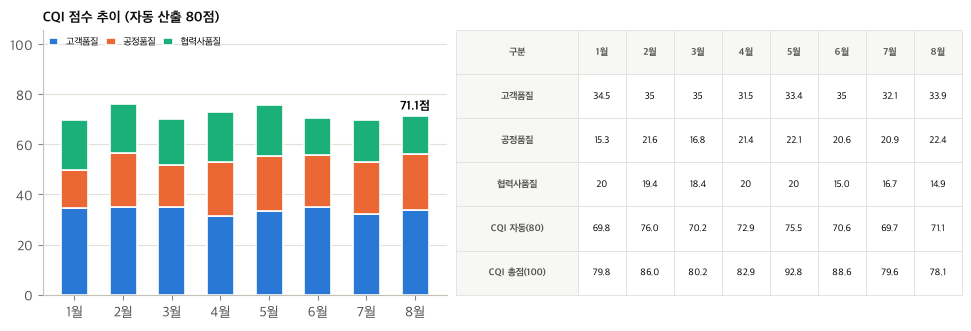

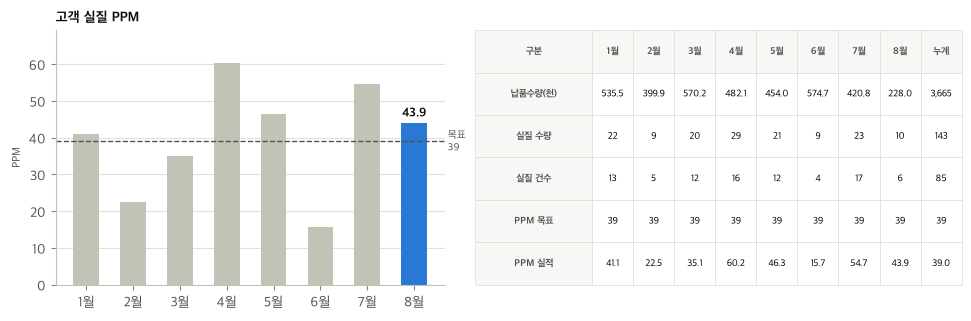

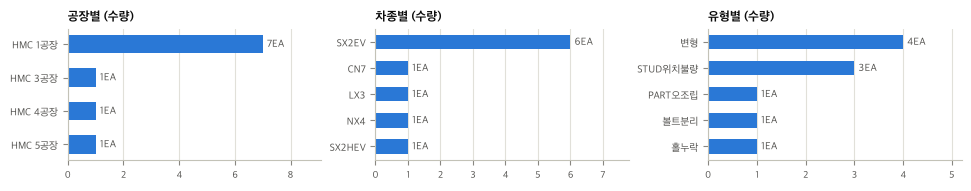

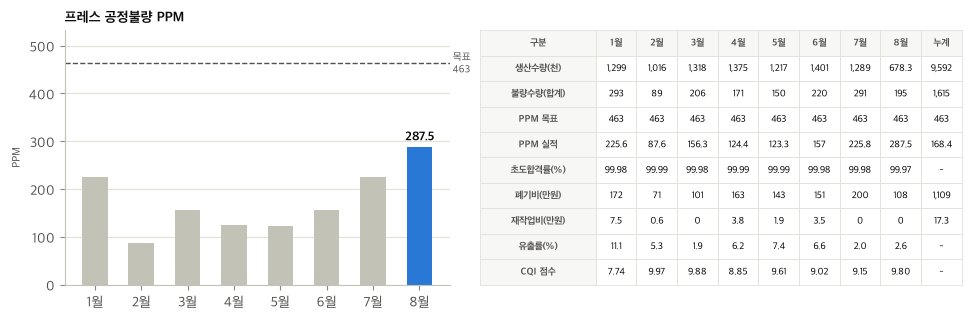

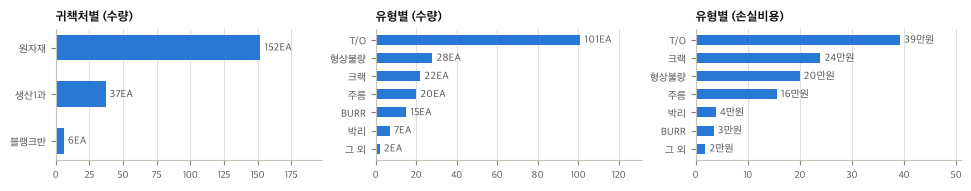

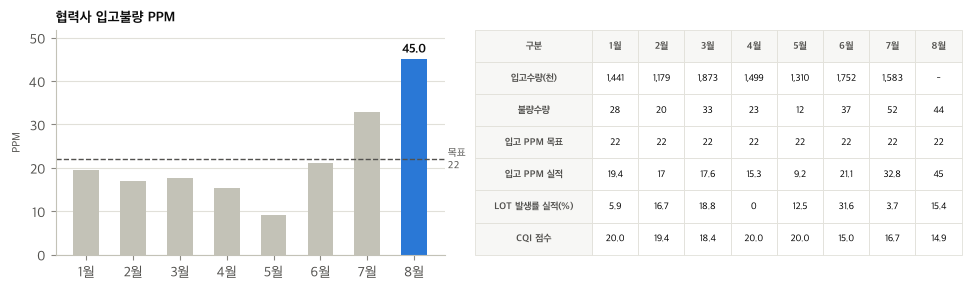

In [16]:
def month_labels(months):
    return [f'{m.month}월' for m in months]


def draw_trend(ax, values, target=None, unit='', title='', digits=1):
    values = pd.Series(values).reindex(REPORT_MONTHS).astype(float)
    x = np.arange(len(values))
    ax.bar(x, values.fillna(0).values, width=0.55, color=[ACCENT if m == RM else GRAY for m in values.index])
    if target is not None:
        ax.axhline(target, color=INK2, lw=1, ls='--')
        ax.annotate(f' 목표\n {target:,}', (1.0, target), xycoords=('axes fraction', 'data'), ha='left', va='center',
                    fontsize=7.5, color=INK2)
    v = values.get(RM)
    if pd.notna(v):
        ax.annotate(f'{v:,.{digits}f}', (x[-1], v), ha='center', va='bottom', fontsize=9, fontweight='bold', color=INK,
                    xytext=(0, 2), textcoords='offset points')
    ax.set_xticks(x, month_labels(values.index))
    ax.set_title(title, loc='left', fontsize=10)
    ax.set_ylabel(unit, fontsize=8)
    ax.margins(y=0.15)


def draw_stacked_scores(ax, parts, max_score, title=''):
    parts = parts.reindex(REPORT_MONTHS).astype(float)
    x = np.arange(len(parts))
    bottom = np.zeros(len(parts))
    for i, col in enumerate(parts.columns):
        vals = parts[col].fillna(0).values
        ax.bar(x, vals, bottom=bottom, width=0.55, color=PALETTE[i], edgecolor='white', linewidth=1.2, label=col)
        bottom += vals
    total = parts.sum(axis=1, min_count=1)
    if pd.notna(total.get(RM)):
        ax.annotate(f'{total[RM]:.1f}점', (x[-1], total[RM]), ha='center', va='bottom', fontsize=9, fontweight='bold',
                    xytext=(0, 2), textcoords='offset points')
    ax.set_ylim(0, max_score * 1.32)
    ax.set_xticks(x, month_labels(parts.index))
    ax.set_title(title, loc='left', fontsize=10)
    ax.legend(ncol=len(parts.columns), loc='upper left', fontsize=7, handlelength=1, columnspacing=0.8, borderaxespad=0.2)


def draw_hbar(ax, s, title='', unit='', digits=0, n=6):
    s = pd.Series(s).drop(['합계'], errors='ignore').astype(float)
    other = s.get('그 외')
    s = s.drop('그 외', errors='ignore')
    s = s[s > 0].sort_values(ascending=False).head(n)
    if other is not None and other > 0:
        s['그 외'] = other
    s = s[::-1]
    ax.set_title(title, loc='left', fontsize=9)
    if s.empty:
        ax.text(0.5, 0.5, '해당 없음', ha='center', va='center', transform=ax.transAxes, color=MUTED)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        return
    y = np.arange(len(s))
    ax.barh(y, s.values, height=0.55, color=ACCENT)
    for yi, v in zip(y, s.values):
        ax.annotate(f'{v:,.{digits}f}{unit}', (v, yi), xytext=(3, 0), textcoords='offset points', va='center', fontsize=7.5, color=INK2)
    ax.set_yticks(y, [str(i)[:14] for i in s.index], fontsize=7.5)
    ax.grid(axis='x'); ax.grid(axis='y', visible=False)
    ax.set_xlim(0, s.max() * 1.3)
    ax.tick_params(axis='x', labelsize=7)


def draw_table(ax, table, digits=None, fontsize=7):
    ax.axis('off')
    digits = digits or {}

    def fmt(v, row):
        if isinstance(v, str):
            return v
        if pd.isna(v):
            return '-'
        d = digits.get(row, 0 if (abs(v) >= 1000 or float(v).is_integer()) else 1)
        return f'{v:,.{d}f}'

    cells = [[str(row)] + [fmt(v, row) for v in table.loc[row]] for row in table.index]
    n = len(table.columns)
    widths = [0.24] + [0.76 / n] * n
    tb = ax.table(cellText=cells, colLabels=['구분'] + list(table.columns), colWidths=widths,
                  cellLoc='center', bbox=[0, 0, 1, 1])
    tb.auto_set_font_size(False)
    tb.set_fontsize(fontsize)
    for (r, c), cell in tb.get_celld().items():
        cell.set_edgecolor(GRID)
        cell.set_linewidth(0.6)
        if r == 0 or c == 0:
            cell.set_text_props(color=INK2, fontweight='bold')
            cell.set_facecolor('#f7f7f5')


def fig_trend_with_table(values, target, unit, title, table, size=(9.6, 3.1), digits=None, stacked=None, max_score=None, label_digits=1):
    fig = plt.figure(figsize=size, layout='constrained')
    gs = fig.add_gridspec(1, 2, width_ratios=[1.0, 1.25])
    ax = fig.add_subplot(gs[0])
    if stacked is not None:
        draw_stacked_scores(ax, stacked, max_score, title)
    else:
        draw_trend(ax, values, target, unit, title, label_digits)
    draw_table(fig.add_subplot(gs[1]), table, digits)
    return fig


def fig_items(panels, size=(9.6, 1.8)):
    fig, axes = plt.subplots(1, len(panels), figsize=size, layout='constrained')
    for ax, (title, s, unit, digits) in zip(np.atleast_1d(axes), panels):
        draw_hbar(ax, s, title, unit, digits)
    return fig


def short_table(t, rows):
    t = t.loc[[r for r in rows if r in t.index]].copy()
    names = []
    for row in t.index:
        vals = pd.to_numeric(t.loc[row], errors='coerce')
        if '(원)' in row:
            t.loc[row] = vals / 1e4
            names.append(row.replace('(원)', '(만원)'))
        elif vals.abs().max() >= 100000:
            t.loc[row] = vals / 1e3
            names.append(f'{row}(천)')
        else:
            names.append(row)
    t.index = names
    return t


k_cus = R['S06_고객실질_월별']
FIGS = {
    'CQI_종합': lambda size=(9.6, 3.2): fig_trend_with_table(
        None, None, '점', f"CQI 점수 추이 (자동 산출 {CAT_WEIGHT['CQI_자동(80)']}점)", monthly_table({'고객품질': TOTALS['고객품질'], '공정품질': TOTALS['공정품질'],
            '협력사품질': TOTALS['협력사품질'], 'CQI 자동(80)': TOTALS['CQI_자동(80)'], 'CQI 총점(100)': TOTALS['CQI_총점(100)']}),
        size, stacked=TOTALS[['고객품질', '공정품질', '협력사품질']], max_score=CAT_WEIGHT['CQI_자동(80)']),
    '고객_CQI': lambda size=(9.6, 3.1): fig_trend_with_table(
        None, None, '점', f"고객품질 CQI 점수 ({CAT_WEIGHT['고객품질']}점)", R['S04_고객_월별'], size,
        stacked=SCORE[['고객_등록PPM', '고객_실질PPM', '고객_등록률']].set_axis(['고객불량(등록)', '고객실질', '고객등록률'], axis=1), max_score=CAT_WEIGHT['고객품질']),
    '고객등록_월별': lambda size=(9.6, 3.1): fig_trend_with_table(
        ACT['고객_등록PPM'], IND.at['고객_등록PPM', '목표'], 'PPM', '고객 등록 PPM',
        short_table(R['S05_고객등록_월별'], list(R['S05_고객등록_월별'].index)), size),
    '고객실질_월별': lambda size=(9.6, 3.1): fig_trend_with_table(
        ACT['고객_실질PPM'], IND.at['고객_실질PPM', '목표'], 'PPM', '고객 실질 PPM', short_table(k_cus, list(k_cus.index)), size),
    '고객실질_항목별': lambda size=(9.6, 1.8): fig_items([
        ('공장별 (수량)', R['S06_고객실질_공장별']['수량'], 'EA', 0), ('차종별 (수량)', R['S06_고객실질_차종별']['수량'], 'EA', 0),
        ('유형별 (수량)', R['S06_고객실질_유형별']['수량'], 'EA', 0)], size),
    '고객등록_항목별': lambda size=(9.6, 1.8): fig_items([('공장별', pd.Series(dtype=float), '', 0), ('차종별', pd.Series(dtype=float), '', 0),
                                                         ('유형별', pd.Series(dtype=float), '', 0)], size),
    '공정_CQI': lambda size=(9.6, 2.8): fig_trend_with_table(
        None, None, '점', f"공정품질 CQI 점수 ({CAT_WEIGHT['공정품질']}점)", R['S07_공정_월별'], size,
        stacked=TOTALS[['공정품질_블랭크', '공정품질_프레스', '공정품질_조립']].set_axis(['블랭크', '프레스', '조립'], axis=1), max_score=CAT_WEIGHT['공정품질']),
    '협력사_월별': lambda size=(9.6, 2.8): fig_trend_with_table(
        ACT['협력사_입고PPM'], IND.at['협력사_입고PPM', '목표'], 'PPM', '협력사 입고불량 PPM',
        short_table(R['S11_협력사_월별'], ['입고수량', '불량수량', '입고 PPM 목표', '입고 PPM 실적', 'LOT 발생률 실적(%)', 'CQI 점수']), size,
        digits={'CQI 점수': 1}),
    '협력사_항목별': lambda size=(9.6, 1.8): fig_items([
        ('협력사별 (수량)', R['S11_협력사_협력사별']['수량'], 'EA', 0), ('차종별 (수량)', R['S11_협력사_차종별']['수량'], 'EA', 0),
        ('유형별 (수량)', R['S11_협력사_유형별']['수량'], 'EA', 0)], size),
}
FIGS['예방_월별'] = lambda size=(9.6, 2.6): fig_trend_with_table(
    None, None, '점', f"예방품질 CQI 점수 ({CAT_WEIGHT['예방품질']}점, 수기 입력값)", R['S12_예방품질'], size,
    stacked=MANUAL_SCORE[['예방_신차', '예방_양산']].set_axis(['신차', '양산'], axis=1), max_score=CAT_WEIGHT['예방품질'])
FIGS['품질비용_월별'] = lambda size=(9.6, 2.2): fig_trend_with_table(
    MANUAL_ACT['품질비용'], MANUAL_IND.at['품질비용', '목표'], '비율', '실패비용(Q-COST) 비율 (첨부3·수기 입력값)',
    R['S13_품질비용'], size, digits={'실패비용 비율': 3, '목표': 3, 'CQI 점수(품질비용)': 2}, label_digits=3)

for area in ['블랭크', '프레스', '조립']:
    no = {'블랭크': 'S08', '프레스': 'S09', '조립': 'S10'}[area]
    rows = ['생산수량', '불량수량(합계)', 'PPM 목표', 'PPM 실적', '초도합격률(%)', '폐기비(원)', '재작업비(원)', '유출률(%)', 'CQI 점수']
    FIGS[f'{area}_월별'] = (lambda size=(9.6, 3.1), a=area, n=no, rw=rows: fig_trend_with_table(
        ACT[f'{a}_PPM'], IND.at[f'{a}_PPM', '목표'], 'PPM', f'{a} 공정불량 PPM', short_table(R[f'{n}_{a}_월별'], rw), size,
        digits={'초도합격률(%)': 3 if a == '조립' else 2, 'CQI 점수': 2, '유출률(%)': 1, '폐기비(만원)': 0}))
    FIGS[f'{area}_항목별'] = (lambda size=(9.6, 1.8), a=area, n=no: fig_items([
        ('귀책처별 (수량)', R[f'{n}_{a}_귀책처별']['합계 수량'], 'EA', 0), ('유형별 (수량)', R[f'{n}_{a}_유형별']['수량'], 'EA', 0),
        ('유형별 (손실비용)', R[f'{n}_{a}_유형별']['금액'] / 1e4, '만원', 0)], size))

for name in ['CQI_종합', '고객실질_월별', '고객실질_항목별', '프레스_월별', '프레스_항목별', '협력사_월별']:
    fig = FIGS[name]()
    save_fig(fig, f'보고서_{RMS}_{name}')
    plt.show()

### 2-5. 첨부2 양식 PPT 채우기

첨부2 양식을 복사한 뒤 `python-pptx`로 숫자, 표, 그래프를 채웁니다. 글꼴, 크기, 색 같은 양식 서식은 그대로 두고 글자만 바꿉니다.

| 슬라이드 | 채우는 내용 |
|---|---|
| 1 | 본사 종합 CQI, 전월 대비, 전월 점수, ① 금월 평가(숫자 문장). ②③은 3장에서 채움. 경주는 `데이터 없음` |
| 2 | 대분류별 점수 상자, 표(당월 점수, 달성률, 상태), 달성률 막대그래프(`replace_data`) |
| 3 | 경주: `데이터 없음` |
| 4 | 고객품질 CQI와 지표 값, ① 금월 평가, 점수 추이 그림 |
| 5·6 | 고객 등록·실질 월별 그림, 항목별 그림, 상세표 |
| 7~11 | 공정, 블랭크, 프레스, 조립, 협력사 점수와 지표 값, 월별 그림과 항목별 그림, 공정 상세표 |
| 12·13 | 예방품질, 품질비용 점수. 첨부3 빈칸이라 0점으로 계산된 달은 `미입력`으로 표시 |

- 엑셀 개체(그래프) 자리에는 2-4에서 그린 그림을 같은 위치와 크기로 넣습니다.
- 슬라이드 10 소제목이 양식에 "프레스공정 항목별 분석"으로 되어 있는데, 오타로 보여 "조립공정 항목별 분석"으로 고쳤습니다.

In [17]:
try:
    from pptx import Presentation
    from pptx.oxml.ns import qn
    from pptx.dml.color import RGBColor
    from pptx.chart.data import CategoryChartData
    from pptx.util import Pt
    HAS_PPTX = True
except ImportError:
    HAS_PPTX = False
    print('python-pptx가 없어 PPT 만들기를 건너뜁니다. (conda project 환경에서 실행하거나 pip install python-pptx)')

EMU_PER_INCH = 914400


def write_paragraph(para, text, color=None, size=None):
    runs = para.runs
    if runs:
        runs[0].text = text
        for r in runs[1:]:
            r._r.getparent().remove(r._r)
        run = runs[0]
    else:
        end = para._p.find(qn('a:endParaRPr'))
        run = para.add_run()
        run.text = text
        if end is not None:
            rpr = run._r.get_or_add_rPr()
            for k, v in end.attrib.items():
                rpr.set(k, v)
            for child in end:
                rpr.append(copy.deepcopy(child))
    if color:
        run.font.color.rgb = RGBColor.from_string(color.lstrip('#'))
    if size:
        run.font.size = Pt(size)
    return run


def set_text(shape_or_cell, text, color=None, size=None):
    tf = shape_or_cell.text_frame
    first = tf.paragraphs[0]
    for p in tf.paragraphs[1:]:
        p._p.getparent().remove(p._p)
    template = copy.deepcopy(first._p)
    lines = str(text).split('\n')
    write_paragraph(first, lines[0], color, size)
    for line in lines[1:]:
        new_p = copy.deepcopy(template)
        tf._txBody.append(new_p)
        write_paragraph(tf.paragraphs[-1], line, color, size)


def shape(slide, name):
    found = [s for s in slide.shapes if s.name == name]
    if not found:
        raise KeyError(f'도형 없음: {name}')
    return found[0]


def put(slide, name, text, color=None, size=None):
    set_text(shape(slide, name), text, color, size)


def replace_with_picture(slide, name, fig_func):
    sh = shape(slide, name)
    left, top, width, height = sh.left, sh.top, sh.width, sh.height
    fig = fig_func(size=(width / EMU_PER_INCH, height / EMU_PER_INCH))
    buf = io.BytesIO()
    with plt.rc_context({'savefig.bbox': 'standard'}):
        fig.savefig(buf, format='png', dpi=200)
    plt.close(fig)
    buf.seek(0)
    remove_ole(slide, sh)
    slide.shapes.add_picture(buf, left, top, width, height)


def remove_ole(slide, sh):
    el = sh._element
    rids = set(el.xpath('.//@r:id | .//@r:embed'))
    el.getparent().remove(el)
    for rid in rids:
        slide.part.drop_rel(rid)
    if not slide._element.xpath('.//p:oleObj'):
        for rid, rel in list(slide.part.rels.items()):
            if rel.reltype.endswith('/vmlDrawing'):
                slide.part.drop_rel(rid)


def remove_shape(slide, name):
    for s in [s for s in slide.shapes if s.name == name]:
        s._element.getparent().remove(s._element)


def fill_table(table, df, columns, max_rows=4, note_col='현상'):
    tbl = table._tbl
    if len(df) > max_rows:
        rest = len(df) - max_rows
        df = df.head(max_rows).copy()
        df.iloc[-1, df.columns.get_loc(note_col)] = f"{df.iloc[-1][note_col]}  (외 {rest}건: 데이터 엑셀 참고)"
    n_body = max(len(df), 1)
    while len(tbl.tr_lst) - 1 < n_body:
        tbl.append(copy.deepcopy(tbl.tr_lst[-1]))
    while len(tbl.tr_lst) - 1 > n_body:
        tbl.remove(tbl.tr_lst[-1])
    for i in range(n_body):
        for j, col in enumerate(columns):
            value = '' if i >= len(df) or col is None else df.iloc[i][col]
            set_text(table.cell(i + 1, j), '' if pd.isna(value) else str(value))


fmt_score = lambda v, w: '-' if pd.isna(v) else f'{v:.1f} / {w}점'
fmt_prev = lambda v: '전월 -' if pd.isna(v) else f'전월 {v:.1f}점'


def is_blank(key, month):
    return blank_manual(key, month) if key in MANUAL_IND.index else manual_blank(key, month)


def score_text(key, month=None):
    month = RM if month is None else month
    w = MANUAL_IND.at[key, '배점'] if key in MANUAL_IND.index else CAT_WEIGHT[key]
    v = value_at(MANUAL_SCORE if key in MANUAL_IND.index else TOTALS, month, key)
    return f'미입력 / {w}점' if is_blank(key, month) else fmt_score(v, w)


def prev_text(key):
    if is_blank(key, PM):
        return '전월 미입력'
    return fmt_prev(value_at(MANUAL_SCORE if key in MANUAL_IND.index else TOTALS, PM, key))


def fmt_value(v, unit, digits=1):
    if pd.isna(v):
        return '-'
    if unit == 'PPM':
        return f'{v:,.{digits}f} PPM'
    if unit == '%':
        return f'{v:.{digits}f}%'
    if unit == '만원':
        return f'{v / 1e4:,.0f}만원'
    return f'{v:,.{digits}f}'


def eval_sentence(label, cur, prev):
    if pd.isna(cur):
        return f'{label} 산출 불가 (데이터 대기)'
    if pd.isna(prev):
        return f'{label} {cur:.1f}점'
    d = cur - prev
    word = '개선' if d > 0.05 else ('악화' if d < -0.05 else '전월과 비슷')
    return f'{label} {cur:.1f}점으로 전월 대비 {abs(d):.1f}점 {word}'


def period_text(months):
    last_day = months[-1].to_timestamp(how='end').day
    return f'집계기간 : {months[0].year % 100}/{months[0].month}/1 ~ {months[-1].month}/{last_day}'


PPT_PATH = OUT['report'] / f'월품질실적보고_자동_{RMS}.pptx'
TEMPLATE = FILES['월보고 양식(첨부2)'][-1] if FILES['월보고 양식(첨부2)'] else None


def build_ppt(texts=None):
    texts = texts or {}
    prs = Presentation(str(TEMPLATE))
    S = prs.slides
    total_label = 'CQI_총점(100)' if pd.notna(value_at(TOTALS, RM, 'CQI_총점(100)')) else 'CQI_자동(80)'
    total_cur, total_prev = value_at(TOTALS, RM, total_label), value_at(TOTALS, PM, total_label)
    pick = lambda k, m=RM: value_at(TOTALS, m, k)

    for s in S:
        for sh in s.shapes:
            if sh.has_text_frame and sh.text_frame.text.strip().startswith('집계기간'):
                set_text(sh, period_text(REPORT_MONTHS))

    s1 = S[0]
    put(s1, 'TextBox 14', '-' if pd.isna(total_cur) else f'{total_cur:.1f}점')
    put(s1, 'TextBox 15', f'{CAT_WEIGHT[total_label]}점 만점' if total_label == 'CQI_총점(100)' else f'{CAT_WEIGHT[total_label]}점 기준 (예방·비용 제외)')
    put(s1, 'TextBox 23', arrow(total_cur - total_prev) + ('점' if pd.notna(total_cur - total_prev) else ''))
    put(s1, 'TextBox 24', fmt_prev(total_prev))
    put(s1, 'TextBox 37', texts.get('금월평가', eval_sentence('CQI', total_cur, total_prev)), size=10 if '금월평가' in texts else None)
    put(s1, 'TextBox 67', texts.get('개선성과', '(3장 AI 분석 평가에서 작성)'), size=9 if '개선성과' in texts else None)
    put(s1, 'TextBox 68', texts.get('주요이슈', '(3장 AI 분석 평가에서 작성)'), size=9 if '주요이슈' in texts else None)
    for name, txt in [('TextBox 61', '-'), ('TextBox 62', '데이터 없음'), ('TextBox 64', '-'), ('TextBox 65', '전월 -'),
                      ('TextBox 71', '경주 공정·협력사 데이터 미수령 (데이터 대기)'), ('TextBox 78', '-'), ('TextBox 79', '-')]:
        put(s1, name, txt)
    for memo in ['직사각형 2', '직사각형 4']:
        remove_shape(s1, memo)

    s2 = S[1]
    for (box, prev_box), key in [(('TextBox 14', 'TextBox 15'), '고객품질'), (('TextBox 67', 'TextBox 68'), '공정품질'),
                                 (('TextBox 69', 'TextBox 70'), '협력사품질'), (('TextBox 71', 'TextBox 72'), '예방품질'),
                                 (('TextBox 73', 'TextBox 74'), '품질비용')]:
        put(s2, box, score_text(key))
        put(s2, prev_box, prev_text(key))
    tbl = shape(s2, 'Table 3').table
    for i, key in enumerate(['고객품질', '공정품질', '협력사품질', '예방품질', '품질비용', 'CQI_총점(100)'], start=1):
        w = CAT_WEIGHT[key]
        v = pick(key)
        set_text(tbl.cell(i, 2), '-' if pd.isna(v) else f'{v:.1f}')
        set_text(tbl.cell(i, 3), '-' if pd.isna(v) else f'{v / w:.0%}')
        if key != 'CQI_총점(100)':
            st = '미입력' if manual_blank(key, RM) else status_of(v / w if pd.notna(v) else np.nan)
            set_text(tbl.cell(i, 4), f'● {st}' if st != '-' else '-', STATUS_COLOR.get(st))
    chart_cats = ['품질비용', '예방품질', '협력사품질', '공정품질', '고객품질']
    cd = CategoryChartData()
    cd.categories = chart_cats
    cd.add_series('달성률', [0 if pd.isna(pick(k)) else round(pick(k) / CAT_WEIGHT[k], 3) for k in chart_cats])
    chart = shape(s2, 'Chart 4').chart
    chart.replace_data(cd)
    labels = chart.plots[0].series[0].data_labels
    labels.number_format = '0%'
    labels.number_format_is_linked = False

    s3 = S[2]
    for box in ['TextBox 14', 'TextBox 67', 'TextBox 69', 'TextBox 71', 'TextBox 73']:
        put(s3, box, '-')
    for box in ['TextBox 15', 'TextBox 68', 'TextBox 70', 'TextBox 72', 'TextBox 74']:
        put(s3, box, '데이터 없음')
    tbl3 = shape(s3, 'Table 3').table
    for i in range(1, 7):
        for j in (2, 3, 4):
            set_text(tbl3.cell(i, j), '-')
    cd3 = CategoryChartData()
    cd3.categories = chart_cats
    cd3.add_series('달성률', [0] * len(chart_cats))
    shape(s3, 'Chart 4').chart.replace_data(cd3)

    s4 = S[3]
    put(s4, 'TextBox 28', score_text('고객품질')); put(s4, 'TextBox 32', prev_text('고객품질'))
    put(s4, 'TextBox 42', fmt_value(ACT.at[RM, '고객_등록PPM'], 'PPM'))
    put(s4, 'TextBox 43', fmt_value(ACT.at[RM, '고객_실질PPM'], 'PPM'))
    put(s4, 'TextBox 44', fmt_value(ACT.at[RM, '고객_등록률'], '%'))
    put(s4, 'TextBox 47', texts.get('고객평가', eval_sentence('고객품질 CQI', pick('고객품질'), pick('고객품질', PM))))
    replace_with_picture(s4, '개체 1', FIGS['고객_CQI'])

    s5, s6 = S[4], S[5]
    replace_with_picture(s5, '개체 11', FIGS['고객등록_월별'])
    replace_with_picture(s5, '개체 17', FIGS['고객등록_항목별'])
    fill_table(shape(s5, '표 8').table, pd.DataFrame([{'순': 1, '일자': '-', '공장': '-', '차종': '-', 'ITEM명': '당월 고객 등록 불량 없음',
                                                      '문제점': '-', '현상': '-', '수량': '0EA', '개선방안': '', '일정': ''}]),
               ['순', '일자', '공장', '차종', 'ITEM명', '문제점', '현상', '수량', '개선방안', '일정'])
    replace_with_picture(s6, '개체 10', FIGS['고객실질_월별'])
    replace_with_picture(s6, '개체 13', FIGS['고객실질_항목별'])
    fill_table(shape(s6, '표 8').table, R['S06_고객실질_상세'],
               ['순', '일자', '공장', '차종', 'ITEM명', '문제점', '현상', '수량', '개선방안', '일정'])

    s7 = S[6]
    put(s7, 'TextBox 5', score_text('공정품질')); put(s7, 'TextBox 6', prev_text('공정품질'))
    for (box, prev_box), key in [(('TextBox 19', 'TextBox 20'), '공정품질_블랭크'), (('TextBox 21', 'TextBox 22'), '공정품질_프레스'),
                                 (('TextBox 23', 'TextBox 24'), '공정품질_조립')]:
        put(s7, box, score_text(key)); put(s7, prev_box, prev_text(key))
    replace_with_picture(s7, '개체 1', FIGS['공정_CQI'])
    fill_table(shape(s7, '표 30').table, R['S07_공정_상세'], ['순', '일자', '차종', 'ITEM명', '문제점', '현상', '수량', '개선방안', '일정'])

    for idx, area in [(7, '블랭크'), (8, '프레스'), (9, '조립')]:
        s = S[idx]
        put(s, 'TextBox 5', score_text(f'공정품질_{area}')); put(s, 'TextBox 6', prev_text(f'공정품질_{area}'))
        put(s, 'TextBox 19', fmt_value(ACT.at[RM, f'{area}_PPM'], 'PPM'))
        put(s, 'TextBox 20', '전월 ' + fmt_value(value_at(ACT, PM, f'{area}_PPM'), 'PPM'))
        digits = 3 if area == '조립' else 2
        put(s, 'TextBox 21', fmt_value(ACT.at[RM, f'{area}_초도'], '%', digits))
        put(s, 'TextBox 22', '전월 ' + fmt_value(value_at(ACT, PM, f'{area}_초도'), '%', digits))
        loss = lambda m: value_at(ACT, m, f'{area}_폐기비') + value_at(ACT, m, f'{area}_재작업비') if area != '블랭크' else value_at(ACT, m, f'{area}_폐기비')
        put(s, 'TextBox 23', fmt_value(loss(RM), '만원')); put(s, 'TextBox 24', '전월 ' + fmt_value(loss(PM), '만원'))
        if area != '블랭크':
            put(s, 'TextBox 33', fmt_value(ACT.at[RM, f'{area}_유출률'], '%', 2))
        replace_with_picture(s, '개체 1', FIGS[f'{area}_월별'])
        replace_with_picture(s, '개체 28' if area == '블랭크' else '개체 36', FIGS[f'{area}_항목별'])
    put(S[9], 'TextBox 7', '3-3-2. 조립공정 항목별 분석')

    s11 = S[10]
    put(s11, 'TextBox 5', score_text('협력사품질')); put(s11, 'TextBox 6', prev_text('협력사품질'))
    put(s11, 'TextBox 19', fmt_value(ACT.at[RM, '협력사_입고PPM'], 'PPM'))
    put(s11, 'TextBox 20', '전월 ' + fmt_value(value_at(ACT, PM, '협력사_입고PPM'), 'PPM'))
    put(s11, 'TextBox 21', fmt_value(ACT.at[RM, '협력사_LOT률'], '%'))
    put(s11, 'TextBox 22', '전월 ' + fmt_value(value_at(ACT, PM, '협력사_LOT률'), '%'))
    replace_with_picture(s11, '개체 1', FIGS['협력사_월별'])
    replace_with_picture(s11, '개체 37', FIGS['협력사_항목별'])

    s12, s13 = S[11], S[12]
    put(s12, 'TextBox 5', score_text('예방품질')); put(s12, 'TextBox 6', prev_text('예방품질'))
    for box, prev_box, k in [('TextBox 19', 'TextBox 20', '예방_신차'), ('TextBox 21', 'TextBox 22', '예방_양산')]:
        put(s12, box, score_text(k)); put(s12, prev_box, prev_text(k))
    remove_shape(s12, '직사각형 24')
    replace_with_picture(s12, '개체 1', FIGS['예방_월별'])
    put(s13, 'TextBox 5', score_text('품질비용')); put(s13, 'TextBox 6', prev_text('품질비용'))
    put(s13, 'TextBox 19', fmt_value(value_at(MANUAL_ACT, RM, '품질비용'), '', 3))
    put(s13, 'TextBox 20', '전월 ' + fmt_value(value_at(MANUAL_ACT, PM, '품질비용'), '', 3))
    replace_with_picture(s13, '개체 1', FIGS['품질비용_월별'])

    prs.save(PPT_PATH)
    return PPT_PATH


if HAS_PPTX and TEMPLATE is not None:
    path = build_ppt()
    print('PPT 저장:', path.relative_to(PROJECT_DIR))

PPT 저장: output/report/월품질실적보고_자동_202608.pptx


---
## 3. "AI 분석 평가" 문구


| 칸 | 양식 예시 문구 | 여기서 만드는 내용 |
|---|---|---|
| ① 금월 평가 | CQI ○○점으로 전월 대비 ○○점 개선/악화 | 점수와 증감, 올해 평균 및 최근 순위와 비교 |
| ② 개선성과 | ○○ 불량 및 손실비용 감소로 점수 개선 | 점수를 올린 지표와 원인(어느 공장, 유형, 라인에서 몇 건 줄었는지) |
| ③ 주요이슈 | 고객품질 ○○, 공정품질 ○○에서 변동 발생 | 점수를 깎은 지표와 원인, 과거 추이에 비해 이례적인 변화 |

- 다음 달 CQI 전망은 요청에 따라 넣지 않았습니다.
- 방법: 직접 요약·원인 분석(규칙 기반). CQI는 지표 점수의 합이라 점수 변화를 지표별로 정확히 나눌 수 있습니다. 그 뒤 지표별 원천 데이터를 공장, 유형, 라인별로 나눠 원인을 찾습니다.
- 문구는 아래 규칙으로 만들며 생성형 AI는 쓰지 않습니다.

### 3-1. 전월 대비 점수 변화를 지표별로 나누기

$\Delta \mathrm{CQI} = \sum_i \Delta S_i$ 이므로 지표별 점수 변화 $\Delta S_i$ 가 곧 기여도입니다. 근사값이 아니라 정확히 나뉩니다.

2026-07 → 2026-08  CQI 총점 변화 -1.46점 = 지표별 변화의 합 -1.46점


,지표키,지표,전월 실적,당월 실적,전월 점수,당월 점수,점수 변화
20,품질비용,품질비용,0.056,0.079,9.911,7.000,-2.911
16,협력사_입고PPM,협력사 입고불량 PPM,32.800,45.000,6.707,4.889,-1.818
14,조립_폐기비,조립 폐기비,134445.000,375235.000,1.000,0.257,-0.743
3,블랭크_PPM,블랭크 공정불량 PPM,603.200,835.900,1.652,0.977,-0.674
4,블랭크_초도,블랭크 초도합격률,99.940,99.920,0.820,0.760,-0.060
7,프레스_초도,프레스 초도합격률,99.980,99.970,0.940,0.910,-0.030
12,조립_초도,조립 초도합격률,99.997,99.992,0.991,0.976,-0.015
5,블랭크_폐기비,블랭크 폐기비,5266085.000,4419133.000,1.251,1.596,0.346
9,프레스_폐기비,프레스 폐기비,2001805.000,1079051.000,0.206,0.895,0.689
1,고객_실질PPM,고객실질 PPM,54.700,43.900,7.130,8.884,1.754


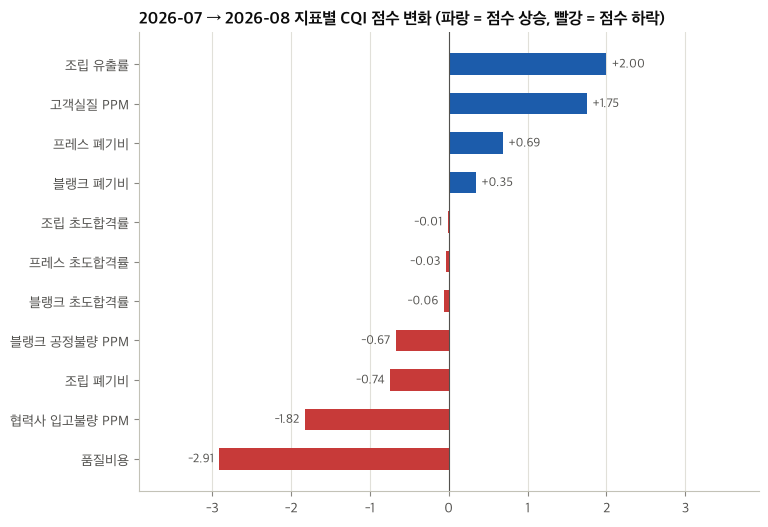

In [18]:
LABEL = {}
for k, r in pd.concat([IND, MANUAL_IND]).iterrows():
    if r['세부'] == '고객':
        LABEL[k] = r['지표명'] + (' PPM' if r['단위'] == 'PPM' else '')
    elif r['대분류'] in ('예방품질', '품질비용'):
        LABEL[k] = r['대분류'] if r['대분류'] == '품질비용' else f"예방품질({r['세부']})"
    else:
        LABEL[k] = f"{r['세부']} {r['지표명']}" + (' PPM' if r['단위'] == 'PPM' else '')


def score_changes(cur, prev):
    rows = []
    for k in list(IND.index) + list(MANUAL_IND.index):
        sc = SCORE if k in IND.index else MANUAL_SCORE
        ac = ACT if k in IND.index else MANUAL_ACT
        rows.append({'지표키': k, '지표': LABEL[k], '전월 실적': value_at(ac, prev, k), '당월 실적': value_at(ac, cur, k),
                     '전월 점수': value_at(sc, prev, k), '당월 점수': value_at(sc, cur, k)})
    t = pd.DataFrame(rows)
    t['점수 변화'] = t['당월 점수'] - t['전월 점수']
    return t


DELTA = score_changes(RM, PM)
print(f"{PM} → {RM}  CQI 총점 변화 {TOTALS.at[RM, 'CQI_총점(100)'] - TOTALS.at[PM, 'CQI_총점(100)']:+.2f}점 "
      f"= 지표별 변화의 합 {DELTA['점수 변화'].sum():+.2f}점")
display(DELTA[DELTA['점수 변화'].abs() > 0.005].sort_values('점수 변화').round(3))

d = DELTA[DELTA['점수 변화'].abs() > 0.005].sort_values('점수 변화')
fig, ax = plt.subplots(figsize=(8, 0.45 * len(d) + 1))
ax.barh(d['지표'], d['점수 변화'], height=0.55, color=[DIV_CMAP(0.0) if v > 0 else DIV_CMAP(1.0) for v in d['점수 변화']])
for y, v in enumerate(d['점수 변화']):
    ax.annotate(f'{v:+.2f}', (v, y), xytext=(4 if v > 0 else -4, 0), textcoords='offset points',
                ha='left' if v > 0 else 'right', va='center', fontsize=9, color=INK2)
ax.axvline(0, color=INK2, lw=0.8)
ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.set_title(f'{PM} → {RM} 지표별 CQI 점수 변화 (파랑 = 점수 상승, 빨강 = 점수 하락)', loc='left')
lim = d['점수 변화'].abs().max() * 1.35
ax.set_xlim(-lim, lim)
save_fig(fig, f'AI평가_{RMS}_지표별점수변화'); plt.show()

### 3-2. 불량 효과와 물량 효과 나누기 (섀플리 분해)

PPM은 불량 수량 ÷ 생산(납품, 입고) 수량이라서 불량이 그대로여도 생산량이 줄면 올라갑니다. 26년 8월은 7월보다 고객 납품량이 46%, 블랭크·프레스 생산량이 48%·47% 줄어 절반 가까이 되었고, 조립 생산량은 비슷했습니다(+0.5%). 이 영향이 컸습니다(요구사항 8장 7번, 회사 확인 필요).

점수 변화를 분자(불량) 효과와 분모(물량) 효과로 나눌 때 2인 섀플리 값을 썼습니다. 분자와 분모 중 무엇을 먼저 바꾸느냐에 따라 결과가 달라지기 때문에 두 순서의 평균을 냅니다.

$$\phi_{\text{불량}} = \tfrac12\big[S(n_1,d_0)-S(n_0,d_0)\big] + \tfrac12\big[S(n_1,d_1)-S(n_0,d_1)\big],\qquad \phi_{\text{물량}} = \Delta S - \phi_{\text{불량}}$$

$n$은 분자, $d$는 분모, 0은 전월, 1은 당월, $S$는 반올림까지 포함한 점수 함수입니다. 두 효과를 더하면 점수 변화와 정확히 같습니다.

| 지표 | 분자 $n$ | 분모 $d$ |
|---|---|---|
| PPM·초도합격률 | 불량 수량 | 생산·납품·입고 수량 |
| 유출률 | 다음 공정에서 발견된 건수 | 자기 공정 검출 건수 |
| LOT 발생률 | LOT 건수 | 협력사 불량 건수 |

8월처럼 입고수량이 없는 달의 입고불량 PPM은 회사값으로 분모를 역산(불량 수량 ÷ PPM)해서 나눕니다. 역산한 입고수량은 회사가 우리와 같은 불량 수량으로 PPM을 계산했다고 가정한 추정값입니다. 그래서 표에 `분모 출처`를 따로 적고, 물량 효과 합계도 원천 수량에서 나온 부분과 역산값에서 나온 부분을 나눠 보여 줍니다. 3-5 문구에는 역산한 입고수량의 변화율을 쓰지 않습니다.

In [19]:
ppm = lambda n, d: n / d * 1e6
FACTORS = {
    '고객_실질PPM':   ('고객_실질수량', '고객_납품수량', '고객실질 수량', '납품수량', ppm),
    '블랭크_PPM':     ('블랭크_불량수량', '블랭크_생산수량', '블랭크 불량수량', '블랭크 생산수량', ppm),
    '블랭크_초도':    ('블랭크_불량수량', '블랭크_생산수량', '블랭크 불량수량', '블랭크 생산수량', lambda n, d: 100 - n / d * 100),
    '프레스_PPM':     ('프레스_불량수량', '프레스_생산수량', '프레스 불량수량', '프레스 생산수량', ppm),
    '프레스_초도':    ('프레스_불량수량', '프레스_생산수량', '프레스 불량수량', '프레스 생산수량', lambda n, d: 100 - n / d * 100),
    '프레스_유출률':  ('프레스_유출건수', '프레스_불량건수', '조립에서 발견된 프레스 귀책 건수', '프레스 자체 검출 건수', lambda a, b: a / (a + b) * 100),
    '조립_PPM':       ('조립_불량수량', '조립_생산수량', '조립 불량수량', '조립 생산수량', ppm),
    '조립_초도':      ('조립_불량수량', '조립_생산수량', '조립 불량수량', '조립 생산수량', lambda n, d: 100 - n / d * 100),
    '조립_유출률':    ('조립_유출건수', '조립_불량건수', '고객에서 발견된 본사 건수', '조립 자체 검출 건수', lambda a, b: a / (a + b) * 100),
    '협력사_입고PPM': ('협력사_불량수량', '협력사_입고수량', '협력사 불량수량', '협력사 입고수량', ppm),
    '협력사_LOT률':   ('협력사_LOT건수', '협력사_불량건수', 'LOT 건수', '협력사 불량 건수', lambda a, b: a / b * 100),
}


def factor_values(month, key):
    num_col, den_col = FACTORS[key][:2]
    n, d = ACT_RAW.at[month, num_col], ACT_RAW.at[month, den_col]
    src = '원천'
    if pd.isna(d) and key == '협력사_입고PPM' and pd.notna(ACT.at[month, key]) and ACT.at[month, key] > 0:
        d, src = n / ACT.at[month, key] * 1e6, '역산(회사 PPM)'
    return n, d, src


def score_from_factors(key, n, d):
    f = FACTORS[key][4]
    with np.errstate(divide='ignore', invalid='ignore'):
        x = f(n, d)
    x = 0.0 if (pd.isna(x) and key.endswith('유출률')) else x
    x = float(excel_round([x], int(IND.at[key, '반올림']))[0])
    return cqi_score(x, IND.at[key, '점수방식'], IND.at[key, '배점'], IND.at[key, '목표'])


def shapley_two(key, cur, prev):
    n0, d0, src0 = factor_values(prev, key)
    n1, d1, src1 = factor_values(cur, key)
    S = lambda n, d: score_from_factors(key, n, d)
    phi_n = 0.5 * (S(n1, d0) - S(n0, d0)) + 0.5 * (S(n1, d1) - S(n0, d1))
    total = S(n1, d1) - S(n0, d0)
    return {'분자': FACTORS[key][2], '분자 전월': n0, '분자 당월': n1, '분모': FACTORS[key][3], '분모 전월': d0, '분모 당월': d1,
            '불량(분자) 효과': phi_n, '물량(분모) 효과': total - phi_n, '점수 변화': total,
            '분모 출처': src1 if src1 != '원천' else src0}


def factor_table(cur, prev):
    rows = []
    for key in FACTORS:
        r = shapley_two(key, cur, prev)
        rows.append({'지표키': key, '지표': LABEL[key], **r})
    t = pd.DataFrame(rows)
    t['분모 변화율'] = t['분모 당월'] / t['분모 전월'] - 1
    return t


FACT = factor_table(RM, PM)
moved = (FACT[['불량(분자) 효과', '물량(분모) 효과']].abs() > 0.005).any(axis=1)
display(FACT[moved].drop(columns='지표키').round(3))

is_volume = ~FACT['지표키'].str.endswith(('유출률', 'LOT률'))
estimated = FACT['분모 출처'] != '원천'
print(f"물량(분모) 효과 합계 {FACT.loc[is_volume, '물량(분모) 효과'].sum():+.2f}점 = "
      f"원천 생산·납품·입고수량 {FACT.loc[is_volume & ~estimated, '물량(분모) 효과'].sum():+.2f}점 + "
      f"회사 PPM으로 역산한 입고수량 {FACT.loc[is_volume & estimated, '물량(분모) 효과'].sum():+.2f}점")

,지표,분자,분자 전월,분자 당월,분모,분모 전월,분모 당월,불량(분자) 효과,물량(분모) 효과,점수 변화,분모 출처,분모 변화율
0,고객실질 PPM,고객실질 수량,23.0,10.0,납품수량,420793.0,227987.000,3.944,-2.190,1.754,원천,-0.458
1,블랭크 공정불량 PPM,블랭크 불량수량,813.0,583.0,블랭크 생산수량,1347806.0,697426.000,0.652,-1.327,-0.674,원천,-0.483
2,블랭크 초도합격률,블랭크 불량수량,813.0,583.0,블랭크 생산수량,1347806.0,697426.000,0.090,-0.150,-0.060,원천,-0.483
3,프레스 공정불량 PPM,프레스 불량수량,291.0,195.0,프레스 생산수량,1288646.0,678305.000,0.566,-0.566,0.000,원천,-0.474
4,프레스 초도합격률,프레스 불량수량,291.0,195.0,프레스 생산수량,1288646.0,678305.000,0.015,-0.045,-0.030,원천,-0.474
7,조립 초도합격률,조립 불량수량,5.0,12.0,조립 생산수량,145857.0,146646.000,-0.015,0.000,-0.015,원천,0.005
8,조립 유출률,고객에서 발견된 본사 건수,1.0,0.0,조립 자체 검출 건수,3.0,9.000,1.209,0.791,2.000,원천,2.000
9,협력사 입고불량 PPM,협력사 불량수량,52.0,44.0,협력사 입고수량,1583028.0,977777.778,0.980,-2.798,-1.818,역산(회사 PPM),-0.382


물량(분모) 효과 합계 -7.08점 = 원천 생산·납품·입고수량 -4.28점 + 회사 PPM으로 역산한 입고수량 -2.80점


### 3-3. 원인 찾기

점수가 크게 바뀐 지표마다 그 지표를 만든 원천 기록을 공장, 라인, 차종, 불량유형, 귀책처, 협력사별로 나눠 당월과 전월을 비교합니다. 이 중 한 항목이 변화의 가장 큰 부분을 차지하는 기준을 골라 문장에 씁니다(예: "경주1공장 17→6EA"). 그 항목이 변화의 50% 미만만 설명하면 한 곳의 원인처럼 쓰지 않고 `○○ 1→0건 등 여러 항목`으로 씁니다.

In [20]:
is_area = lambda area: (lambda d: d['영역'] == area)
DRILL = {
    '고객_실질PPM':   (is_area('고객실질'), '수량', ['공장구분', '발생처', '차종', '불량유형', '귀책처']),
    '블랭크_PPM':     (is_area('블랭크'), '수량', ['불량유형', '라인', '차종그룹', '귀책처']),
    '블랭크_초도':    (is_area('블랭크'), '수량', ['불량유형', '라인', '차종그룹', '귀책처']),
    '블랭크_폐기비':  (lambda d: (d['영역'] == '블랭크') & (d['처리구분'] == '폐기'), '금액', ['불량유형', '차종그룹', '라인']),
    '프레스_PPM':     (is_area('프레스'), '수량', ['불량유형', '라인', '귀책처', '차종그룹']),
    '프레스_초도':    (is_area('프레스'), '수량', ['불량유형', '라인', '귀책처', '차종그룹']),
    '프레스_재작업비': (lambda d: (d['영역'] == '프레스') & (d['처리구분'] == '수정'), '금액', ['불량유형', '차종그룹', '라인']),
    '프레스_폐기비':  (lambda d: (d['영역'] == '프레스') & (d['처리구분'] == '폐기'), '금액', ['불량유형', '라인', '귀책처', '차종그룹']),
    '프레스_유출률':  (lambda d: (d['영역'] == '조립') & d['귀책처_원본'].isin(PRESS_RESP_IN_ASM), '건수', ['차종그룹', '불량유형']),
    '조립_PPM':       (is_area('조립'), '수량', ['불량유형', '차종그룹', '귀책처']),
    '조립_초도':      (is_area('조립'), '수량', ['불량유형', '차종그룹', '귀책처']),
    '조립_재작업비':  (lambda d: (d['영역'] == '조립') & (d['처리구분'] == '수정'), '금액', ['불량유형', '차종그룹', '귀책처']),
    '조립_폐기비':    (lambda d: (d['영역'] == '조립') & (d['처리구분'] == '폐기'), '금액', ['불량유형', '차종그룹', '귀책처']),
    '조립_유출률':    (lambda d: (d['영역'] == '고객실질') & (d['공장구분'] == SITE), '건수', ['차종', '불량유형']),
    '협력사_입고PPM': (is_area('협력사'), '수량', ['협력사', '불량유형', '차종그룹']),
    '협력사_LOT률':   (is_area('협력사LOT'), '건수', ['협력사', '불량유형']),
}
UNIT_OF = {'수량': 'EA', '건수': '건', '금액': '만원'}


def drill_down(key, cur, prev):
    pick_rows, value, dims = DRILL[key]
    sub = DEFECTS[pick_rows(DEFECTS) & DEFECTS['년월'].isin([str(prev), str(cur)])]
    v = pd.Series(1.0, index=sub.index) if value == '건수' else sub[value].astype(float)
    if value == '금액':
        v = v / 1e4
    total0, total1 = v[sub['년월'] == str(prev)].sum(), v[sub['년월'] == str(cur)].sum()
    change = total1 - total0
    best = None
    for dim in dims:
        g = v.groupby([sub[dim].fillna('미기재'), sub['년월']]).sum().unstack().reindex(columns=[str(prev), str(cur)]).fillna(0)
        g['증감'] = g[str(cur)] - g[str(prev)]
        if change == 0 or g.empty:
            continue
        top = g.sort_values('증감', ascending=change < 0).iloc[0]
        share = top['증감'] / change
        if share > 0 and (best is None or share > best['설명 비율']):
            best = {'기준': dim, '항목': top.name, '전월': top[str(prev)], '당월': top[str(cur)], '증감': top['증감'], '설명 비율': share}
    return {'단위': UNIT_OF[value], '전체 전월': total0, '전체 당월': total1, '전체 증감': change, '주요 원인': best}


rows = []
for key in DELTA.loc[DELTA['점수 변화'].abs() > 0.05, '지표키']:
    if key not in DRILL:
        continue
    dd = drill_down(key, RM, PM)
    b = dd['주요 원인'] or {}
    rows.append({'지표': LABEL[key], '점수 변화': DELTA.set_index('지표키').at[key, '점수 변화'], '원천 전월': dd['전체 전월'],
                 '원천 당월': dd['전체 당월'], '단위': dd['단위'], '원인 기준': b.get('기준'), '원인 항목': b.get('항목'),
                 '항목 전월': b.get('전월'), '항목 당월': b.get('당월'), '변화 설명 비율': b.get('설명 비율')})
display(pd.DataFrame(rows).sort_values('점수 변화').round(2))

,지표,점수 변화,원천 전월,원천 당월,단위,원인 기준,원인 항목,항목 전월,항목 당월,변화 설명 비율
7,협력사 입고불량 PPM,-1.82,52.00,44.00,EA,협력사,대신정공,18.00,7.00,1.38
5,조립 폐기비,-0.74,13.44,37.52,만원,차종그룹,JK1,0.00,19.54,0.81
1,블랭크 공정불량 PPM,-0.67,813.00,583.00,EA,라인,B-2,618.00,402.00,0.94
2,블랭크 초도합격률,-0.06,813.00,583.00,EA,라인,B-2,618.00,402.00,0.94
3,블랭크 폐기비,0.35,526.61,441.91,만원,차종그룹,CN7,245.80,114.99,1.54
4,프레스 폐기비,0.69,200.18,107.91,만원,불량유형,크랙,70.18,23.94,0.50
0,고객실질 PPM,1.75,23.00,10.00,EA,공장구분,경주1공장,17.00,6.00,0.85
6,조립 유출률,2.00,1.00,0.00,건,차종,CN7PE,1.00,0.00,1.00


### 3-4. 과거 추이와 비교

이번 달 값이 과거와 비교해 이례적인지 보려고 지표마다 이전 최대 12개월(25.9월부터)과 비교합니다.
- 순위: 최근 N개월 중 몇 번째로 좋은지, 나쁜지 (좋은 방향 기준)
- 연속 변화: 몇 개월 연속 나빠지거나 좋아졌는지
- 평균 대비: 이전 기간 평균과의 차이, 표준편차로 나눈 값(z)
- 목표 대비: 목표보다 나쁜지
- 동률: 같은 값인 달의 수. '가장 좋음/나쁨'은 그 값이 혼자일 때 그대로 쓰고, 같은 값인 달이 있으면 `(같은 값 N개월)`을 붙입니다. 모든 달이 같은 값이면(예: 늘 0인 고객 등록 PPM) 쓰지 않습니다.

In [21]:
def history_flags(series, month, good_dir, target=None, window=12):
    s = series.dropna()
    s = s[s.index <= month].tail(window + 1)
    if month not in s.index or len(s) < 3:
        return {}
    cur, past = s[month], s.drop(month)
    sign = 1 if good_dir == '낮을수록' else -1
    badness = sign * s
    worst_rank = int((badness > badness[month]).sum()) + 1
    best_rank = int((badness < badness[month]).sum()) + 1
    ties = int((badness == badness[month]).sum()) - 1
    diffs = sign * s.diff().dropna()
    streak, direction = 0, None
    for v in diffs[::-1]:
        dirn = '악화' if v > 0 else ('개선' if v < 0 else None)
        if dirn is None or (direction and dirn != direction):
            break
        direction, streak = dirn, streak + 1
    sd = past.std(ddof=0)
    return {'n': len(s), '당월': cur, '이전 평균': past.mean(), 'z': (cur - past.mean()) / sd if sd > 0 else 0.0,
            '최악 순위': worst_rank, '최고 순위': best_rank, '동률': ties, '연속': streak, '연속 방향': direction,
            '목표 초과(나쁨)': (sign * (cur - target) > 0) if target is not None else None}


def rank_word(h, min_n, worst, best):
    if not h or h['n'] < min_n or h['동률'] == h['n'] - 1:
        return ''
    word = worst if h['최악 순위'] == 1 else (best if h['최고 순위'] == 1 else '')
    return f"{word}(같은 값 {h['동률'] + 1}개월)" if word and h['동률'] else word


def trend_table(month):
    rows = []
    for k, r in IND.iterrows():
        h = history_flags(ACT[k], month, r['좋은방향'], r['목표'])
        if h:
            rows.append({'지표키': k, '지표': LABEL[k], **h})
    for c, w in [('CQI_자동(80)', 80), ('CQI_총점(100)', 100), ('고객품질', 35), ('공정품질', 25), ('협력사품질', 20)]:
        h = history_flags(TOTALS[c], month, '높을수록', None)
        if h:
            rows.append({'지표키': c, '지표': c, **h})
    return pd.DataFrame(rows)


TREND = trend_table(RM)
display(TREND.round(2))

,지표키,지표,n,당월,이전 평균,z,최악 순위,최고 순위,동률,연속,연속 방향,목표 초과(나쁨)
0,고객_등록PPM,고객불량(등록) PPM,12,0.00,0.00,0.00,1,1,11,0,NaN,False
1,고객_실질PPM,고객실질 PPM,12,43.90,38.35,0.39,5,8,0,1,개선,True
2,고객_등록률,고객등록률,12,0.00,0.00,0.00,1,1,11,0,NaN,False
3,블랭크_PPM,블랭크 공정불량 PPM,12,835.90,564.93,2.81,1,12,0,1,악화,True
4,블랭크_초도,블랭크 초도합격률,12,99.92,99.94,-2.12,1,11,1,1,악화,False
5,블랭크_폐기비,블랭크 폐기비,12,4419133.00,5250879.18,-0.89,9,4,0,2,개선,False
6,프레스_PPM,프레스 공정불량 PPM,12,287.50,154.97,2.94,1,12,0,3,악화,False
7,프레스_초도,프레스 초도합격률,12,99.97,99.98,-2.92,1,12,0,1,악화,False
8,프레스_재작업비,프레스 재작업비,12,0.00,15721.91,-0.67,6,1,6,0,NaN,False
9,프레스_폐기비,프레스 폐기비,12,1079051.00,1487496.55,-1.00,9,4,0,1,개선,False


### 3-5. 규칙 기반 문구 만들기 (A)

| 칸 | 규칙 |
|---|---|
| 금월 평가 | `CQI {당월}점으로 전월 대비 {차이}점 개선/악화`에 올해 평균 대비, 최근 N개월 순위(최고나 최저일 때만)를 붙임 |
| 개선성과 | 점수가 오른 지표 상위 3개: `지표 전월→당월 (원인) +점수` |
| 주요이슈 | 점수가 내린 지표 상위 3개: `지표 전월→당월 (원인, 과거 추이) −점수` |
| (원인) | 불량(분자) 효과가 점수 변화와 같은 방향이면 3-3의 세부 항목(예: `경주1공장 17→6EA`)을 씀. 그 항목이 변화의 50% 미만이면 `○○ 등 여러 항목`. 물량(분모) 효과가 더 크거나 불량이 반대로 움직였으면 `블랭크 생산수량 −48% 영향, 블랭크 불량수량은 813→583EA로 감소`처럼 물량 영향을 씀. 입고수량이 없어 회사 PPM을 쓴 달은 역산한 입고수량 변화율 대신 `입고수량 미수령`이라고 씀 |
| (과거 추이) | 최근 N개월 중 가장 나쁨 또는 가장 좋음(6개월 이상 비교할 때, 같은 값인 달이 있으면 `(같은 값 N개월)`), 3개월 이상 연속 악화 |

- 점수 변화가 0.05점 미만인 지표는 넣지 않습니다.
- 예방품질과 품질비용은 수기 입력 지표라 원인 분석 없이 값 변화만 씁니다. 첨부3 빈칸이라 0점으로 계산된 달이 있으면 `○월 미입력(0점 처리)`를 붙입니다.

In [22]:
def fmt_actual(key, v):
    if pd.isna(v):
        return '-'
    unit = (IND if key in IND.index else MANUAL_IND).at[key, '단위']
    if unit == '원':
        return f'{v / 1e4:,.0f}만원'
    if unit == 'PPM':
        return f'{v:,.1f}'
    if unit == '%':
        return f'{v:.{2 if key.endswith("초도") else 1}f}%'
    return f'{v:.3f}' if key == '품질비용' else f'{v:.1f}'


DIM_PREFIX = {'귀책처': '귀책 '}


def josa(word, with_final='은', without_final='는'):
    last = str(word)[-1]
    if '가' <= last <= '힣':
        return with_final if (ord(last) - 0xAC00) % 28 else without_final
    return without_final


def cause_phrase(key, cur, prev):
    if key in MANUAL_IND.index:
        return ', '.join(f'{m.month}월 미입력(0점 처리)' for m in (prev, cur) if blank_manual(key, m))
    dscore = SCORE.at[cur, key] - SCORE.at[prev, key]
    if key in FACTORS:
        f = shapley_two(key, cur, prev)
        num_aligned = np.sign(f['불량(분자) 효과']) == np.sign(dscore) and abs(f['불량(분자) 효과']) >= 0.05
        den_big = abs(f['물량(분모) 효과']) >= 0.05 and abs(f['물량(분모) 효과']) > abs(f['불량(분자) 효과'])
    else:
        f, num_aligned, den_big = None, True, False
    parts = []
    if num_aligned and key in DRILL:
        dd = drill_down(key, cur, prev)
        b = dd['주요 원인']
        if b is not None and abs(b['증감']) > 0:
            fmt = lambda x: f'{x:,.1f}' if (dd['단위'] == '만원' and abs(x) < 10 and x != int(x)) else f'{x:,.0f}'
            item = f"{DIM_PREFIX.get(b['기준'], '')}{b['항목']} {fmt(b['전월'])}→{fmt(b['당월'])}{dd['단위']}"
            parts.append(item if b['설명 비율'] >= 0.5 else f'{item} 등 여러 항목')
    if f is not None and (den_big or not num_aligned) and pd.notna(f['분모 전월']) and f['분모 전월'] > 0:
        if f['분모 출처'] != '원천':
            parts.append(f"{f['분모']} 미수령")
        else:
            parts.append(f"{f['분모']} {f['분모 당월'] / f['분모 전월'] - 1:+.0%} 영향")
        if not num_aligned and f['분자 전월'] != f['분자 당월']:
            unit = '건' if ('건수' in f['분자'] or 'LOT' in f['분자']) else 'EA'
            moved = '감소' if f['분자 당월'] < f['분자 전월'] else '증가'
            parts.append(f"{f['분자']}{josa(f['분자'])} {f['분자 전월']:,.0f}→{f['분자 당월']:,.0f}{unit}로 {moved}")
    return ', '.join(parts)


def history_phrase(key, month, short=False):
    if key not in IND.index:
        return ''
    h = history_flags(ACT[key], month, IND.at[key, '좋은방향'], IND.at[key, '목표'])
    if not h:
        return ''
    head = f"{h['n']}개월 중 " if short else f"최근 {h['n']}개월 중 "
    rank = rank_word(h, 6, '최악' if short else '가장 나쁨', '최고' if short else '가장 좋음')
    if rank and h['최악 순위'] == 1:
        return head + rank
    if h['연속 방향'] == '악화' and h['연속'] >= 3:
        return f"{h['연속']}개월 연속 악화"
    return head + rank if rank else ''


def item_sentence(row, month, prev):
    key = row['지표키']
    detail = ', '.join(p for p in [cause_phrase(key, month, prev), history_phrase(key, month)] if p)
    head = f"{row['지표']} {fmt_actual(key, row['전월 실적'])}→{fmt_actual(key, row['당월 실적'])}"
    return f"{head}{f' ({detail})' if detail else ''} {row['점수 변화']:+.1f}점"


def short_label(key):
    return (LABEL[key].replace(' 공정불량', '').replace('협력사 입고불량', '입고불량')
            .replace('협력사 LOT발생률', 'LOT 발생률').replace('초도합격률', '초도'))


def short_change(key, a0, a1):
    unit = (IND if key in IND.index else MANUAL_IND).at[key, '단위']
    if unit == '원':
        return f'{a0 / 1e4:,.0f}→{a1 / 1e4:,.0f}만원'
    if unit == '%':
        d = 2 if key.endswith('초도') else 1
        return f'{a0:.{d}f}→{a1:.{d}f}%'
    return f'{fmt_actual(key, a0)}→{fmt_actual(key, a1)}'


def short_history(key, month):
    return history_phrase(key, month, short=True)


def item_compact(row, month, prev):
    key = row['지표키']
    cause = cause_phrase(key, month, prev).split(', ')[0].replace('협력사 ', '')
    detail = ', '.join(p for p in [cause, short_history(key, month)] if p)
    return f"· {short_label(key)} {short_change(key, row['전월 실적'], row['당월 실적'])} {row['점수 변화']:+.1f}점" + \
           (f' ({detail})' if detail else '')


def ai_evaluation(month, top=3, min_change=0.05, compact=False):
    prev = month - 1
    dl = score_changes(month, prev)
    tot_c, tot_p = value_at(TOTALS, month, 'CQI_총점(100)'), value_at(TOTALS, prev, 'CQI_총점(100)')
    auto_c, auto_p = value_at(TOTALS, month, 'CQI_자동(80)'), value_at(TOTALS, prev, 'CQI_자동(80)')
    year_tot = TOTALS.loc[[m for m in CQI_MONTHS if m.year == month.year and m < month], 'CQI_총점(100)']

    e = eval_sentence('CQI', tot_c, tot_p)
    extra = []
    if len(year_tot) and pd.notna(tot_c):
        extra.append(f'올해 평균 {year_tot.mean():.1f}점 대비 {tot_c - year_tot.mean():+.1f}점')
    h = history_flags(TOTALS['CQI_총점(100)'], month, '높을수록')
    rank = rank_word(h, 4, '최저', '최고')
    if rank:
        extra.append(f"{h['n']}개월 중 {rank}")
    if pd.notna(auto_c):
        extra.append(f'자동 산출 80점 기준 {auto_c:.1f}점({arrow(auto_c - auto_p)})')
    shown = extra if not compact else [x for x in extra if not x.startswith('자동 산출')]
    evaluation = e + ('\n(' + ', '.join(shown) + ')' if shown else '')

    up = dl[dl['점수 변화'] >= min_change].sort_values('점수 변화', ascending=False).head(top)
    down = dl[dl['점수 변화'] <= -min_change].sort_values('점수 변화').head(top)
    line = (lambda r: item_compact(r, month, prev)) if compact else (lambda r: '· ' + item_sentence(r, month, prev))
    good = '\n'.join(line(r) for _, r in up.iterrows()) or '· 점수가 오른 지표 없음'
    issue = '\n'.join(line(r) for _, r in down.iterrows()) or '· 점수가 내린 지표 없음'

    cust = eval_sentence('고객품질 CQI', value_at(TOTALS, month, '고객품질'), value_at(TOTALS, prev, '고객품질'))
    c_row = dl.set_index('지표키').loc['고객_실질PPM']
    if abs(c_row['점수 변화']) >= min_change:
        cust += f" (고객실질 {fmt_actual('고객_실질PPM', c_row['전월 실적'])}→{fmt_actual('고객_실질PPM', c_row['당월 실적'])} PPM, "
        cust += cause_phrase('고객_실질PPM', month, prev) + ')'
    return {'금월평가': evaluation, '개선성과': good, '주요이슈': issue, '고객평가': cust}


TEXTS = ai_evaluation(RM)
TEXTS_PPT = ai_evaluation(RM, compact=True)
for k, v in TEXTS.items():
    print(f'【{k}】\n{v}\n')
print('──── PPT용 짧은 문구 ────')
for k in ['금월평가', '개선성과', '주요이슈']:
    print(f'【{k}】\n{TEXTS_PPT[k]}\n')

【금월평가】
CQI 78.1점으로 전월 대비 1.5점 악화
(올해 평균 84.3점 대비 -6.1점, 8개월 중 최저, 자동 산출 80점 기준 71.1점(▲1.4))

【개선성과】
· 조립 유출률 25.0%→0.0% (CN7PE 1→0건, 최근 12개월 중 가장 좋음(같은 값 3개월)) +2.0점
· 고객실질 PPM 54.7→43.9 (경주1공장 17→6EA) +1.8점
· 프레스 폐기비 200만원→108만원 (크랙 70→24만원) +0.7점

【주요이슈】
· 품질비용 0.056→0.079 -2.9점
· 협력사 입고불량 PPM 32.8→45.0 (협력사 입고수량 미수령, 협력사 불량수량은 52→44EA로 감소, 최근 8개월 중 가장 나쁨) -1.8점
· 조립 폐기비 13만원→38만원 (JK1 0→20만원) -0.7점

【고객평가】
고객품질 CQI 33.9점으로 전월 대비 1.8점 개선 (고객실질 54.7→43.9 PPM, 경주1공장 17→6EA)

──── PPT용 짧은 문구 ────
【금월평가】
CQI 78.1점으로 전월 대비 1.5점 악화
(올해 평균 84.3점 대비 -6.1점, 8개월 중 최저)

【개선성과】
· 조립 유출률 25.0→0.0% +2.0점 (CN7PE 1→0건, 12개월 중 최고(같은 값 3개월))
· 고객실질 PPM 54.7→43.9 +1.8점 (경주1공장 17→6EA)
· 프레스 폐기비 200→108만원 +0.7점 (크랙 70→24만원)

【주요이슈】
· 품질비용 0.056→0.079 -2.9점
· 입고불량 PPM 32.8→45.0 -1.8점 (입고수량 미수령, 8개월 중 최악)
· 조립 폐기비 13→38만원 -0.7점 (JK1 0→20만원)



같은 규칙이 다른 달에도 맞는지 26년 2~8월 전체에 적용해 봤습니다. 양식 예시 문구("○○ 불량 및 손실비용 감소로 점수 개선")처럼 숫자와 원인이 같이 나오는지 확인합니다.

In [23]:
backtest = pd.DataFrame([{'보고 월': str(m), **ai_evaluation(m)} for m in CQI_MONTHS[1:]])
with pd.option_context('display.max_colwidth', 200):
    display(backtest[['보고 월', '금월평가', '개선성과', '주요이슈']])
backtest.to_csv(OUT['report'] / 'AI분석평가_문구_월별.csv', index=False, encoding='utf-8-sig')

,보고 월,금월평가,개선성과,주요이슈
0,2026-02,"CQI 86.0점으로 전월 대비 6.3점 개선\n(올해 평균 79.8점 대비 +6.3점, 자동 산출 80점 기준 76.0점(▲6.3))","· 조립 공정불량 PPM 183.2→133.4 (귀책 생산1과 21→1EA) +1.9점\n· 프레스 재작업비 8만원→1만원 (형상불량 7.5→0만원) +1.0점\n· 조립 재작업비 17만원→4만원 (귀책 생산1과 12→0만원, 최근 6개월 중 가장 좋음) +1.0점","· 협력사 LOT발생률 5.9%→16.7% (정하이텍 0→1건, 최근 6개월 중 가장 나쁨) -0.6점"
1,2026-03,"CQI 80.2점으로 전월 대비 5.9점 악화\n(올해 평균 82.9점 대비 -2.8점, 자동 산출 80점 기준 70.2점(▼5.9))","· 조립 유출률 11.1%→8.3% (조립 자체 검출 건수 +38% 영향) +0.5점\n· 블랭크 공정불량 PPM 582.8→517.6 (블랭크 생산수량 +30% 영향, 블랭크 불량수량은 611→703EA로 증가) +0.2점","· 조립 공정불량 PPM 133.4→387.1 (크랙 0→70EA, 최근 7개월 중 가장 나쁨) -3.5점\n· 협력사 LOT발생률 16.7%→18.8% (대신정공 0→1건, 최근 7개월 중 가장 나쁨) -1.1점\n· 조립 재작업비 4만원→16만원 (크랙 0→15만원) -1.0점"
2,2026-04,"CQI 82.9점으로 전월 대비 2.8점 개선\n(올해 평균 82.0점 대비 +0.9점, 자동 산출 80점 기준 72.9점(▲2.8))","· 조립 공정불량 PPM 387.1→32.2 (IK 69→0EA, 최근 8개월 중 가장 좋음) +5.0점\n· 협력사 LOT발생률 18.8%→0.0% (대신정공 1→0건 등 여러 항목, 최근 8개월 중 가장 좋음(같은 값 5개월)) +1.6점\n· 조립 재작업비 16만원→0만원 (크랙 15→0만원, 최근 8개월 중 가장 좋음) +1.0점","· 고객실질 PPM 35.1→60.2 (LX3 2→12EA, 최근 8개월 중 가장 나쁨) -3.5점\n· 조립 유출률 8.3%→28.6% (NH2 0→2건, 조립 자체 검출 건수 -55% 영향, 최근 8개월 중 가장 나쁨) -1.9점\n· 프레스 재작업비 0만원→4만원 (형상불량 0→3.8만원) -0.6점"
3,2026-05,"CQI 92.8점으로 전월 대비 9.9점 개선\n(올해 평균 82.2점 대비 +10.6점, 5개월 중 최고, 자동 산출 80점 기준 75.5점(▲2.6))",· 예방품질(양산) 0.0→5.0 (4월 미입력(0점 처리)) +5.0점\n· 예방품질(신차) 0.0→3.0 (4월 미입력(0점 처리)) +3.0점\n· 고객실질 PPM 60.2→46.3 (경주3공장 9→3EA) +1.9점,· 품질비용 0.044→0.061 -0.7점
4,2026-06,"CQI 88.6점으로 전월 대비 4.2점 악화\n(올해 평균 84.3점 대비 +4.2점, 자동 산출 80점 기준 70.6점(▼5.0))","· 조립 유출률 25.0%→10.0% (CN7PE 1→0건) +1.6점\n· 고객실질 PPM 46.3→15.7 (귀책 보전 9→1EA, 최근 10개월 중 가장 좋음) +1.6점\n· 품질비용 0.061→0.055 +0.7점","· 협력사 LOT발생률 12.5%→31.6% (정하이텍 1→4건, 최근 10개월 중 가장 나쁨) -5.0점\n· 블랭크 폐기비 425만원→640만원 (B-2 266→525만원) -0.9점\n· 블랭크 공정불량 PPM 475.5→753.5 (형상불량 0→312EA, 최근 10개월 중 가장 나쁨) -0.8점"
5,2026-07,"CQI 79.6점으로 전월 대비 9.0점 악화\n(올해 평균 85.0점 대비 -5.4점, 7개월 중 최저, 자동 산출 80점 기준 69.7점(▼0.9))","· 협력사 LOT발생률 31.6%→3.7% (정하이텍 4→0건) +5.0점\n· 조립 폐기비 37만원→13만원 (귀책 개발 19→0만원) +0.7점\n· 프레스 재작업비 3만원→0만원 (크랙 2.2→0만원, 최근 11개월 중 가장 좋음(같은 값 6개월)) +0.5점","· 예방품질(양산) 5.0→0.0 (7월 미입력(0점 처리)) -5.0점\n· 협력사 입고불량 PPM 21.1→32.8 (대신정공 3→18EA, 최근 7개월 중 가장 나쁨) -3.3점\n· 예방품질(신차) 3.0→0.0 (7월 미입력(0점 처리)) -3.0점"
6,2026-08,"CQI 78.1점으로 전월 대비 1.5점 악화\n(올해 평균 84.3점 대비 -6.1점, 8개월 중 최저, 자동 산출 80점 기준 71.1점(▲1.4))","· 조립 유출률 25.0%→0.0% (CN7PE 1→0건, 최근 12개월 중 가장 좋음(같은 값 3개월)) +2.0점\n· 고객실질 PPM 54.7→43.9 (경주1공장 17→6EA) +1.8점\n· 프레스 폐기비 200만원→108만원 (크랙 70→24만원) +0.7점","· 품질비용 0.056→0.079 -2.9점\n· 협력사 입고불량 PPM 32.8→45.0 (협력사 입고수량 미수령, 협력사 불량수량은 52→44EA로 감소, 최근 8개월 중 가장 나쁨) -1.8점\n· 조립 폐기비 13만원→38만원 (JK1 0→20만원) -0.7점"


### 3-6. PPT에 문구 넣기

2-5에서 만든 PPT의 ①②③ 자리(본사)와 슬라이드 4의 ① 고객 평가를 3-5 문구로 채워 다시 저장합니다. 슬라이드 1의 상자가 작아서 지표 약칭, 점수 변화, 핵심 원인 1개, 과거 추이만 넣은 짧은 문구를 9pt로 넣고, 전체 문구는 `AI분석평가_문구_<보고월>.txt`에 따로 저장합니다.

In [24]:
text_path = REPORT_DIR / f'AI분석평가_문구_{RMS}.txt'
text_path.write_text('\n\n'.join(f'【{k}】\n{v}' for k, v in TEXTS.items()), encoding='utf-8')
if HAS_PPTX and TEMPLATE is not None:
    final_texts = {'금월평가': TEXTS_PPT['금월평가'], '개선성과': TEXTS_PPT['개선성과'], '주요이슈': TEXTS_PPT['주요이슈'],
                   '고객평가': TEXTS['고객평가']}
    path = build_ppt(final_texts)
    print('문구를 넣은 PPT 저장:', path.relative_to(PROJECT_DIR))
print('문구 텍스트 저장:', text_path.relative_to(PROJECT_DIR))

문구를 넣은 PPT 저장: output/report/월품질실적보고_자동_202608.pptx
문구 텍스트 저장: output/report/202608/AI분석평가_문구_202608.txt


---
## 4. 영역별 상관분석

첨부4 `※ 상관분석` 항목에 맞춰 어떤 유형의 불량이 어디서, 언제 많이 나는지 분석했습니다. 블랭크는 첨부4에 `(x)`로 되어 있어 제외했습니다.

| 영역 (관리 단위) | 첨부4 항목 | 분석 |
|---|---|---|
| 고객 (본사·경주 통합) | 공장별(1~5공장) 불량 유형 / 공장별 발생일자 / 차종별 불량 유형 | 4-2 |
| 프레스·조립 (본사) | 프레스 라인별 유형·발생시기 / 조립 차종별 유형·발생시기 | 4-3 |
| 협력사 (본사) | 협력사별 유형·발생시기 / 발생시기별 유형 / 상위 협력사 발생 아이템 | 4-4 |
| (추가) 영역 간 | 영역끼리 월별로 같이 움직이는지 | 4-5 |

두 기준(예: 공장 × 불량유형)의 관계는 네 단계로 봤습니다.
1. 교차표와 히트맵: 조합별 건수. 색이 진할수록 많음
2. 카이제곱 독립성 검정: 두 기준이 서로 관계없다는 가정을 검정합니다. 건수가 적은 칸이 많으면 일반 카이제곱 p값이 정확하지 않아서, 라벨을 2,000번 무작위로 섞는 순열 검정 p값을 같이 봅니다. p < 0.05이면 관계가 있다고 봅니다.
3. Cramér's V (0~1): 관계의 세기. 대략 0.1 약함, 0.3 보통, 0.5 이상 강함 (표본 크기 보정 적용)
4. 조정 표준화 잔차: 칸마다 관계가 없을 때 기대되는 건수보다 얼마나 많은지, 적은지. +1.96 이상이면 그 조합이 특히 많은 것(빨강), −1.96 이하면 특히 적은 것(파랑). 건수가 아주 적은 칸은 1~2건만으로도 잔차가 크게 나오므로, 특히 많은 조합은 관측 3건 이상, 특히 적은 조합은 기대 3건 이상인 칸만 표시하고 기록합니다

- 기본 단위는 건수(발생 기록 수)입니다. 한 건에 수십 개가 나오는 경우가 있어 수량은 보조로만 봤습니다.
- 범주가 많으면 건수 상위 항목만 남기고 나머지는 `그 외`로 묶었습니다.
- 데이터가 12개월뿐이라 월별 추이 사이의 상관(Spearman)은 |ρ|가 0.58 정도는 넘어야 5% 수준에서 유의합니다. 결과는 관계가 있을 수 있다는 정도로 봐야 합니다.

### 4-1. 공통 분석 함수

| 함수 | 하는 일 |
|---|---|
| `analyze_pair(df, 행 기준, 열 기준, 제목)` | 교차표, 카이제곱·순열 검정, Cramér's V를 계산하고 건수·잔차 히트맵을 그림. 특히 많은 조합은 `FINDINGS`에 기록 |
| `month_heatmap(df, 기준, 제목)` | 기준(공장, 라인, 협력사 등) × 월 건수 히트맵과 시기 관계 검정 |
| `monthly_corr(df, 기준)` | 기준별 월별 건수 추이 사이의 Spearman 상관 |
| `assoc_test`, `adjusted_residuals` | 검정 통계량 계산, 칸별 조정 표준화 잔차 계산 |
| `draw_heatmap` | 히트맵 그리기 (건수는 파랑 농담, 잔차와 상관은 음수 파랑부터 양수 빨강까지) |

In [25]:
FINDINGS = []


def area_df(area):
    return DEFECTS[DEFECTS['영역'] == area].copy()


def top_categories(s, n, other='그 외'):
    keep = s.value_counts().head(n).index
    return s.where(s.isin(keep), other)


def chi2_from_codes(r, c, R, C):
    table = np.bincount(r * C + c, minlength=R * C).reshape(R, C).astype(float)
    E = table.sum(1, keepdims=True) * table.sum(0, keepdims=True) / table.sum()
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.nansum(np.where(E > 0, (table - E) ** 2 / E, 0))


def assoc_test(row_labels, col_labels, n_perm=2000, seed=RANDOM_STATE):
    r_codes, r_cat = pd.factorize(row_labels)
    c_codes, c_cat = pd.factorize(col_labels)
    R, C, n = len(r_cat), len(c_cat), len(r_codes)
    chi2 = chi2_from_codes(r_codes, c_codes, R, C)
    dof = (R - 1) * (C - 1)
    p_asym = stats.chi2.sf(chi2, dof) if dof > 0 else np.nan
    rng = np.random.default_rng(seed)
    perm = np.array([chi2_from_codes(r_codes, rng.permutation(c_codes), R, C) for _ in range(n_perm)])
    p_perm = (1 + (perm >= chi2 - 1e-12).sum()) / (n_perm + 1)
    phi2 = chi2 / n
    phi2c = max(0.0, phi2 - (C - 1) * (R - 1) / (n - 1))
    rc, cc = R - (R - 1) ** 2 / (n - 1), C - (C - 1) ** 2 / (n - 1)
    v = np.sqrt(phi2c / min(rc - 1, cc - 1)) if min(rc - 1, cc - 1) > 0 else np.nan
    return {'n': n, '카이제곱': chi2, '자유도': dof, 'p(근사)': p_asym, 'p(순열)': p_perm, "Cramér's V": v}


def adjusted_residuals(ct):
    n = ct.values.sum()
    rs, cs = ct.sum(1).values[:, None], ct.sum(0).values[None, :]
    E = rs * cs / n
    with np.errstate(divide='ignore', invalid='ignore'):
        res = (ct.values - E) / np.sqrt(E * (1 - rs / n) * (1 - cs / n))
    return pd.DataFrame(np.nan_to_num(res), index=ct.index, columns=ct.columns), pd.DataFrame(E, index=ct.index, columns=ct.columns)


def strength(v):
    return '강함' if v >= 0.5 else ('보통' if v >= 0.3 else ('약함' if v >= 0.1 else '거의 없음'))


def draw_heatmap(ax, table, title, cmap=SEQ_CMAP, center=None, annotate=None, fmt='{:.0f}', vmax=None, lim=None):
    data = table.values.astype(float)
    if center is not None:
        lim = lim or max(2.5, np.nanmax(np.abs(data)))
        im = ax.imshow(data, cmap=cmap, vmin=-lim, vmax=lim, aspect='auto')
    else:
        im = ax.imshow(data, cmap=cmap, vmin=0, vmax=vmax or max(1, np.nanmax(data)), aspect='auto')
    ax.set_xticks(range(table.shape[1]), [str(c) for c in table.columns], rotation=45, ha='right', fontsize=8)
    ax.set_yticks(range(table.shape[0]), [str(i) for i in table.index], fontsize=8)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ann = annotate if annotate is not None else table
    norm = im.norm
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            v = ann.values[i, j]
            if isinstance(v, str):
                text = v
            elif pd.isna(v) or (v == 0 and center is None):
                continue
            else:
                text = fmt.format(v)
            if not text:
                continue
            level = norm(data[i, j])
            dark = (level > 0.6) if center is None else (abs(level - 0.5) > 0.32)
            ax.text(j, i, text, ha='center', va='center', fontsize=7.5, color='white' if dark else INK)
    ax.set_title(title, loc='left', fontsize=10)
    return im


def analyze_pair(df, row, col, title, n_row=8, n_col=8, row_order=None, key=None, show=True):
    d = df[[row, col]].dropna().copy()
    d[row] = d[row].astype(str) if row_order is not None else top_categories(d[row].astype(str), n_row)
    d[col] = top_categories(d[col].astype(str), n_col)
    test = assoc_test(d[row], d[col])
    ct = pd.crosstab(d[row], d[col])
    if row_order is not None:
        ct = ct.reindex([r for r in row_order if r in ct.index])
    else:
        ct = ct.loc[ct.sum(1).sort_values(ascending=False).index]
    cols = ct.sum(0).sort_values(ascending=False).index.tolist()
    if '그 외' in cols:
        cols.remove('그 외'); cols.append('그 외')
    ct = ct[cols]
    res, E = adjusted_residuals(ct)
    reliable = ((res > 0) & (ct >= 3)) | ((res < 0) & (E >= 3))
    sig = res.where((res.abs() >= 1.96) & reliable)
    top = sig.stack().sort_values(ascending=False)
    top = top[(top > 0) & (top.index.get_level_values(0) != '그 외') & (top.index.get_level_values(1) != '그 외')]
    found = [f"{r} × {c} (관측 {ct.at[r, c]}건, 기대 {E.at[r, c]:.1f}건, 잔차 {v:+.1f})" for (r, c), v in top.head(4).items()]
    v = test["Cramér's V"]
    FINDINGS.append({'분석': key or title, '행 기준': row, '열 기준': col, 'n': test['n'], 'p(순열)': test['p(순열)'],
                     "Cramér's V": v, '관계': ('유의' if test['p(순열)'] < 0.05 else '유의하지 않음') + f' ({strength(v)})',
                     '유난히 많은 조합': ' / '.join(found) if found else '-'})
    if show:
        h = max(2.8, 0.36 * len(ct) + 1.6)
        fig, axes = plt.subplots(1, 2, figsize=(13, h), layout='constrained')
        draw_heatmap(axes[0], ct, f'{title} — 건수')
        draw_heatmap(axes[1], res, '조정 표준화 잔차 (빨강 = 기대보다 많음, 파랑 = 적음)', cmap=DIV_CMAP, center=0,
                     annotate=sig.map(lambda v: '' if pd.isna(v) else f'{v:+.1f}'))
        save_fig(fig, f'상관_{key or title}')
        plt.show()
        print(f"n={test['n']} · 카이제곱 {test['카이제곱']:.1f} (자유도 {test['자유도']}) · p(근사)={test['p(근사)']:.4f} · "
              f"p(순열)={test['p(순열)']:.4f} · Cramér's V={v:.2f} ({strength(v)})")
        if found:
            print('유난히 많은 조합:', *found, sep='\n  · ')
    return ct, res, test


def month_heatmap(df, col, title, n=8, key=None, order=None):
    d = df.copy()
    d[col] = d[col].astype(str) if order is not None else top_categories(d[col].astype(str), n)
    ct = pd.crosstab(d[col], d['년월']).reindex(columns=[str(m) for m in MONTHS], fill_value=0)
    ct = ct.reindex(order) if order is not None else ct.loc[ct.sum(1).sort_values(ascending=False).index]
    ct.columns = [f"{c[2:4]}.{int(c[5:])}" for c in ct.columns]
    test = assoc_test(d[col], d['년월'])
    fig, ax = plt.subplots(figsize=(11, max(2.4, 0.36 * len(ct) + 1.3)), layout='constrained')
    draw_heatmap(ax, ct, f'{title} — 월별 건수 (25.9 ~ 26.8)')
    save_fig(fig, f'시기_{key or title}')
    plt.show()
    v = test["Cramér's V"]
    print(f"{col} × 월 관계: p(순열)={test['p(순열)']:.4f}, Cramér's V={v:.2f} ({strength(v)})")
    FINDINGS.append({'분석': key or title, '행 기준': col, '열 기준': '년월', 'n': test['n'], 'p(순열)': test['p(순열)'],
                     "Cramér's V": v, '관계': ('유의' if test['p(순열)'] < 0.05 else '유의하지 않음') + f' ({strength(v)})',
                     '유난히 많은 조합': ' / '.join(f'{r} {c}월 {v}건' for (r, c), v in ct.stack().sort_values(ascending=False).head(3).items())})
    return ct


def monthly_corr(df, col, n=6, title=''):
    d = df.copy()
    d[col] = top_categories(d[col].astype(str), n)
    m = pd.crosstab(d['년월'], d[col]).reindex([str(x) for x in MONTHS], fill_value=0)
    m = m.drop(columns='그 외', errors='ignore')
    rho = m.corr(method='spearman')
    return m, rho


### 4-2. 고객 불량 (본사·경주 통합)

첨부4에 고객 불량은 본사와 경주를 통합해 관리한다고 되어 있어 고객실질 시트 전체(130건, 25.9~26.8)를 씁니다. 발생처는 고객사인 HMC 1~5공장이고, 공장구분은 우리 쪽 생산 공장(본사, 경주1~3공장, 유창, 문산)입니다.

#### (1) HMC 공장별로 많이 나는 불량 유형

,건수,수량,차종수,주요차종,주요유형
발생처,,,,,
HMC 1공장,25,49.0,4,"SX2, SX2EV, SX2HEV","PART오조립, 변형, SPOT용접스패터"
HMC 2공장,31,53.0,4,"LX3, JX1S/B, MX5","간단차발생, 홀누락, 굴곡"
HMC 3공장,22,29.0,4,"CN7, QX, CN7PE","너트분리, STUD분리, 홀누락"
HMC 4공장,15,34.0,1,LX3,"찍힘, 너트누락, 변형"
HMC 5공장,37,54.0,5,"NX4, IK, LX3","볼트체결불가, 간단차발생, SPOT용접스패터"


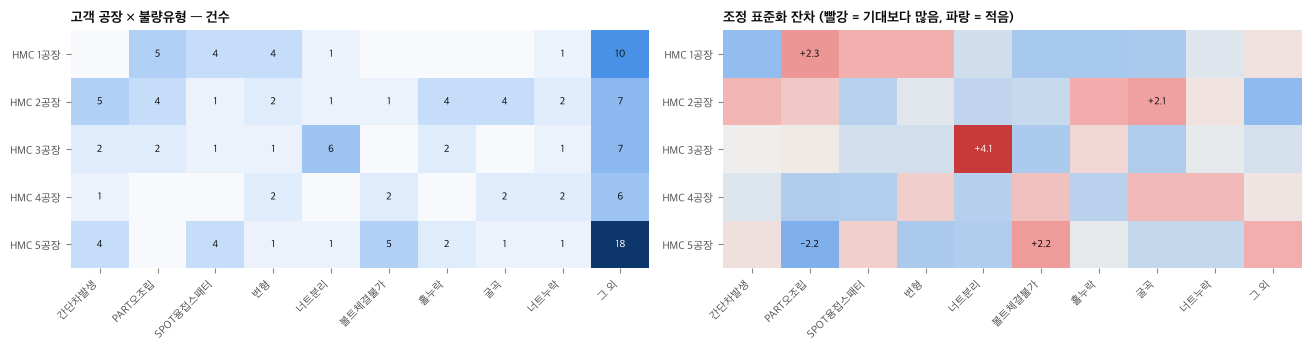

n=130 · 카이제곱 65.4 (자유도 36) · p(근사)=0.0020 · p(순열)=0.0020 · Cramér's V=0.24 (약함)
유난히 많은 조합:
  · HMC 3공장 × 너트분리 (관측 6건, 기대 1.5건, 잔차 +4.1)
  · HMC 1공장 × PART오조립 (관측 5건, 기대 2.1건, 잔차 +2.3)
  · HMC 5공장 × 볼트체결불가 (관측 5건, 기대 2.3건, 잔차 +2.2)
  · HMC 2공장 × 굴곡 (관측 4건, 기대 1.7건, 잔차 +2.1)


In [26]:
cust = area_df('고객실질')
plants = ['HMC 1공장', 'HMC 2공장', 'HMC 3공장', 'HMC 4공장', 'HMC 5공장']
display(cust.groupby('발생처').agg(건수=('수량', 'size'), 수량=('수량', 'sum'), 차종수=('차종', 'nunique'),
                                    주요차종=('차종', lambda s: ', '.join(s.value_counts().head(3).index)),
                                    주요유형=('불량유형', lambda s: ', '.join(s.value_counts().head(3).index))).reindex(plants))
ct_cp, res_cp, test_cp = analyze_pair(cust, '발생처', '불량유형', '고객 공장 × 불량유형', n_col=9, row_order=plants, key='고객_공장×유형')

#### (2) HMC 공장별 발생 시기

- 월별 히트맵: 공장마다 불량이 몰린 달이 있는지
- 발생일 타임라인: 점 하나가 한 건, 점 크기는 수량
- 상·중·하순, 요일별 분포: 월 중 특정 시기에 몰리는지 (카이제곱·순열 검정), 발생일(1~31일) 분포가 공장마다 다른지 (Kruskal-Wallis 검정)
- 공장끼리 월별 건수가 같이 움직이는지 (Spearman 상관)

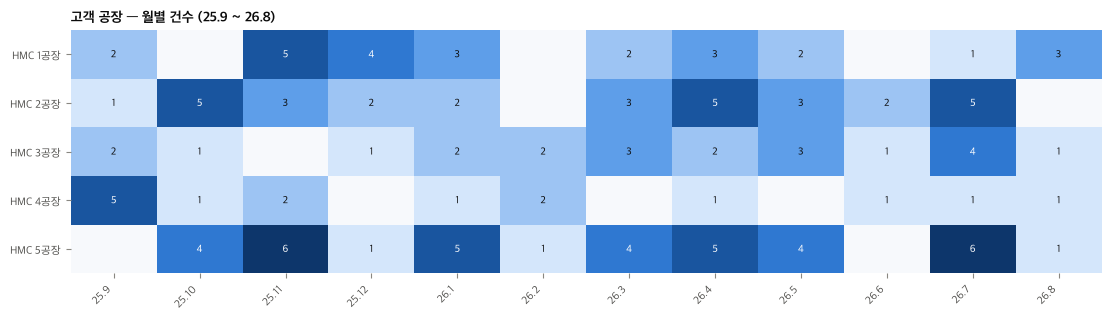

발생처 × 월 관계: p(순열)=0.0815, Cramér's V=0.16 (약함)


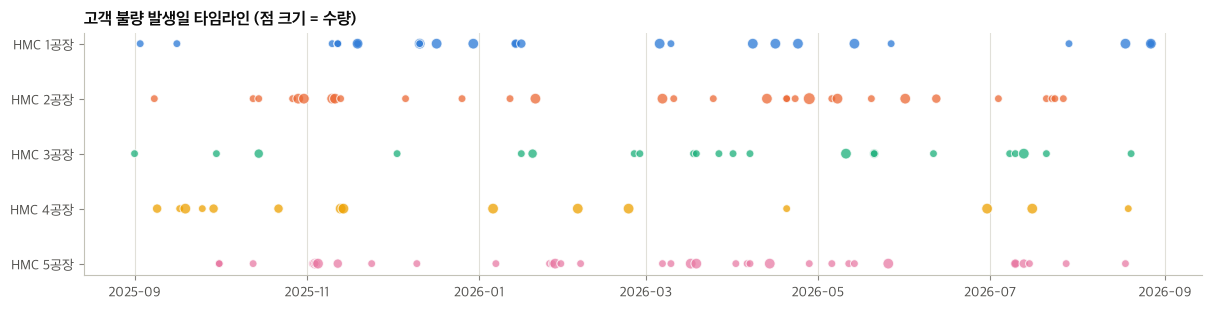

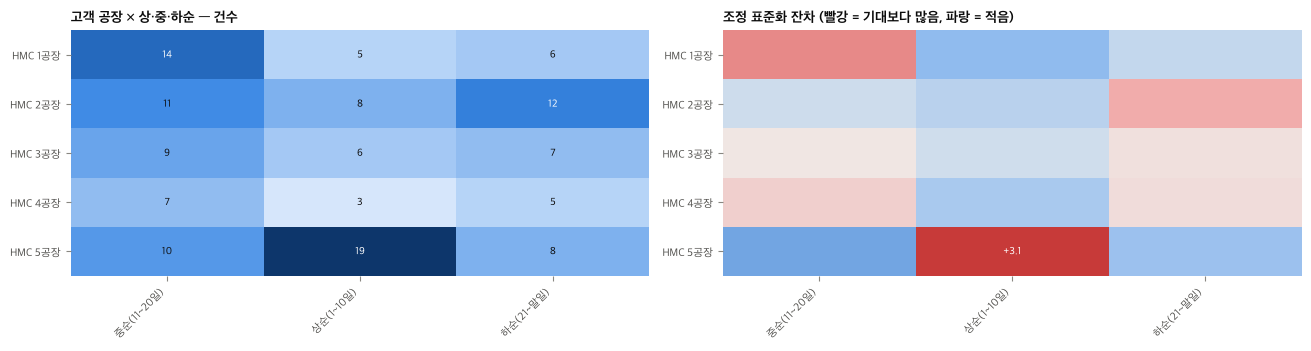

n=130 · 카이제곱 12.3 (자유도 8) · p(근사)=0.1369 · p(순열)=0.1394 · Cramér's V=0.13 (약함)
유난히 많은 조합:
  · HMC 5공장 × 상순(1~10일) (관측 19건, 기대 11.7건, 잔차 +3.1)


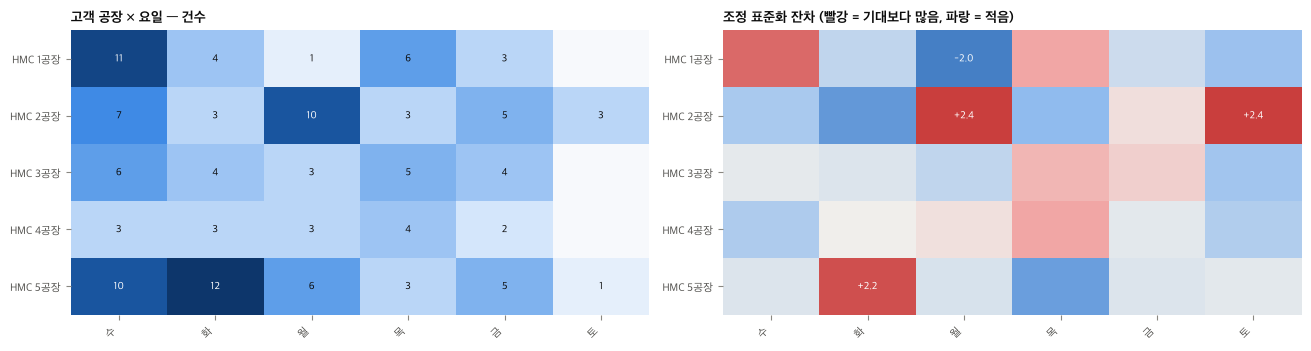

n=130 · 카이제곱 25.9 (자유도 20) · p(근사)=0.1693 · p(순열)=0.1729 · Cramér's V=0.11 (약함)
유난히 많은 조합:
  · HMC 2공장 × 토 (관측 3건, 기대 1.0건, 잔차 +2.4)
  · HMC 2공장 × 월 (관측 10건, 기대 5.5건, 잔차 +2.4)
  · HMC 5공장 × 화 (관측 12건, 기대 7.4건, 잔차 +2.2)
발생일(1~31일) 분포의 공장 간 차이 — Kruskal–Wallis H=6.38, p=0.173


,count,mean,25%,50%,75%
발생처,,,,,
HMC 1공장,25.0,16.4,11.0,16.0,19.0
HMC 2공장,31.0,16.6,10.5,15.0,23.5
HMC 3공장,22.0,15.7,10.2,17.0,21.0
HMC 4공장,15.0,17.8,13.5,19.0,22.5
HMC 5공장,37.0,12.8,6.0,10.0,18.0


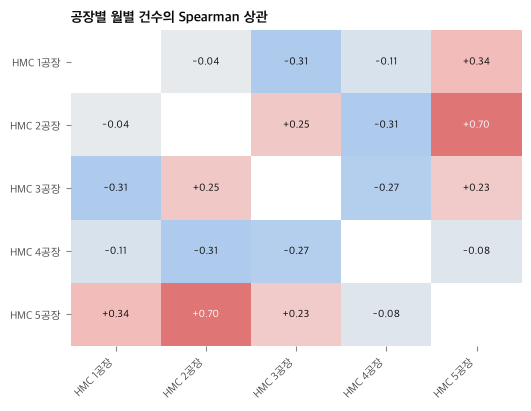

In [27]:
ct_cm = month_heatmap(cust, '발생처', '고객 공장', order=plants, key='고객_공장×월')

fig, ax = plt.subplots(figsize=(12, 3.0), layout='constrained')
for i, p in enumerate(plants):
    sub = cust[cust['발생처'] == p]
    ax.scatter(sub['일자'], np.full(len(sub), i), s=18 + 14 * sub['수량'], color=PALETTE[i], alpha=0.75, edgecolor='white', linewidth=0.8)
ax.set_yticks(range(len(plants)), plants)
ax.invert_yaxis()
ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.set_title('고객 불량 발생일 타임라인 (점 크기 = 수량)', loc='left')
save_fig(fig, '시기_고객_타임라인'); plt.show()

_ = analyze_pair(cust, '발생처', '순', '고객 공장 × 상·중·하순', row_order=plants, key='고객_공장×순')
_ = analyze_pair(cust, '발생처', '요일', '고객 공장 × 요일', row_order=plants, key='고객_공장×요일')
kw = stats.kruskal(*[cust.loc[cust['발생처'] == p, '일'] for p in plants])
print(f'발생일(1~31일) 분포의 공장 간 차이 — Kruskal–Wallis H={kw.statistic:.2f}, p={kw.pvalue:.3f}')
display(cust.groupby('발생처')['일'].describe()[['count', 'mean', '25%', '50%', '75%']].reindex(plants).round(1))

m_cust, rho_cust = monthly_corr(cust, '발생처', n=5)
fig, ax = plt.subplots(figsize=(5.2, 4), layout='constrained')
def blank_diagonal(df):
    arr = df.to_numpy(dtype=float, copy=True)
    np.fill_diagonal(arr, np.nan)
    return pd.DataFrame(arr, index=df.index, columns=df.columns)


rho_show = blank_diagonal(rho_cust.loc[plants, plants])
draw_heatmap(ax, rho_show, '공장별 월별 건수의 Spearman 상관', cmap=DIV_CMAP, center=0, fmt='{:+.2f}', lim=1)
save_fig(fig, '시기_고객_공장간상관'); plt.show()

#### (3) 차종별로 많이 나는 불량 유형

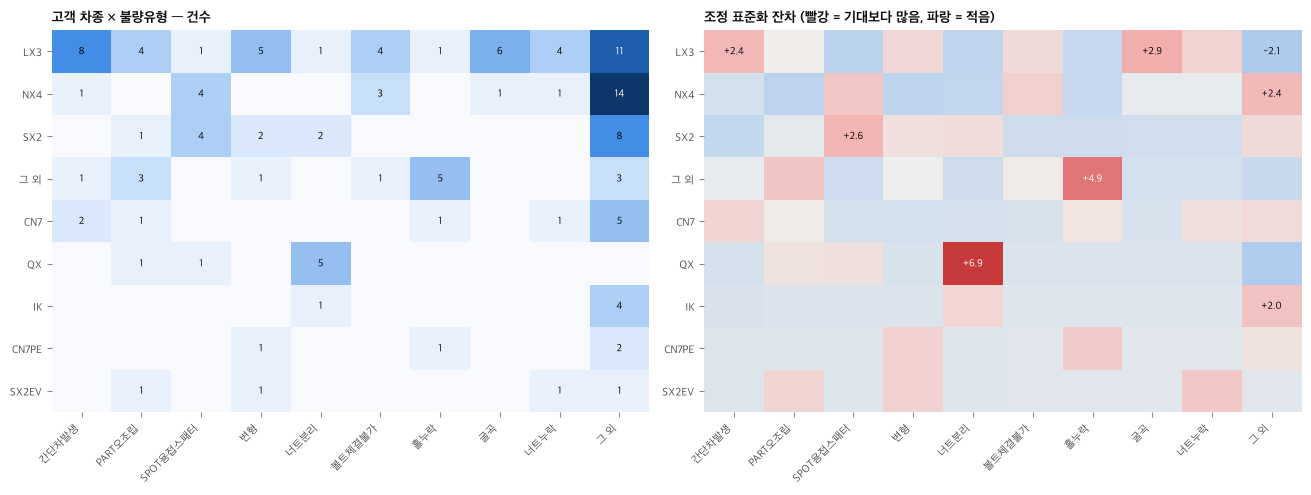

n=130 · 카이제곱 146.0 (자유도 72) · p(근사)=0.0000 · p(순열)=0.0005 · Cramér's V=0.27 (약함)
유난히 많은 조합:
  · QX × 너트분리 (관측 5건, 기대 0.5건, 잔차 +6.9)
  · LX3 × 굴곡 (관측 6건, 기대 2.4건, 잔차 +2.9)
  · SX2 × SPOT용접스패터 (관측 4건, 기대 1.3건, 잔차 +2.6)
  · LX3 × 간단차발생 (관측 8건, 기대 4.2건, 잔차 +2.4)


발생처,HMC 1공장,HMC 2공장,HMC 3공장,HMC 4공장,HMC 5공장,합계
차종,,,,,,
LX3,0,26,0,15,4,45
NX4,0,0,0,0,24,24
SX2,16,0,1,0,0,17
그 외,5,5,0,0,4,14
CN7,0,0,10,0,0,10
QX,0,0,7,0,0,7
IK,0,0,0,0,5,5
CN7PE,0,0,4,0,0,4
SX2EV,4,0,0,0,0,4


In [28]:
ct_cv, res_cv, test_cv = analyze_pair(cust, '차종', '불량유형', '고객 차종 × 불량유형', n_row=8, n_col=9, key='고객_차종×유형')
display(pd.crosstab(top_categories(cust['차종'], 8), cust['발생처']).reindex(columns=plants, fill_value=0)
        .assign(합계=lambda t: t.sum(1)).sort_values('합계', ascending=False))

### 4-3. 프레스·조립 공정 불량 (본사)

첨부4에 공정불량(프레스/조립)은 본사와 경주를 따로 관리한다고 되어 있습니다. 받은 데이터는 본사분이고, 경주 데이터가 오면 같은 코드에 넣어 돌리면 됩니다.

#### (1) 프레스 라인별 불량 유형

,건수,수량,금액_만원,품번수,원자재귀책_비율,주요유형
라인,,,,,,
P-1,137,789.0,269.40,26,0.73,"T/O, 형상불량, 크랙"
P-2,25,89.0,30.45,13,0.16,"형상불량, 크랙, 샘플"
P-3,64,300.0,191.48,20,0.72,"크랙, 형상불량, T/O"
P-4,172,557.0,482.46,23,0.57,"형상불량, 크랙, 박리"
P-5,199,678.0,784.92,25,0.74,"크랙, 형상불량, 박리"
P-6,3,12.0,2.73,3,0.00,형상불량


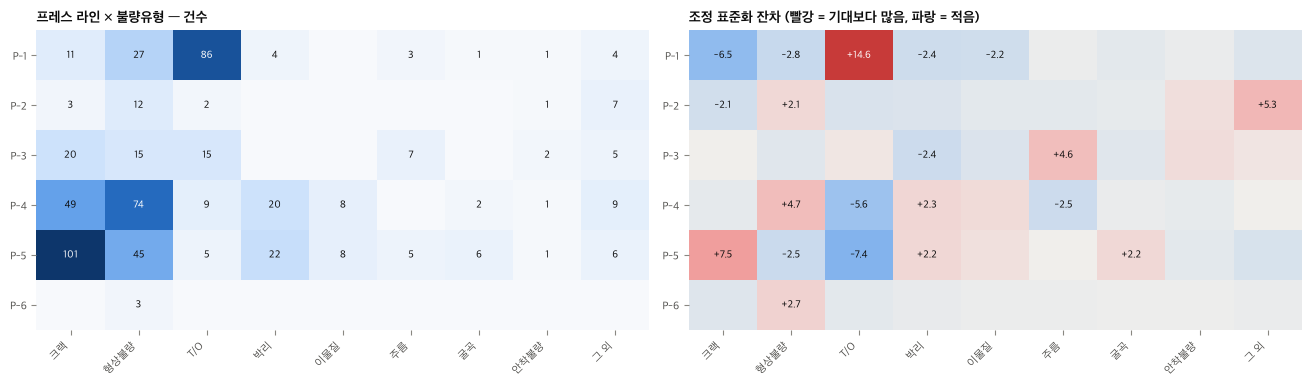

n=600 · 카이제곱 353.5 (자유도 40) · p(근사)=0.0000 · p(순열)=0.0005 · Cramér's V=0.32 (보통)
유난히 많은 조합:
  · P-1 × T/O (관측 86건, 기대 26.7건, 잔차 +14.6)
  · P-5 × 크랙 (관측 101건, 기대 61.0건, 잔차 +7.5)
  · P-4 × 형상불량 (관측 74건, 기대 50.5건, 잔차 +4.7)
  · P-3 × 주름 (관측 7건, 기대 1.6건, 잔차 +4.6)


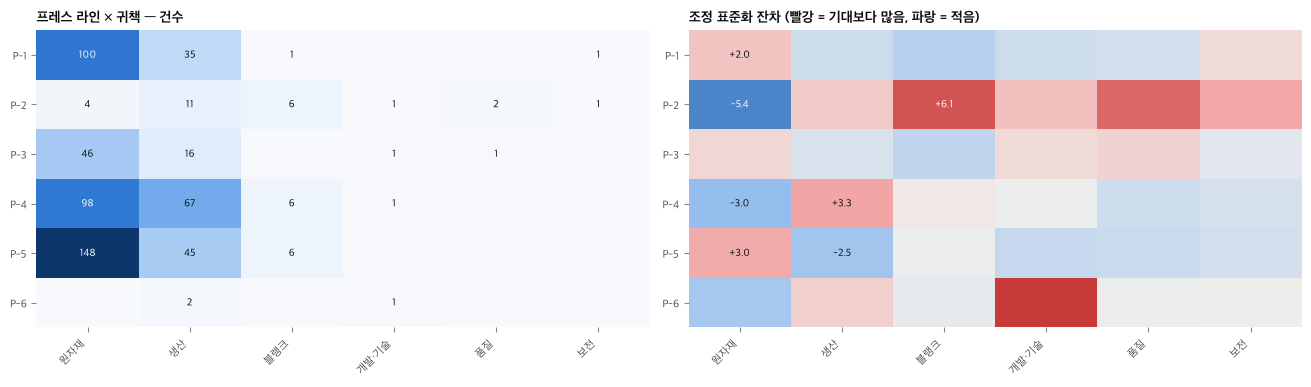

n=600 · 카이제곱 168.4 (자유도 25) · p(근사)=0.0000 · p(순열)=0.0010 · Cramér's V=0.22 (약함)
유난히 많은 조합:
  · P-2 × 블랭크 (관측 6건, 기대 0.8건, 잔차 +6.1)
  · P-4 × 생산 (관측 67건, 기대 50.5건, 잔차 +3.3)
  · P-5 × 원자재 (관측 148건, 기대 131.3건, 잔차 +3.0)
  · P-1 × 원자재 (관측 100건, 기대 90.4건, 잔차 +2.0)


In [29]:
press = area_df('프레스')
lines = sorted(press['라인'].dropna().unique())
display(press.groupby('라인').agg(건수=('수량', 'size'), 수량=('수량', 'sum'), 금액_만원=('금액', lambda s: s.sum() / 1e4),
                                 품번수=('품번', 'nunique'), 원자재귀책_비율=('귀책그룹', lambda s: (s == '원자재').mean()),
                                 주요유형=('불량유형', lambda s: ', '.join(s.value_counts().head(3).index))).round(2))
ct_pl, res_pl, test_pl = analyze_pair(press, '라인', '불량유형', '프레스 라인 × 불량유형', n_col=8, row_order=lines, key='프레스_라인×유형')
_ = analyze_pair(press, '라인', '귀책그룹', '프레스 라인 × 귀책', row_order=lines, key='프레스_라인×귀책')

#### (2) 프레스 라인별 발생 시기

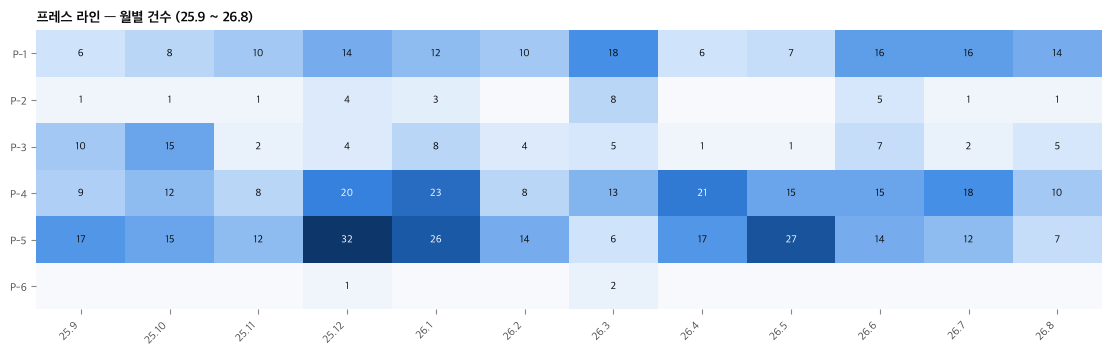

라인 × 월 관계: p(순열)=0.0005, Cramér's V=0.15 (약함)


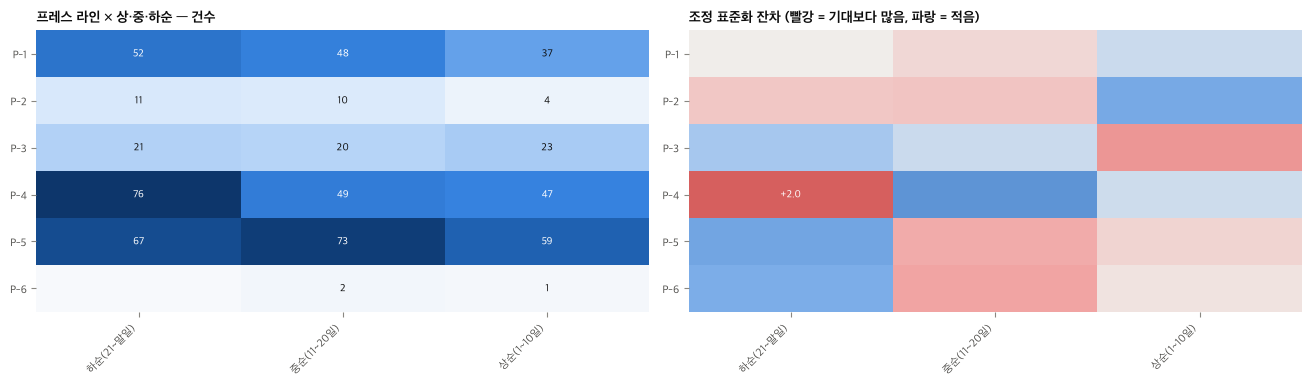

n=600 · 카이제곱 10.8 (자유도 10) · p(근사)=0.3698 · p(순열)=0.3563 · Cramér's V=0.03 (거의 없음)
유난히 많은 조합:
  · P-4 × 하순(21~말일) (관측 76건, 기대 65.1건, 잔차 +2.0)


,라인,월평균 건수,Spearman ρ (건수 vs 생산량),p
0,P-1,11.417,0.035,0.913
1,P-2,2.083,0.438,0.154
2,P-3,5.333,-0.067,0.836
3,P-4,14.333,0.389,0.211
4,P-5,16.583,0.348,0.268
5,P-6,0.250,0.360,0.250
6,프레스 전체,50.000,0.413,0.183


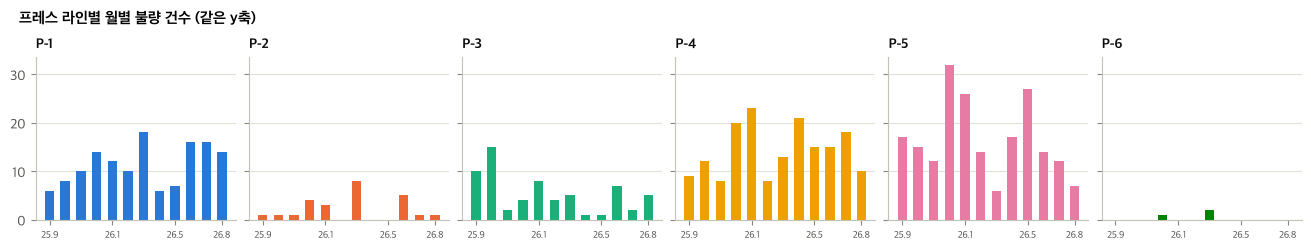

In [30]:
ct_plm = month_heatmap(press, '라인', '프레스 라인', order=lines, key='프레스_라인×월')
_ = analyze_pair(press, '라인', '순', '프레스 라인 × 상·중·하순', row_order=lines, key='프레스_라인×순')

line_month = pd.crosstab(press['년월'], press['라인']).reindex([str(m) for m in MONTHS], fill_value=0)
prod = ACT_RAW['프레스_생산수량'].values
rows = []
for ln in line_month.columns:
    r = stats.spearmanr(line_month[ln].values, prod)
    rows.append({'라인': ln, '월평균 건수': line_month[ln].mean(), 'Spearman ρ (건수 vs 생산량)': r.statistic, 'p': r.pvalue})
r = stats.spearmanr(line_month.sum(1).values, prod)
rows.append({'라인': '프레스 전체', '월평균 건수': line_month.sum(1).mean(), 'Spearman ρ (건수 vs 생산량)': r.statistic, 'p': r.pvalue})
display(pd.DataFrame(rows).round(3))

fig, axes = plt.subplots(1, len(lines), figsize=(13, 2.4), sharey=True, layout='constrained')
for i, (ax, ln) in enumerate(zip(axes, lines)):
    ax.bar(range(len(MONTHS)), line_month[ln].values, width=0.6, color=PALETTE[i % len(PALETTE)])
    ax.set_title(ln, loc='left', fontsize=10)
    ax.set_xticks([0, 4, 8, 11], ['25.9', '26.1', '26.5', '26.8'], fontsize=7)
fig.suptitle('프레스 라인별 월별 불량 건수 (같은 y축)', x=0.01, ha='left', fontsize=11, fontweight='bold')
save_fig(fig, '시기_프레스_라인별추이'); plt.show()

#### (3) 조립 차종별 불량 유형과 발생 시기

조립 불량 데이터에는 라인 정보가 없어서 차종그룹(예: CN7PE는 CN7)을 라인 대신 썼습니다.

,건수,수량,금액_만원,협력사귀책_비율,주요유형
차종그룹,,,,,
CN7,56,91.0,175.89,0.52,"형상불량, 크랙, 조립불량"
IK,14,92.0,48.33,0.21,"크랙, 형상불량, 분리시험"
JK1,11,24.0,52.89,0.64,"크랙, 형상불량, 분리시험"
JX1,9,20.0,24.44,0.22,"분리시험, 형상불량, 샘플용"
US4,7,21.0,32.13,0.43,"조립불량, 네크, 이물질"
NH2,5,12.0,24.10,0.60,"크랙, 용접누락, 패드융착"
RG3,5,5.0,3.46,0.40,"분리시험, 샘플용, 이물질"


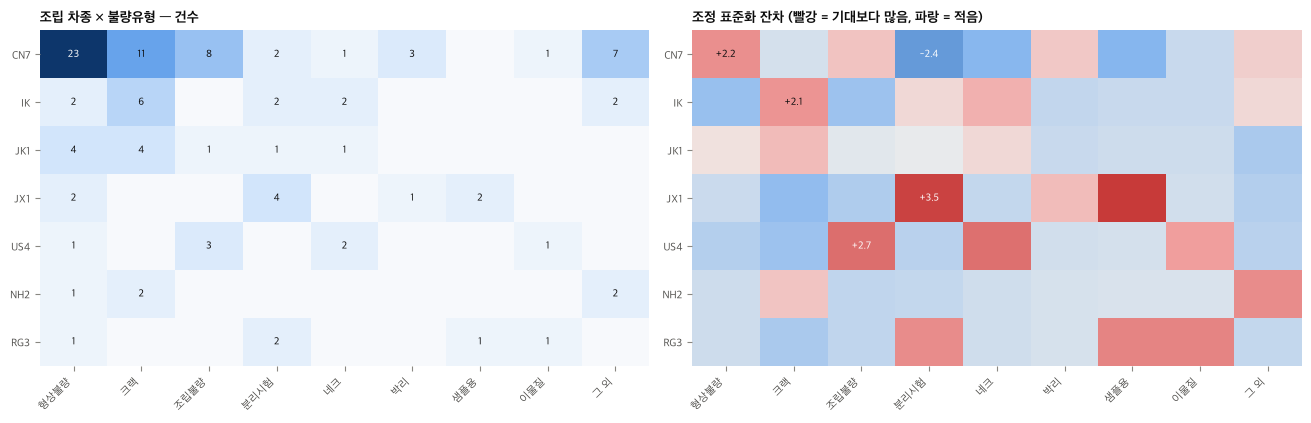

n=107 · 카이제곱 95.1 (자유도 48) · p(근사)=0.0001 · p(순열)=0.0005 · Cramér's V=0.28 (약함)
유난히 많은 조합:
  · JX1 × 분리시험 (관측 4건, 기대 0.9건, 잔차 +3.5)
  · US4 × 조립불량 (관측 3건, 기대 0.8건, 잔차 +2.7)
  · CN7 × 형상불량 (관측 23건, 기대 17.8건, 잔차 +2.2)
  · IK × 크랙 (관측 6건, 기대 3.0건, 잔차 +2.1)


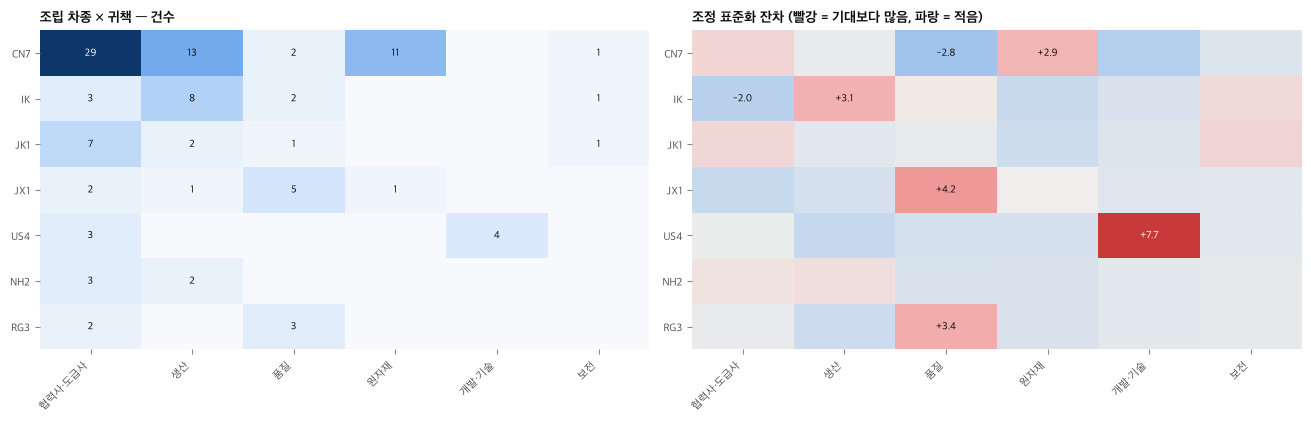

n=107 · 카이제곱 112.1 (자유도 30) · p(근사)=0.0000 · p(순열)=0.0005 · Cramér's V=0.40 (보통)
유난히 많은 조합:
  · US4 × 개발·기술 (관측 4건, 기대 0.3건, 잔차 +7.7)
  · JX1 × 품질 (관측 5건, 기대 1.1건, 잔차 +4.2)
  · RG3 × 품질 (관측 3건, 기대 0.6건, 잔차 +3.4)
  · IK × 생산 (관측 8건, 기대 3.4건, 잔차 +3.1)
조립 불량 107건 중 분리시험·샘플용 14건 (수량 14EA, 금액 47만원)


년월,2025-09,2025-10,2026-01,2026-03,2026-04,2026-06,2026-08
건수,3.0,1.0,1.0,1.0,1.0,1.0,6.0
수량,3.0,1.0,1.0,1.0,1.0,1.0,6.0


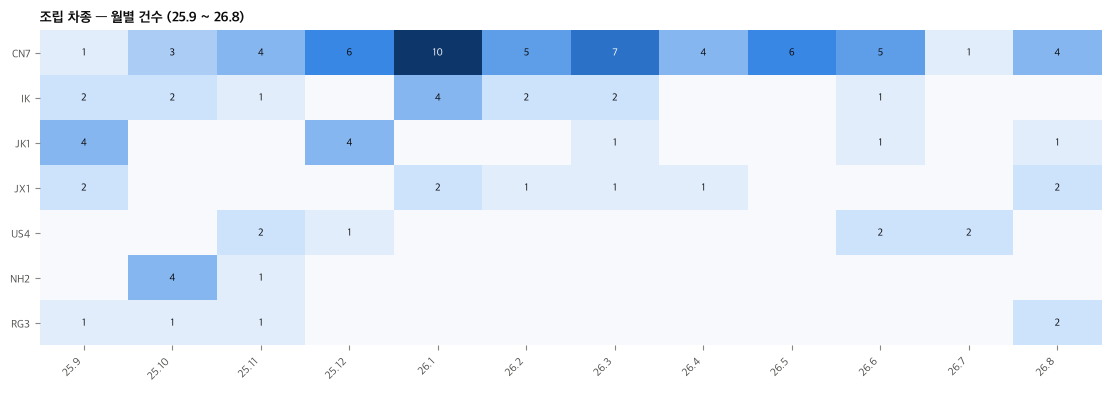

차종그룹 × 월 관계: p(순열)=0.0010, Cramér's V=0.29 (약함)


In [31]:
asm = area_df('조립')
display(asm.groupby('차종그룹').agg(건수=('수량', 'size'), 수량=('수량', 'sum'), 금액_만원=('금액', lambda s: s.sum() / 1e4),
                                  협력사귀책_비율=('귀책그룹', lambda s: (s == '협력사·도급사').mean()),
                                  주요유형=('불량유형', lambda s: ', '.join(s.value_counts().head(3).index)))
        .sort_values('건수', ascending=False).round(2))
ct_av, res_av, test_av = analyze_pair(asm, '차종그룹', '불량유형', '조립 차종 × 불량유형', n_row=7, n_col=8, key='조립_차종×유형')
_ = analyze_pair(asm, '차종그룹', '귀책그룹', '조립 차종 × 귀책', n_row=7, key='조립_차종×귀책')

test_scrap = asm[asm['불량유형'].isin(['분리시험', '샘플용'])]
print(f"조립 불량 {len(asm)}건 중 분리시험·샘플용 {len(test_scrap)}건 (수량 {test_scrap['수량'].sum():.0f}EA, 금액 {test_scrap['금액'].sum() / 1e4:.0f}만원)")
display(test_scrap.groupby('년월').agg(건수=('수량', 'size'), 수량=('수량', 'sum')).T)
ct_avm = month_heatmap(asm, '차종그룹', '조립 차종', n=7, key='조립_차종×월')

#### (4) 프레스 불량과 조립 불량의 시차 관계

프레스 불량이 많았던 달의 다음 달에 조립 불량(특히 프레스 귀책 유출)이 늘어나는지 봅니다.

In [32]:
monthly = pd.DataFrame({
    '프레스 건수': ACT_RAW['프레스_불량건수'], '조립 건수': ACT_RAW['조립_불량건수'],
    '조립 중 프레스 귀책 건수': ACT_RAW['프레스_유출건수'], '고객실질 본사 건수': ACT_RAW['조립_유출건수']})
rows = []
for a, b in [('프레스 건수', '조립 건수'), ('프레스 건수', '조립 중 프레스 귀책 건수'), ('조립 건수', '고객실질 본사 건수')]:
    for lag in [0, 1]:
        x, y = monthly[a].values[:len(monthly) - lag], monthly[b].values[lag:]
        r = stats.spearmanr(x, y)
        rows.append({'앞 공정(월 t)': a, '뒤 공정': f'{b} (월 t+{lag})', 'n(개월)': len(x), 'Spearman ρ': r.statistic, 'p': r.pvalue})
display(pd.DataFrame(rows).round(3))

,앞 공정(월 t),뒤 공정,n(개월),Spearman ρ,p
0,프레스 건수,조립 건수 (월 t+0),12,0.541,0.070
1,프레스 건수,조립 건수 (월 t+1),11,-0.345,0.299
2,프레스 건수,조립 중 프레스 귀책 건수 (월 t+0),12,0.427,0.166
3,프레스 건수,조립 중 프레스 귀책 건수 (월 t+1),11,0.227,0.501
4,조립 건수,고객실질 본사 건수 (월 t+0),12,0.037,0.909
5,조립 건수,고객실질 본사 건수 (월 t+1),11,0.231,0.495


### 4-4. 협력사 불량 (본사)

첨부4에 협력사 불량도 본사와 경주를 따로 관리한다고 되어 있습니다. 본사 협력사 불량은 227건입니다. 협력사 이름 앞뒤 공백은 정리했습니다(`' 정하이텍'` → `'정하이텍'`). `대린정공`은 QMS 원천에도 `주식회사 대린정공`으로 따로 있어 별도 업체로 두었는데, 같은 업체인지는 확인이 필요합니다.

#### (1) 협력사별 불량 유형

,건수,수량,품번수,발생월수,수입검사_발견비율,주요유형
협력사,,,,,,
대신정공,45,85.0,30,11,0.02,"홀누락, 변형, 주름"
성심정밀,36,70.0,21,11,0.03,"형상밀림, BURR, 크랙"
정하이텍,30,58.0,19,10,0.07,"형상밀림, 크랙, 홀누락"
영보산업,27,40.0,17,11,0.00,"형상밀림, 홀누락, 크랙"
길창,25,36.0,20,11,0.00,"홀누락, 형상밀림, 성형미흡"
성지산업,15,29.0,10,8,0.27,"네크, 찍힘, 주름"
우영산업,15,18.0,4,7,0.00,"PART오조립, SPOT용접스패터, 변형"
유성에프티,15,24.0,11,7,0.13,"홀누락, 형상밀림, 크랙"
영풍,6,15.0,1,5,0.67,"볼트분리, 찍힘, 백비드핀홀"


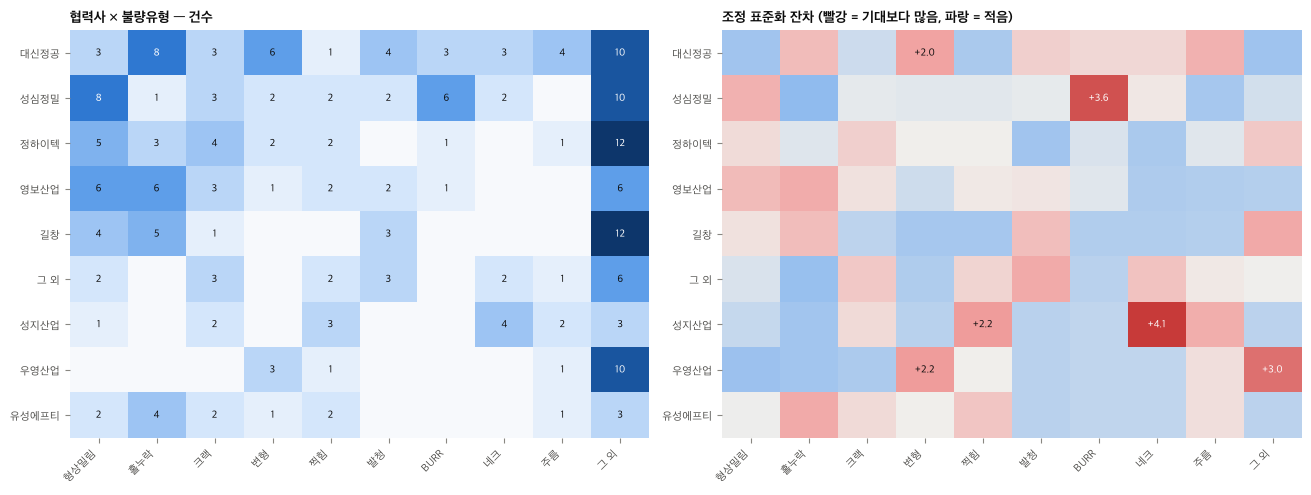

n=227 · 카이제곱 116.5 (자유도 72) · p(근사)=0.0007 · p(순열)=0.0005 · Cramér's V=0.16 (약함)
유난히 많은 조합:
  · 성지산업 × 네크 (관측 4건, 기대 0.7건, 잔차 +4.1)
  · 성심정밀 × BURR (관측 6건, 기대 1.7건, 잔차 +3.6)
  · 성지산업 × 찍힘 (관측 3건, 기대 1.0건, 잔차 +2.2)
  · 우영산업 × 변형 (관측 3건, 기대 1.0건, 잔차 +2.2)


In [33]:
sup = area_df('협력사')
display(sup.groupby('협력사').agg(건수=('수량', 'size'), 수량=('수량', 'sum'), 품번수=('품번', 'nunique'), 발생월수=('년월', 'nunique'),
                                수입검사_발견비율=('발생처', lambda s: (s == '수입검사').mean()),
                                주요유형=('불량유형', lambda s: ', '.join(s.value_counts().head(3).index)))
        .sort_values('건수', ascending=False).round(2))
ct_sv, res_sv, test_sv = analyze_pair(sup, '협력사', '불량유형', '협력사 × 불량유형', n_row=8, n_col=9, key='협력사_업체×유형')

#### (2) 협력사별 발생 시기, (3) 발생 시기별 불량 유형

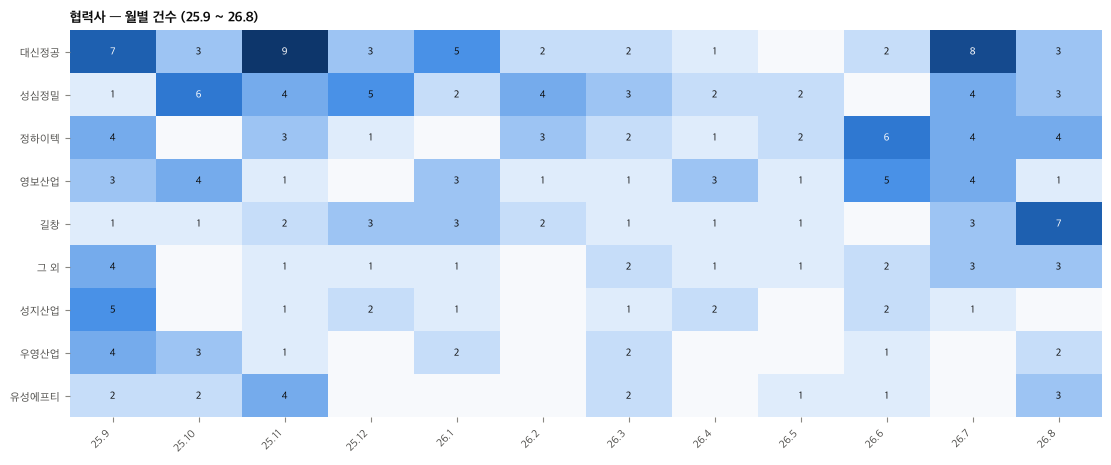

협력사 × 월 관계: p(순열)=0.1199, Cramér's V=0.09 (거의 없음)


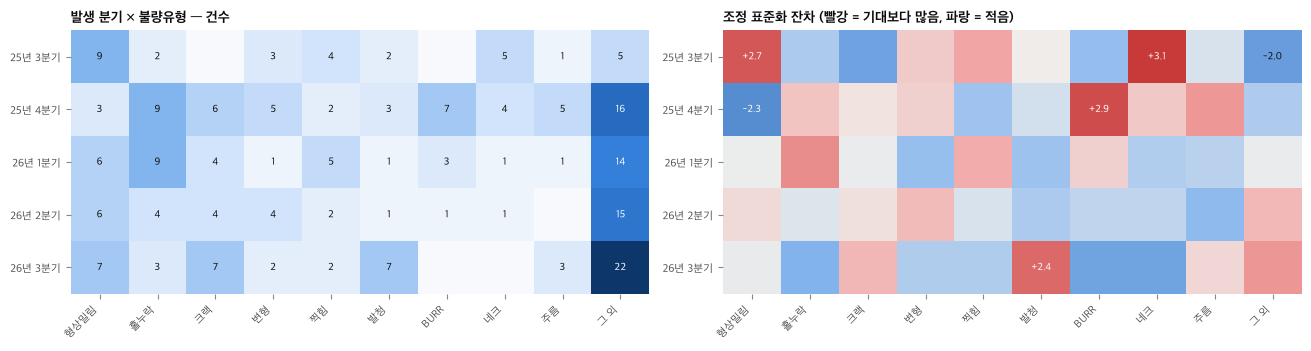

n=227 · 카이제곱 65.4 (자유도 36) · p(근사)=0.0019 · p(순열)=0.0020 · Cramér's V=0.18 (약함)
유난히 많은 조합:
  · 25년 3분기 × 네크 (관측 5건, 기대 1.5건, 잔차 +3.1)
  · 25년 4분기 × BURR (관측 7건, 기대 2.9건, 잔차 +2.9)
  · 25년 3분기 × 형상밀림 (관측 9건, 기대 4.2건, 잔차 +2.7)
  · 26년 3분기 × 발청 (관측 7건, 기대 3.3건, 잔차 +2.4)
분기별 기록 수: {'25년 3분기': 31, '25년 4분기': 60, '26년 1분기': 45, '26년 2분기': 38, '26년 3분기': 53} (25년 3분기는 9월, 26년 3분기는 7~8월만 포함)


In [34]:
ct_sm = month_heatmap(sup, '협력사', '협력사', n=8, key='협력사_업체×월')

quarter = sup['일자'].dt.to_period('Q').astype(str).str.replace(r'(\d{4})Q(\d)', lambda m: f"{m.group(1)[2:]}년 {m.group(2)}분기", regex=True)
sup['분기'] = quarter
q_order = sorted(sup['분기'].unique())
_ = analyze_pair(sup, '분기', '불량유형', '발생 분기 × 불량유형', n_col=9, row_order=q_order, key='협력사_분기×유형')
print('분기별 기록 수:', sup['분기'].value_counts().reindex(q_order).to_dict(), '(25년 3분기는 9월, 26년 3분기는 7~8월만 포함)')

#### (4) 상위 협력사의 발생 아이템

건수 상위 5개 협력사의 품번별 발생 현황입니다. 여러 달에 걸쳐 반복해서 나온 품번(재발 아이템)을 따로 표시했습니다.

,협력사,품번,품명,건수,수량,발생월수,최근발생,주요유형,발생처,재발
0,대신정공,71556-K2000,EXTN-SIDE OTR RR UPR LH,5,8.0,4,2026-07-03,"홀누락, 굴곡",QX 조립라인,재발
1,대신정공,64377-AR000,MBR ASSY-DASH UPR SIDE LH,3,8.0,1,2025-11-15,"형상밀림, 홀산포",JK1 조립라인,
2,대신정공,71788-G9000,PNL-PACKAGE TRAY SD FR LWR RH,3,5.0,3,2026-08-27,홀누락,IK 조립라인,재발
3,대신정공,71572-G9500,EXTN-SIDE OTR RR LH,2,6.0,2,2026-03-26,"형상밀림, BURR",IK 조립라인,재발
4,대신정공,71588-T6000,EXTN-RR COMB/LAMP HSG SD RH,2,5.0,2,2026-01-14,네크,JX1 조립라인,재발
5,성심정밀,71515-AR000,BRKT ASSY-GAS LIFTER MTG LH,5,12.0,4,2026-01-19,"BURR, 볼트체결불가",JK1 조립라인,재발
6,성심정밀,71574-K2000,EXTN-RR COMB/LAMP HSG LH,3,5.0,3,2026-05-08,"발청, 형상짤림",QX 조립라인,재발
7,성심정밀,64325-XH000,BRKT ASSY-HEATER LWR MTG,3,4.0,1,2025-10-15,"네크, 크랙",NH2 조립라인,
8,성심정밀,71524-T1000,BRKT-RR BUMPER SIDE MTG RH,3,4.0,3,2026-07-03,"형상밀림, 형상짤림",RG3 조립라인,재발
9,성심정밀,71554-T6700,EXTN-SIDE OTR RR LWR LH,2,6.0,2,2026-02-03,성형미흡,"JX1 조립라인, 수입검사",재발


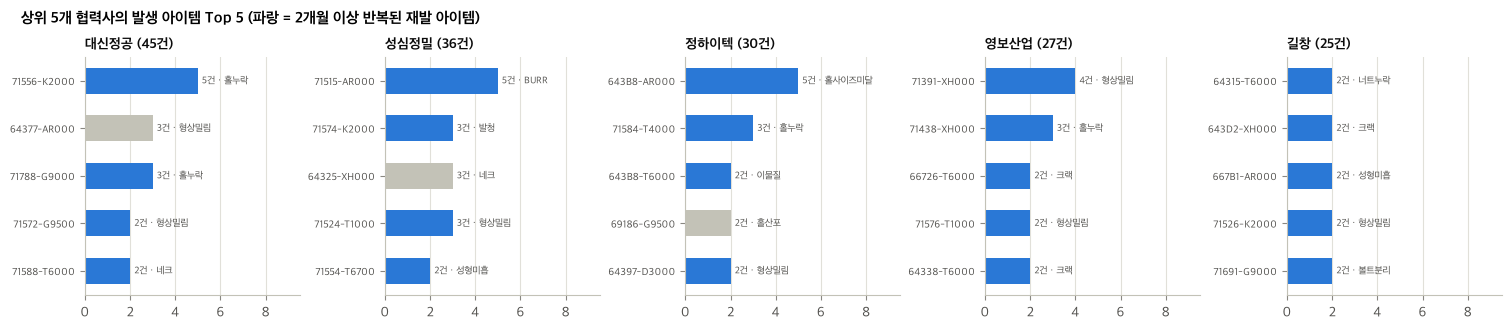

협력사 품번 145개 중 2개월 이상 반복: 40개 (28%), 이 품번들이 전체 건수의 50%를 차지


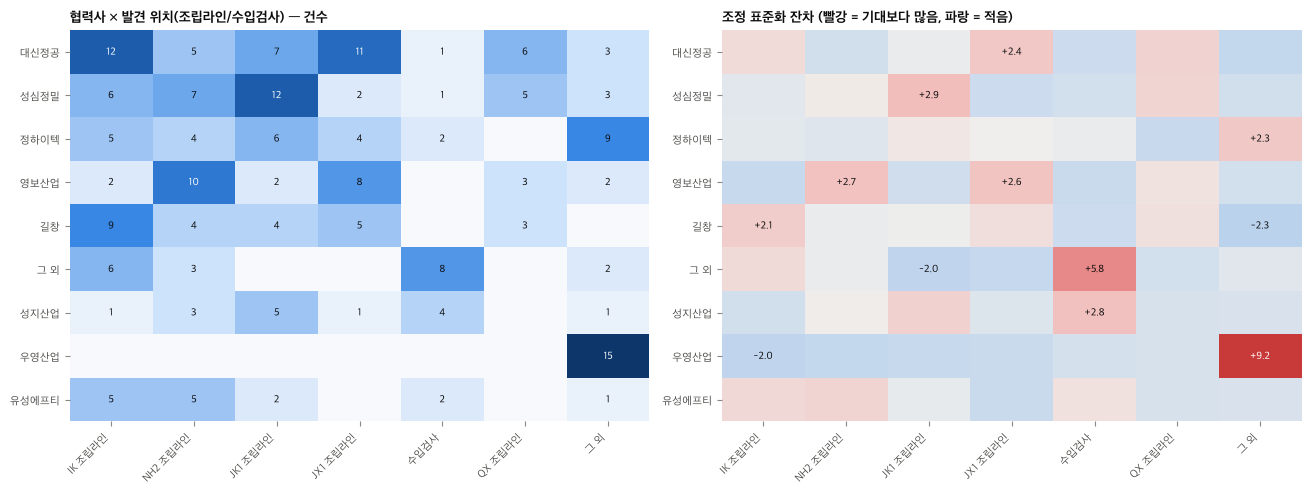

n=227 · 카이제곱 197.0 (자유도 48) · p(근사)=0.0000 · p(순열)=0.0005 · Cramér's V=0.34 (보통)
유난히 많은 조합:
  · 성심정밀 × JK1 조립라인 (관측 12건, 기대 6.0건, 잔차 +2.9)
  · 성지산업 × 수입검사 (관측 4건, 기대 1.2건, 잔차 +2.8)
  · 영보산업 × NH2 조립라인 (관측 10건, 기대 4.9건, 잔차 +2.7)
  · 영보산업 × JX1 조립라인 (관측 8건, 기대 3.7건, 잔차 +2.6)


In [35]:
top_sup = sup['협력사'].value_counts().head(5).index.tolist()
items = (sup[sup['협력사'].isin(top_sup)]
         .groupby(['협력사', '품번', '품명'])
         .agg(건수=('수량', 'size'), 수량=('수량', 'sum'), 발생월수=('년월', 'nunique'),
              최근발생=('일자', 'max'), 주요유형=('불량유형', lambda s: ', '.join(s.value_counts().head(2).index)),
              발생처=('발생처', lambda s: ', '.join(s.value_counts().head(2).index)))
         .reset_index())
items['재발'] = np.where(items['발생월수'] >= 2, '재발', '')
items['최근발생'] = items['최근발생'].dt.date
items = items.sort_values(['협력사', '건수', '수량'], ascending=[True, False, False])
top_items = items.groupby('협력사', sort=False).head(5)
top_items = top_items.set_index('협력사').loc[top_sup].reset_index()
display(top_items)

fig, axes = plt.subplots(1, len(top_sup), figsize=(15, 3.2), layout='constrained')
for ax, s_name in zip(axes, top_sup):
    t = items[items['협력사'] == s_name].head(5)[::-1]
    ax.barh(range(len(t)), t['건수'], height=0.55, color=[ACCENT if r == '재발' else GRAY for r in t['재발']])
    ax.set_yticks(range(len(t)), [f"{p}" for p in t['품번']], fontsize=7.5)
    for y, (v, ty) in enumerate(zip(t['건수'], t['주요유형'])):
        ax.annotate(f'{v}건 · {ty.split(",")[0]}', (v, y), xytext=(3, 0), textcoords='offset points', va='center', fontsize=7, color=INK2)
    ax.set_xlim(0, items['건수'].max() * 1.9)
    ax.set_title(f'{s_name} ({(sup["협력사"] == s_name).sum()}건)', loc='left', fontsize=10)
    ax.grid(axis='x'); ax.grid(axis='y', visible=False)
fig.suptitle('상위 5개 협력사의 발생 아이템 Top 5 (파랑 = 2개월 이상 반복된 재발 아이템)', x=0.01, ha='left', fontsize=11, fontweight='bold')
save_fig(fig, '협력사_상위업체_아이템'); plt.show()
items.to_csv(OUT['analysis'] / '협력사_상위업체_아이템.csv', index=False, encoding='utf-8-sig')

recur = sup.groupby(['협력사', '품번']).agg(발생월수=('년월', 'nunique'), 건수=('수량', 'size'))
print(f"협력사 품번 {len(recur)}개 중 2개월 이상 반복: {(recur['발생월수'] >= 2).sum()}개 "
      f"({(recur['발생월수'] >= 2).mean():.0%}), 이 품번들이 전체 건수의 {recur.loc[recur['발생월수'] >= 2, '건수'].sum() / len(sup):.0%}를 차지")

_ = analyze_pair(sup, '협력사', '발생처', '협력사 × 발견 위치(조립라인/수입검사)', n_row=8, n_col=6, key='협력사_업체×발견위치')

### 4-5. 영역 간 월별 상관 (추가 분석)

영역끼리 월별 건수가 같이 움직이는지, 생산량과 관계가 있는지 봅니다(12개월, Spearman). 상관이 높다고 해서 원인 관계라는 뜻은 아닙니다.

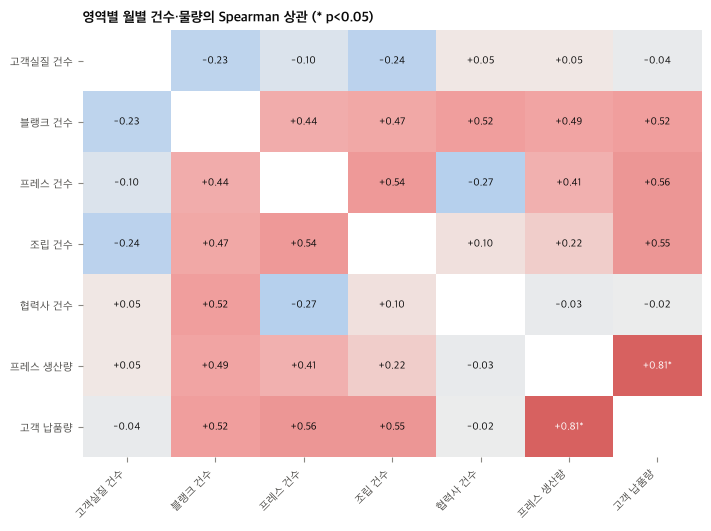

In [36]:
area_month = pd.DataFrame({
    '고객실질 건수': ACT_RAW['고객_실질건수'], '블랭크 건수': ACT_RAW['블랭크_불량건수'], '프레스 건수': ACT_RAW['프레스_불량건수'],
    '조립 건수': ACT_RAW['조립_불량건수'], '협력사 건수': ACT_RAW['협력사_불량건수'],
    '프레스 생산량': ACT_RAW['프레스_생산수량'], '고객 납품량': ACT_RAW['고객_납품수량']})
rho = area_month.corr(method='spearman')
pvals = pd.DataFrame([[stats.spearmanr(area_month[a], area_month[b]).pvalue for b in area_month] for a in area_month],
                     index=area_month.columns, columns=area_month.columns)
fig, ax = plt.subplots(figsize=(7, 5.2), layout='constrained')
ann = rho.copy().astype(object)
for a in rho.index:
    for b in rho.columns:
        ann.at[a, b] = '' if a == b else f'{rho.at[a, b]:+.2f}' + ('*' if pvals.at[a, b] < 0.05 else '')
rho_show = blank_diagonal(rho)
draw_heatmap(ax, rho_show, '영역별 월별 건수·물량의 Spearman 상관 (* p<0.05)', cmap=DIV_CMAP, center=0, annotate=ann, lim=1)
save_fig(fig, '상관_영역간_월별'); plt.show()

### 4-6. 상관분석 요약

위 분석의 검정 결과와 특히 많았던 조합을 한 표로 모았습니다(`output/analysis/상관분석_요약.csv`).

In [37]:
SUMMARY_R4 = pd.DataFrame(FINDINGS)
SUMMARY_R4.to_csv(OUT['analysis'] / '상관분석_요약.csv', index=False, encoding='utf-8-sig')
with pd.option_context('display.max_colwidth', 160):
    display(SUMMARY_R4.round(4))

,분석,행 기준,열 기준,n,p(순열),Cramér's V,관계,유난히 많은 조합
0,고객_공장×유형,발생처,불량유형,130,0.0020,0.2403,유의 (약함),"HMC 3공장 × 너트분리 (관측 6건, 기대 1.5건, 잔차 +4.1) / HMC 1공장 × PART오조립 (관측 5건, 기대 2.1건, 잔차 +2.3) / HMC 5공장 × 볼트체결불가 (관측 5건, 기대 2.3건, 잔차 +2.2) / HMC 2공장 × 굴곡 (관측 4건, 기..."
1,고객_공장×월,발생처,년월,130,0.0815,0.1575,유의하지 않음 (약함),HMC 5공장 25.11월 6건 / HMC 5공장 26.7월 6건 / HMC 2공장 25.10월 5건
2,고객_공장×순,발생처,순,130,0.1394,0.1292,유의하지 않음 (약함),"HMC 5공장 × 상순(1~10일) (관측 19건, 기대 11.7건, 잔차 +3.1)"
3,고객_공장×요일,발생처,요일,130,0.1729,0.1067,유의하지 않음 (약함),"HMC 2공장 × 토 (관측 3건, 기대 1.0건, 잔차 +2.4) / HMC 2공장 × 월 (관측 10건, 기대 5.5건, 잔차 +2.4) / HMC 5공장 × 화 (관측 12건, 기대 7.4건, 잔차 +2.2)"
4,고객_차종×유형,차종,불량유형,130,0.0005,0.2744,유의 (약함),"QX × 너트분리 (관측 5건, 기대 0.5건, 잔차 +6.9) / LX3 × 굴곡 (관측 6건, 기대 2.4건, 잔차 +2.9) / SX2 × SPOT용접스패터 (관측 4건, 기대 1.3건, 잔차 +2.6) / LX3 × 간단차발생 (관측 8건, 기대 4.2건, 잔차 +2.4)"
5,프레스_라인×유형,라인,불량유형,600,0.0005,0.3246,유의 (보통),"P-1 × T/O (관측 86건, 기대 26.7건, 잔차 +14.6) / P-5 × 크랙 (관측 101건, 기대 61.0건, 잔차 +7.5) / P-4 × 형상불량 (관측 74건, 기대 50.5건, 잔차 +4.7) / P-3 × 주름 (관측 7건, 기대 1.6건, 잔차 +4.6)"
6,프레스_라인×귀책,라인,귀책그룹,600,0.0010,0.2195,유의 (약함),"P-2 × 블랭크 (관측 6건, 기대 0.8건, 잔차 +6.1) / P-4 × 생산 (관측 67건, 기대 50.5건, 잔차 +3.3) / P-5 × 원자재 (관측 148건, 기대 131.3건, 잔차 +3.0) / P-1 × 원자재 (관측 100건, 기대 90.4건, 잔차 +2.0)"
7,프레스_라인×월,라인,년월,600,0.0005,0.1544,유의 (약함),P-5 25.12월 32건 / P-5 26.5월 27건 / P-5 26.1월 26건
8,프레스_라인×순,라인,순,600,0.3563,0.0263,유의하지 않음 (거의 없음),"P-4 × 하순(21~말일) (관측 76건, 기대 65.1건, 잔차 +2.0)"
9,조립_차종×유형,차종그룹,불량유형,107,0.0005,0.2776,유의 (약함),"JX1 × 분리시험 (관측 4건, 기대 0.9건, 잔차 +3.5) / US4 × 조립불량 (관측 3건, 기대 0.8건, 잔차 +2.7) / CN7 × 형상불량 (관측 23건, 기대 17.8건, 잔차 +2.2) / IK × 크랙 (관측 6건, 기대 3.0건, 잔차 +2.1)"


상관분석 결과 정리 (2026-10-24 실행 기준)

| 영역 | 확인한 관계 | 해석과 활용 |
|---|---|---|
| 고객 | 공장별로 불량 유형이 다름 (p≈0.002, V≈0.24). HMC 3공장 너트분리, 1공장 PART오조립, 5공장 볼트체결불가, 2공장 굴곡 | 공장마다 받는 차종이 거의 정해져 있어서(LX3는 2·4공장, NX4는 5공장, SX2는 1공장, CN7·QX는 3공장) 공장 차이는 대부분 차종 차이로 봐야 함. 차종 × 유형에서는 QX 너트분리(잔차 +6.9), LX3 굴곡, SX2 SPOT용접스패터가 두드러져 차종별 중점 관리 항목으로 쓸 수 있음 |
| 고객 (시기) | 공장 × 월, 순, 요일, 발생일 분포 모두 유의하지 않음 | 특정 시기에 몰린다고 보기는 어려움. 다만 HMC 5공장은 상순(1~10일) 발생이 많았음(19건, 기대 11.7건) |
| 프레스 | 라인별 유형 차이가 뚜렷함 (V≈0.32). P-1은 T/O(86건, 기대 27건), P-5는 크랙(101건, 기대 61건), P-4는 형상불량(74건, 기대 51건), P-3은 주름(7건, 기대 1.6건) | 라인별로 점검 항목을 달리 가져갈 근거가 됨. P-1, P-3, P-5는 원자재 귀책이 70% 이상이라 코일 LOT 변경 이력(4M)과 같이 보면 원인을 더 좁힐 수 있음(요구사항 R6) |
| 프레스 (시기) | 라인 × 월은 유의(P-5가 25.12, 26.1, 26.5월에 몰림). 상·중·하순과는 관계없고 생산량과의 상관도 유의하지 않음 | 월 단위로 라인 부하가 달라지므로 예측 ②(라인 순위)에 최근 추이를 특성으로 넣음 |
| 조립 | 차종 × 유형(V≈0.28): JX1 분리시험, US4 조립불량, CN7 형상불량, IK 크랙. 차종 × 귀책(V≈0.40): US4 개발·생산기술(26.6~7월 4건, 7/10 기록 비고에 "EV 적용 후 발생"), JX1·RG3 품질(분리시험·샘플), IK 생산 | 품질팀 분리시험·샘플 폐기도 조립 공정불량 PPM에 들어가 있음. 26년 8월 조립 불량 12EA 중 6EA가 분리시험이라 실제 공정 불량과 나눠 관리할지 회사 확인 필요 |
| 프레스와 조립 | 같은 달, 다음 달 모두 유의한 시차 상관 없음 | 12개월 데이터로는 공정 사이 전파를 확인하기 어려움 |
| 협력사 | 업체 × 유형 유의(V≈0.16). 성지산업 네크, 성심정밀 BURR, 우영산업 변형. 업체 × 월은 유의하지 않음 | 상위 업체(대신정공, 성심정밀, 영보산업, 길창)는 12개월 중 11개월 불량이 남. 시기보다는 업체와 품번 단위로 상시 관리가 필요 |
| 협력사 (시기) | 분기 × 유형 유의. 26년 3분기(7~8월) 발청(7건, 기대 3.3건), 25년 3분기 네크·형상밀림, 25년 4분기 BURR | 여름철 발청(녹)이 늘었을 가능성이 있음. 하절기 방청과 보관 조건 점검 항목으로 쓸 수 있음 |
| 협력사 (아이템) | 협력사 품번의 28%가 2개월 이상 재발했고, 재발 품번이 전체 건수의 50%를 차지 | 재발 품번(예: 대신정공 71556-K2000, 성심정밀 71515-AR000, 정하이텍 643B8-AR000)부터 점검. 상위 5개 업체는 수입검사에서 발견된 비율이 0~7%이고 대부분 조립라인에서 발견되어 수입검사 검출력을 보강할 여지가 있음 |
| 영역 간 | 월별 건수끼리는 대부분 유의하지 않음. 프레스 생산량과 고객 납품량만 강한 양의 상관(ρ≈0.81) | 영역별 불량이 서로 따로 움직이므로 영역별로 관리하고 예측하는 것이 맞음 |

---
## 5. 불량 예측

목적은 다음 달 사전 예방 점검 대상을 정하는 것입니다(첨부4 `※ 예측`).

| 예측 | 첨부4 원문 요지 | 결과 | 예측 단위 |
|---|---|---|---|
| ① 사내 공정 불량 아이템 | 불량 발생 시기 분석으로 다음 달 예측 | 다음 달 점검할 프레스·조립 품번 목록과 예상 불량유형 | 품번 (분류: 다음 달 발생 여부) |
| ② 사내 공정 주요 라인 | 프레스·조립 라인 불량 발생 시기로 다음 달 예측 | 다음 달 점검할 라인 순위 | 라인 (회귀: 다음 달 건수) |
| ③ 협력사 불량 아이템 | 협력사 불량 분석으로 다음 달 예측 | 다음 달 점검할 협력사·품번 목록과 예상 불량유형 | 협력사 순위, 협력사·품번 |

### 5-0. 예측 방법

학습표는 한 행이 (대상, 월 t)이고, 정답은 t월에 불량이 났는지(1/0) 또는 t월 불량 건수입니다. 특성은 모두 t−1월까지의 기록으로만 계산해서 미래 정보가 섞이지 않게 했습니다. 25.11~26.8월 각 달에 대해 이런 표를 만들어 이어 붙여 학습하고, 마지막으로 26.9월 행을 만들어 예측합니다.

특성은 모두 과거에 언제, 얼마나 자주 불량이 났는지(발생 시기)를 숫자로 바꾼 것입니다.

| feature | 뜻 |
|---|---|
| 전월건수, 2개월전건수, 3개월전건수 | 직전 1, 2, 3개월 각각의 불량 건수 |
| 최근3개월건수, 최근6개월건수, 누적건수 | 기간별 합계 |
| 가중건수 | 최근 달일수록 크게 반영한 건수 (반감기 2개월) |
| 최근3개월발생월수, 최근6개월발생월수, 발생월비율 | 불량이 난 달의 수, 처음 발생 이후 불량이 난 달의 비율 (상습 여부) |
| 마지막발생후개월, 첫발생후개월 | 마지막 불량 이후, 처음 불량 이후 지난 개월 수 |
| 전월하순건수 | 전월 21일 이후 건수. 월말에 몰렸으면 다음 달로 이어질 수 있음 |
| 최근3개월수량, 누적유형수 | 불량 수량, 지금까지 나온 불량유형 수 |
| 전월전체건수 | 같은 영역(공정 또는 협력사 전체)의 전월 건수 |
| 그룹전월건수, 그룹최근3개월건수, 그룹가중건수, 그룹최근3개월품번수 | 같은 라인(①)이나 협력사(③)의 최근 불량. 품번 이력이 적을 때 소속 라인이나 업체 상태로 보완 |

학습, 검증, 테스트 기간은 마지막 달을 기준으로 자동으로 나눕니다.

| 구분 | 정답 월 | 용도 |
|---|---|---|
| 검증 | 26.2 ~ 26.5 (4개월) | 시간 순서 교차검증. 한 달씩 그 달 이전 데이터만으로 학습해 그 달을 예측하고, 4개월 성적으로 모델, 앙상블, 특성 세트를 고름 |
| 테스트 | 26.6 ~ 26.8 (3개월) | 26.5까지의 데이터로 학습한 모델로 예측. 모델 선택에 쓰지 않은 3개월로 성능 평가 |
| 다음 달 예측 | 26.9 | 25.11 ~ 26.8 전체로 다시 학습해 예측 |

처음에는 검증을 2개월로 한 번만 했는데, 우연히 잘 맞은 방법이 뽑히는 문제가 있어서 4개월을 한 달씩 옮겨 가며 검증하도록 바꿨습니다.

모델은 데이터가 적어서 딥러닝 대신 머신러닝 모델 7개를 비교했습니다. 로지스틱 회귀, 결정트리, 랜덤포레스트, 엑스트라트리, 그래디언트부스팅, 히스토그램부스팅, 단조 제약 부스팅입니다. 단조 제약 부스팅은 최근 불량이 많을수록 위험이 커지고 마지막 불량 이후 오래될수록 위험이 작아지도록 제약을 건 모델로, 데이터가 적을 때 엉뚱한 패턴을 학습하는 것을 막아 줍니다. ②, ③의 건수 예측에는 Ridge, 포아송 회귀와 같은 트리 모델들을 썼습니다.
- 특성 세트: 데이터가 적을 때 특성이 많으면 과적합되기 쉬워서 전체 특성과 핵심 특성 9개를 둘 다 시험하고 검증 성능이 좋은 쪽을 씁니다.
- 기준선: 모델 없이 쓰는 단순 규칙("전월에 났으면 또 난다", "최근 3개월 많이 난 순", "최근 가중 빈도 순")과 항상 비교합니다.
- 앙상블: 검증 성능 상위 3개 모델의 (a) 확률 평균, (b) 순위 평균, (c) ML 3개 + 기준선(상위 3개 모델과 가장 좋은 기준선의 순위 평균). 모델마다 틀리는 부분이 달라 평균을 내면 데이터가 적을 때 더 안정적입니다.
- 최종 방법은 검증 기간 성능으로 고르고, 테스트 성능은 결과 보고에만 씁니다.

평가 지표
- 적중률@K (Precision@K): 점검 목록 상위 K개 중 실제로 불량이 난 비율. 현장에서 가장 알아보기 쉬운 지표
- 포착률@K (Recall@K): 실제로 불량이 난 품번(과거 이력이 있는 것) 중 목록에 들어 있던 비율
- AP(평균 정밀도), AUC: 순위 전체의 품질 (0.5면 무작위 수준)
- ②, ③-1의 건수 예측: 순위 상관(Spearman ρ), 상위 3개 적중, 평균절대오차(MAE)

한계: 데이터가 12개월뿐이고 생산량이 공정 합계로만 있어서 품번별 불량률이 아니라 건수로만 순위를 매깁니다. 과거에 불량이 한 번도 없던 신규 품번은 후보에 없어서 예측할 수 없습니다.

예측에서 뺀 기록: 조립의 `분리시험`, `샘플용`은 품질팀 파괴시험과 고객 요청 샘플 폐기라 사전 예방 점검 대상이 아니라고 보고 예측 학습에서만 뺐습니다(4-3). CQI 계산에는 그대로 들어갑니다.

In [38]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression, Ridge, PoissonRegressor
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (ExtraTreesClassifier, ExtraTreesRegressor, GradientBoostingClassifier, GradientBoostingRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor, RandomForestClassifier,
                              RandomForestRegressor)
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.inspection import permutation_importance

DEFECTS['년월P'] = pd.PeriodIndex(DEFECTS['년월'], freq='M')
TARGET_MONTHS = MONTHS[2:]
TEST_MONTHS = TARGET_MONTHS[-3:]
VALID_MONTHS = TARGET_MONTHS[-7:-3]
NEXT_MONTH = LAST_MONTH + 1
print('검증(시간 순서 교차검증):', ', '.join(map(str, VALID_MONTHS)), '| 테스트:', TEST_MONTHS[0], '~', TEST_MONTHS[-1],
      '| 예측할 달:', NEXT_MONTH)


def rolling_validation(hist, features, models, target, predict):
    parts = []
    for m in VALID_MONTHS:
        train, part = hist[hist['년월P'] < m], hist[hist['년월P'] == m].copy()
        for name, model in models.items():
            part[name] = predict(clone(model).fit(train[features], train[target]), part[features])
        parts.append(part)
    return pd.concat(parts)


def month_matrix(events, key, value=None, mask=None):
    d = events if mask is None else events[mask]
    g = d.groupby(key + ['년월P'])
    m = (g.size() if value is None else g[value].sum()).unstack('년월P', fill_value=0)
    return m.reindex(columns=MONTHS, fill_value=0)


def build_item_panel(events, key, group_col):
    cnt = month_matrix(events, key)
    qty = month_matrix(events, key, value='수량').reindex(cnt.index, fill_value=0)
    late = month_matrix(events, key, mask=events['일'] >= 21).reindex(cnt.index, fill_value=0)
    total = events.groupby('년월P').size().reindex(MONTHS, fill_value=0)
    gcnt = month_matrix(events, [group_col])
    gitems = events.groupby([group_col, '년월P'])[key[-1]].nunique().unstack('년월P', fill_value=0).reindex(columns=MONTHS, fill_value=0)
    rows = []
    for t in list(TARGET_MONTHS) + [NEXT_MONTH]:
        i = len(MONTHS) if t > LAST_MONTH else MONTHS.get_loc(t)
        past = events[events['년월P'] < t]
        H = cnt.iloc[:, :i]
        ents = H.index[H.sum(axis=1) > 0]
        Hv = H.loc[ents].values
        n = Hv.shape[1]
        w = 0.5 ** (np.arange(n)[::-1] / 2.0)
        group = past.groupby(key)[group_col].agg(lambda s: s.mode().iloc[0]).reindex(ents)
        G = gcnt.reindex(group.values).iloc[:, :i].fillna(0).values
        f = pd.DataFrame(index=ents)
        f['전월건수'], f['2개월전건수'] = Hv[:, -1], Hv[:, -2]
        f['3개월전건수'] = Hv[:, -3] if n >= 3 else 0
        f['최근3개월건수'], f['최근6개월건수'], f['누적건수'] = Hv[:, -3:].sum(1), Hv[:, -6:].sum(1), Hv.sum(1)
        f['가중건수'] = (Hv * w).sum(1)
        f['최근3개월발생월수'], f['최근6개월발생월수'] = (Hv[:, -3:] > 0).sum(1), (Hv[:, -6:] > 0).sum(1)
        f['마지막발생후개월'] = n - np.array([np.flatnonzero(r).max() for r in Hv])
        f['첫발생후개월'] = n - np.array([np.flatnonzero(r).min() for r in Hv])
        f['발생월비율'] = ((Hv > 0).sum(1) + 0.5) / (f['첫발생후개월'] + 1)
        f['최근3개월수량'] = qty.loc[ents].iloc[:, max(0, i - 3):i].sum(1).values
        f['전월하순건수'] = late.loc[ents].iloc[:, i - 1].values
        f['누적유형수'] = past.groupby(key)['불량유형'].nunique().reindex(ents).fillna(0).values
        f['전월전체건수'] = total.iloc[i - 1]
        f['그룹전월건수'], f['그룹최근3개월건수'], f['그룹가중건수'] = G[:, -1], G[:, -3:].sum(1), (G * w).sum(1)
        f['그룹최근3개월품번수'] = gitems.reindex(group.values).iloc[:, max(0, i - 3):i].fillna(0).sum(1).values
        if t <= LAST_MONTH:
            y_cnt = cnt.loc[ents].iloc[:, i].values
            f['y'], f['y_cnt'] = (y_cnt > 0).astype(int), y_cnt
        else:
            f['y'], f['y_cnt'] = np.nan, np.nan
        f['그룹'] = group.values
        f['년월P'] = t
        rows.append(f.reset_index())
    return pd.concat(rows, ignore_index=True)


ITEM_FEATURES = ['전월건수', '2개월전건수', '3개월전건수', '최근3개월건수', '최근6개월건수', '누적건수', '가중건수',
                 '최근3개월발생월수', '최근6개월발생월수', '마지막발생후개월', '첫발생후개월', '발생월비율', '최근3개월수량',
                 '전월하순건수', '누적유형수', '전월전체건수', '그룹전월건수', '그룹최근3개월건수', '그룹가중건수', '그룹최근3개월품번수']
CORE_FEATURES = ['가중건수', '최근3개월건수', '최근6개월발생월수', '마지막발생후개월', '누적건수', '발생월비율',
                 '그룹가중건수', '그룹최근3개월건수']
RISK_UP = {'전월건수', '2개월전건수', '3개월전건수', '최근3개월건수', '최근6개월건수', '누적건수', '가중건수', '최근3개월발생월수',
           '최근6개월발생월수', '발생월비율', '최근3개월수량', '전월하순건수', '그룹전월건수', '그룹최근3개월건수', '그룹가중건수',
           '그룹최근3개월품번수', '최근6개월LOT건수'}
RISK_DOWN = {'마지막발생후개월'}
EXCLUDE_TYPES_FOR_PREDICTION = ['분리시험', '샘플용']


def monotonic_map(features):
    return {f: (1 if f in RISK_UP else (-1 if f in RISK_DOWN else 0)) for f in features}


print('학습표 함수 준비 완료 — 전체 특성', len(ITEM_FEATURES), '개, 핵심 특성', len(CORE_FEATURES), '개')

검증(시간 순서 교차검증): 2026-02, 2026-03, 2026-04, 2026-05 | 테스트: 2026-06 ~ 2026-08 | 예측할 달: 2026-09
학습표 함수 준비 완료 — 전체 특성 20 개, 핵심 특성 8 개


#### 공통 함수: 모델, 기준선, 평가, 앙상블

In [39]:
def classifiers(features):
    return {
        '로지스틱 회귀':    make_pipeline(FunctionTransformer(np.log1p), StandardScaler(),
                                      LogisticRegression(C=0.3, class_weight='balanced', max_iter=5000)),
        '결정트리':         DecisionTreeClassifier(max_depth=3, min_samples_leaf=15, class_weight='balanced', random_state=RANDOM_STATE),
        '랜덤포레스트':     RandomForestClassifier(n_estimators=500, max_depth=5, min_samples_leaf=5, class_weight='balanced_subsample',
                                               random_state=RANDOM_STATE, n_jobs=-1),
        '엑스트라트리':     ExtraTreesClassifier(n_estimators=500, max_depth=5, min_samples_leaf=5, class_weight='balanced_subsample',
                                             random_state=RANDOM_STATE, n_jobs=-1),
        '그래디언트부스팅': GradientBoostingClassifier(n_estimators=150, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=RANDOM_STATE),
        '히스토그램부스팅': HistGradientBoostingClassifier(max_depth=2, learning_rate=0.05, max_iter=150, l2_regularization=1.0,
                                                       min_samples_leaf=15, random_state=RANDOM_STATE),
        '단조 제약 부스팅': HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=10,
                                                       monotonic_cst=monotonic_map(features), random_state=RANDOM_STATE),
    }


ITEM_BASELINES = {
    '기준선: 전월 발생':   lambda d: d['전월건수'] + 1e-3 * d['누적건수'],
    '기준선: 최근 3개월':  lambda d: d['최근3개월건수'] + 1e-3 * d['누적건수'],
    '기준선: 가중 빈도':   lambda d: d['가중건수'] + 1e-3 * d['누적건수'],
}


def at_k(df, score, k, by=None):
    keys = ['년월P'] + ([by] if by else [])
    precision, recall = [], []
    for grp, g in df.groupby(keys):
        kk = k[grp[1]] if isinstance(k, dict) else k
        top = g.nlargest(kk, score)
        precision.append(top['y'].mean())
        recall.append(top['y'].sum() / g['y'].sum() if g['y'].sum() else np.nan)
    return np.nanmean(precision), np.nanmean(recall)


def rank_average(df, cols):
    return df.groupby('년월P')[cols].rank(pct=True).mean(axis=1)


def evaluate_classification(df, cols, k, by=None):
    rows = []
    for c in cols:
        p, r = at_k(df, c, k, by)
        rows.append({'방법': c, '적중률@K': p, '포착률@K': r, 'AP': average_precision_score(df['y'], df[c]),
                     'AUC': roc_auc_score(df['y'], df[c])})
    return pd.DataFrame(rows).set_index('방법')


def add_ensembles(df, top3, best_base):
    df['앙상블: 확률 평균'] = df[top3].mean(axis=1)
    df['앙상블: 순위 평균'] = rank_average(df, top3)
    df['ML 3개 + 기준선'] = rank_average(df, top3 + [best_base])
    return ['앙상블: 확률 평균', '앙상블: 순위 평균', 'ML 3개 + 기준선']


def compare_classifiers(panel, features, k, by=None, title=''):
    hist = panel[panel['y'].notna()]
    trval, test = hist[hist['년월P'] < TEST_MONTHS[0]], hist[hist['년월P'].isin(TEST_MONTHS)].copy()
    models = classifiers(features)
    proba = lambda model, X: model.predict_proba(X)[:, 1]
    valid = rolling_validation(hist, features, models, 'y', proba)
    for name, model in models.items():
        test[name] = proba(clone(model).fit(trval[features], trval['y']), test[features])
    for name, rule in ITEM_BASELINES.items():
        valid[name], test[name] = rule(valid), rule(test)
    val_single = evaluate_classification(valid, list(models) + list(ITEM_BASELINES), k, by)
    top3 = val_single.loc[list(models)].sort_values(['AP', '적중률@K'], ascending=False).index[:3].tolist()
    best_base = val_single.loc[list(ITEM_BASELINES)].sort_values(['AP', '적중률@K'], ascending=False).index[0]
    ens = add_ensembles(valid, top3, best_base)
    add_ensembles(test, top3, best_base)
    methods = list(models) + list(ITEM_BASELINES) + ens
    val_all, test_all = evaluate_classification(valid, methods, k, by), evaluate_classification(test, methods, k, by)
    table = val_all.add_prefix('검증 ').join(test_all.add_prefix('테스트 '))
    order = ens + list(models) + list(ITEM_BASELINES)
    chosen = max(order, key=lambda m: (round(val_all.at[m, 'AP'], 3), round(val_all.at[m, '적중률@K'], 3)))
    print(f'[{title}] 검증 {len(VALID_MONTHS)}개월 {len(valid)}행 · 테스트 {len(test)}행(학습 {len(trval)}행) | '
          f"테스트 기간 실제 발생 비율(무작위로 고를 때의 적중률) {test['y'].mean():.1%}")
    print(f'검증 상위 3개 모델: {top3} / 가장 좋은 기준선: {best_base} → 최종 선택: {chosen}')
    return {'table': table, 'chosen': chosen, 'top3': top3, 'best_base': best_base, 'test': test, 'valid': valid,
            'features': features, 'val_ap': val_all.at[chosen, 'AP']}


def choose_feature_set(panel, sets, k, by=None, title=''):
    results = {name: compare_classifiers(panel, feats, k, by, f'{title} · {name}') for name, feats in sets.items()}
    summary = pd.DataFrame({name: {'특성 수': len(r['features']), '검증 최고 AP': r['val_ap'], '선택된 방법': r['chosen'],
                                   '테스트 적중률@K': r['table'].at[r['chosen'], '테스트 적중률@K'],
                                   '테스트 AUC': r['table'].at[r['chosen'], '테스트 AUC']} for name, r in results.items()}).T
    best = max(results, key=lambda n: results[n]['val_ap'])
    summary['선택'] = np.where(summary.index == best, '◀ 최종', '')
    display(summary)
    return results[best]


def show_comparison(res, sort_col='테스트 적중률@K'):
    t = res['table'].copy()
    t['구분'] = ['앙상블' if m.startswith(('앙상블', 'ML 3개')) else ('기준선' if m.startswith('기준선') else '단일 모델')
                for m in t.index]
    t['선택'] = np.where(t.index == res['chosen'], '◀ 최종', '')
    cols = ['구분', '검증 적중률@K', '검증 AP', '테스트 적중률@K', '테스트 포착률@K', '테스트 AP', '테스트 AUC', '선택']
    display(t[cols].round(3))


def fit_final_scores(panel, features, res):
    hist, nxt = panel[panel['y'].notna()], panel[panel['y'].isna()].copy()
    for name in res['top3']:
        nxt[name] = clone(classifiers(features)[name]).fit(hist[features], hist['y']).predict_proba(nxt[features])[:, 1]
    for name, rule in ITEM_BASELINES.items():
        nxt[name] = rule(nxt)
    add_ensembles(nxt, res['top3'], res['best_base'])
    nxt['위험점수'] = nxt[res['chosen']].rank(pct=True)
    return nxt


def importance_table(panel, features, res, top=8):
    hist = panel[panel['y'].notna()]
    trval, test = hist[hist['년월P'] < TEST_MONTHS[0]], hist[hist['년월P'].isin(TEST_MONTHS)]
    best = res['top3'][0]
    model = clone(classifiers(features)[best]).fit(trval[features], trval['y'])
    imp = permutation_importance(model, test[features], test['y'], scoring='average_precision', n_repeats=20, random_state=RANDOM_STATE)
    out = pd.DataFrame({'중요도(AP 감소)': imp.importances_mean, '표준편차': imp.importances_std}, index=features)
    return best, out.sort_values('중요도(AP 감소)', ascending=False).head(top)



#### 공통 함수: 예상 불량유형

품번마다 과거 불량유형 분포를 구하되 최근 기록에 가중치를 더 줍니다(반감기 3개월). 기록이 적은 품번은 소속 라인이나 협력사의 유형 분포로, 그것도 적으면 전체 분포로 보완합니다(베이즈 평활).

$$P(\text{유형}\mid\text{품번}) = \frac{\sum_{\text{품번 기록}} w \cdot \mathbb{1}[\text{유형}] + \alpha\, P(\text{유형}\mid\text{그룹})}{\sum w + \alpha},\qquad w = 0.5^{(\text{경과 개월}-1)/3},\ \alpha = 1$$

테스트 기간에 실제 불량이 난 품번을 대상으로 예상 1순위 유형이 맞은 비율(Top-1)과 1·2순위 안에 든 비율(Top-2)을 구해 기준선("직전 유형이 또 난다", "전체에서 가장 흔한 유형")과 비교합니다.

In [40]:
def type_distribution(events, key, group_col, t, half_life=3.0, alpha=1.0, beta=1.0):
    h = events[events['년월P'] < t].copy()
    age = (t.ordinal - h['년월P'].map(lambda p: p.ordinal)).astype(float)
    h['w'] = 0.5 ** ((age - 1) / half_life)
    overall = h.groupby('불량유형')['w'].sum()
    overall = overall / overall.sum()
    grp = h.groupby([group_col, '불량유형'])['w'].sum().unstack(fill_value=0)
    grp = grp.add(beta * overall, axis=1).div(grp.sum(axis=1) + beta, axis=0)
    ent = h.groupby(key + ['불량유형'])['w'].sum().unstack(fill_value=0)
    group_of = h.groupby(key)[group_col].agg(lambda s: s.mode().iloc[0])
    G = grp.reindex(group_of.reindex(ent.index).values).fillna(0)
    G.index = ent.index
    G = G.reindex(columns=ent.columns, fill_value=0)
    return ent.add(alpha * G).div(ent.sum(axis=1) + alpha, axis=0), overall


def evaluate_types(events, key, group_col, months):
    hit1, hit2, last_hit, common_hit = [], [], [], []
    for t in months:
        P, overall = type_distribution(events, key, group_col, t)
        actual = events[events['년월P'] == t].groupby(key)['불량유형'].apply(set)
        last_type = events[events['년월P'] < t].sort_values('일자').groupby(key)['불량유형'].last()
        for ent, types in actual.items():
            if ent not in P.index:
                continue
            ranked = P.loc[ent].sort_values(ascending=False).index.tolist()
            hit1.append(ranked[0] in types)
            hit2.append(bool(set(ranked[:2]) & types))
            last_hit.append(last_type.get(ent) in types)
            common_hit.append(overall.idxmax() in types)
    return pd.Series({'평가 건수': len(hit1), '예상 Top-1 적중': np.mean(hit1), '예상 Top-2 적중': np.mean(hit2),
                      '기준선: 직전 유형': np.mean(last_hit), '기준선: 전체 최빈 유형': np.mean(common_hit)})


def expected_types(events, key, group_col, t, entities, n=2):
    P, _ = type_distribution(events, key, group_col, t)
    out = []
    for ent in entities:
        if ent in P.index:
            top = P.loc[ent].sort_values(ascending=False).head(n)
            out.append(', '.join(f'{k}({v:.0%})' for k, v in top.items()))
        else:
            out.append('-')
    return out


### 5-1. 예측 ① 사내 공정 불량 아이템 (프레스·조립 품번)

- 대상: 과거에 불량 이력이 있는 프레스 품번과 조립 품번. 데이터가 적어서 두 공정을 한 모델로 학습하고 `프레스여부` 특성으로 구분합니다. 점검 목록은 공정별로 프레스 상위 10개, 조립 상위 5개를 뽑습니다.
- 그룹(라인): 프레스는 폐기처(P-1~P-6), 조립은 라인 정보가 없어 차종그룹을 씁니다.

In [41]:
proc_events = DEFECTS[DEFECTS['영역'].isin(['프레스', '조립']) & ~DEFECTS['불량유형'].isin(EXCLUDE_TYPES_FOR_PREDICTION)].copy()
proc_events['품번'] = proc_events['품번'].astype(str)
proc_events['공정'] = proc_events['영역']
print(f"예측에서 뺀 시험·샘플 폐기: {DEFECTS['불량유형'].isin(EXCLUDE_TYPES_FOR_PREDICTION).sum()}건")
P1 = build_item_panel(proc_events, ['공정', '품번'], '라인')
P1['프레스여부'] = (P1['공정'] == '프레스').astype(int)
K1 = {'프레스': 10, '조립': 5}

summary = P1[P1['y'].notna()].groupby(['년월P', '공정']).agg(후보수=('y', 'size'), 실제발생=('y', 'sum')).unstack('공정')
summary.index = summary.index.astype(str)
print('월별 후보(과거 이력 있는 품번) 수와 그중 실제로 불량이 난 품번 수:')
display(summary.T)

RES1 = choose_feature_set(P1, {'전체 특성': ITEM_FEATURES + ['프레스여부'], '핵심 특성': CORE_FEATURES + ['프레스여부']},
                          K1, by='공정', title='예측 ①')
F1 = RES1['features']
print(f'▶ 최종 특성 세트: {len(F1)}개 — 아래는 그 세트의 모델 비교표')
show_comparison(RES1)

예측에서 뺀 시험·샘플 폐기: 14건
월별 후보(과거 이력 있는 품번) 수와 그중 실제로 불량이 난 품번 수:


년월P       2025-11  2025-12  2026-01  2026-02  2026-03  2026-04  2026-05  2026-06  2026-07  2026-08
     공정                                                                                           
후보수  조립      12.0     15.0     21.0     25.0     26.0     27.0     27.0     27.0     28.0     29.0
     프레스     30.0     35.0     51.0     62.0     63.0     78.0     85.0     89.0     99.0    103.0
실제발생 조립       4.0      3.0      5.0      4.0      5.0      3.0      4.0      4.0      1.0      3.0
     프레스     10.0     13.0     17.0     14.0     17.0     11.0     12.0     21.0     18.0     14.0

[예측 ① · 전체 특성] 검증 4개월 393행 · 테스트 375행(학습 557행) | 테스트 기간 실제 발생 비율(무작위로 고를 때의 적중률) 16.3%
검증 상위 3개 모델: ['랜덤포레스트', '로지스틱 회귀', '엑스트라트리'] / 가장 좋은 기준선: 기준선: 가중 빈도 → 최종 선택: 기준선: 가중 빈도
[예측 ① · 핵심 특성] 검증 4개월 393행 · 테스트 375행(학습 557행) | 테스트 기간 실제 발생 비율(무작위로 고를 때의 적중률) 16.3%
검증 상위 3개 모델: ['로지스틱 회귀', '단조 제약 부스팅', '엑스트라트리'] / 가장 좋은 기준선: 기준선: 가중 빈도 → 최종 선택: 로지스틱 회귀


,특성 수,검증 최고 AP,선택된 방법,테스트 적중률@K,테스트 AUC,선택
전체 특성,21,0.702365,기준선: 가중 빈도,0.583333,0.824815,
핵심 특성,9,0.702431,로지스틱 회귀,0.6,0.82907,◀ 최종


▶ 최종 특성 세트: 9개 — 아래는 그 세트의 모델 비교표


,구분,검증 적중률@K,검증 AP,테스트 적중률@K,테스트 포착률@K,테스트 AP,테스트 AUC,선택
방법,,,,,,,,
로지스틱 회귀,단일 모델,0.638,0.702,0.600,0.636,0.638,0.829,◀ 최종
결정트리,단일 모델,0.588,0.628,0.567,0.612,0.523,0.701,
랜덤포레스트,단일 모델,0.638,0.671,0.600,0.636,0.619,0.791,
엑스트라트리,단일 모델,0.638,0.691,0.600,0.636,0.624,0.803,
그래디언트부스팅,단일 모델,0.625,0.666,0.617,0.645,0.616,0.803,
히스토그램부스팅,단일 모델,0.625,0.666,0.583,0.621,0.590,0.778,
단조 제약 부스팅,단일 모델,0.638,0.698,0.617,0.645,0.623,0.817,
기준선: 전월 발생,기준선,0.562,0.611,0.550,0.606,0.571,0.817,
기준선: 최근 3개월,기준선,0.625,0.686,0.583,0.626,0.629,0.832,


위 표에서 `검증 …` 열은 26.2~5월 시간 순서 교차검증 성적이고, 이 값으로 방법을 골랐습니다. `테스트 적중률@K`는 모델 선택에 쓰지 않은 26.6~8월에 매달 프레스 10개, 조립 5개를 점검 목록으로 뽑았을 때 실제 불량이 난 비율입니다. 무작위로 고르면 적중률은 위에 출력된 "실제 발생 비율" 정도가 됩니다.

In [42]:
by_proc = []
for proc, k in K1.items():
    sub = RES1['test'][RES1['test']['공정'] == proc]
    for m in [RES1['chosen'], RES1['best_base']]:
        p, r = at_k(sub, m, k)
        by_proc.append({'공정': proc, '목록 크기 K': k, '방법': m, '테스트 적중률@K': p, '테스트 포착률@K': r,
                        '무작위 적중률': sub['y'].mean()})
display(pd.DataFrame(by_proc).round(3))

best1, IMP1 = importance_table(P1, F1, RES1)
print(f'주요 위험변수 (검증 1위 단일 모델 = {best1}, 테스트 기간 순열 중요도):')
display(IMP1.round(4))

type_eval_1 = pd.DataFrame({proc: evaluate_types(proc_events[proc_events['공정'] == proc], ['품번'], '라인', TEST_MONTHS)
                            for proc in ['프레스', '조립']}).T
print('예상 불량유형 평가 (테스트 기간):')
display(type_eval_1.round(3))

,공정,목록 크기 K,방법,테스트 적중률@K,테스트 포착률@K,무작위 적중률
0,프레스,10,로지스틱 회귀,0.800,0.466,0.182
1,프레스,10,기준선: 가중 빈도,0.767,0.444,0.182
2,조립,5,로지스틱 회귀,0.400,0.806,0.095
3,조립,5,기준선: 가중 빈도,0.400,0.806,0.095


주요 위험변수 (검증 1위 단일 모델 = 로지스틱 회귀, 테스트 기간 순열 중요도):


,중요도(AP 감소),표준편차
가중건수,0.2341,0.0353
그룹최근3개월건수,0.0568,0.0176
최근3개월건수,0.0159,0.0165
누적건수,0.0093,0.0055
프레스여부,0.0032,0.0071
발생월비율,0.0025,0.0114
그룹가중건수,0.0007,0.0065
마지막발생후개월,-0.0023,0.0035


예상 불량유형 평가 (테스트 기간):


,평가 건수,예상 Top-1 적중,예상 Top-2 적중,기준선: 직전 유형,기준선: 전체 최빈 유형
프레스,53.0,0.755,0.868,0.679,0.358
조립,8.0,0.500,0.500,0.375,0.250


In [43]:
NEXT1 = fit_final_scores(P1, F1, RES1)
item_info = (proc_events.sort_values('일자').groupby(['공정', '품번'])
             .agg(품명=('품명', 'last'), 차종=('차종', 'last'), 라인=('라인', lambda s: s.mode().iloc[0]), 마지막발생=('일자', 'max')))
rows = []
for proc, k in K1.items():
    sub = NEXT1[NEXT1['공정'] == proc].sort_values('위험점수', ascending=False).head(k).copy()
    sub['순위'] = range(1, len(sub) + 1)
    sub['예상 불량유형'] = expected_types(proc_events[proc_events['공정'] == proc], ['품번'], '라인', NEXT_MONTH, sub['품번'])
    rows.append(sub)
FORECAST1 = pd.concat(rows).join(item_info, on=['공정', '품번'])
FORECAST1['근거'] = (FORECAST1.apply(lambda r: f"최근3개월 {r['최근3개월건수']:.0f}건 · 전월 {r['전월건수']:.0f}건 · "
                                               f"{r['최근6개월발생월수']:.0f}/6개월 발생 · 라인 최근3개월 {r['그룹최근3개월건수']:.0f}건", axis=1))
FORECAST1['마지막발생'] = FORECAST1['마지막발생'].dt.date
FORECAST1 = FORECAST1[['공정', '순위', '품번', '품명', '차종', '라인', '위험점수', '예상 불량유형', '근거', '마지막발생']]
print(f'{NEXT_MONTH} 점검 권장 품번 (방법: {RES1["chosen"]})')
display(FORECAST1.round(3))

2026-09 점검 권장 품번 (방법: 로지스틱 회귀)


,공정,순위,품번,품명,차종,라인,위험점수,예상 불량유형,근거,마지막발생
1059,프레스,1,76212-AA500,PNL FR DR INR LH,CN7PE,P-5,1.000,"크랙(51%), 형상불량(23%)",최근3개월 12건 · 전월 4건 · 6/6개월 발생 · 라인 최근3개월 33건,2026-08-25
1062,프레스,2,77212-AA000,PNL RR DR INR LH,CN7,P-4,0.993,"크랙(40%), 형상불량(21%)",최근3개월 14건 · 전월 2건 · 6/6개월 발생 · 라인 최근3개월 43건,2026-08-27
1061,프레스,3,76222-AA500,PNL FR DR INR RH,CN7PE,P-5,0.985,"크랙(65%), 형상불량(15%)",최근3개월 12건 · 전월 3건 · 6/6개월 발생 · 라인 최근3개월 33건,2026-08-31
1045,프레스,4,71566-T6000,EXTN-SIDE OTR RR UPR RH,JX1,P-1,0.978,"T/O(82%), 크랙(10%)",최근3개월 7건 · 전월 1건 · 6/6개월 발생 · 라인 최근3개월 46건,2026-08-27
1043,프레스,5,71556-T6000,EXTN-SIDE OTR RR UPR LH,JX1,P-1,0.971,"T/O(91%), 박리(4%)",최근3개월 7건 · 전월 1건 · 6/6개월 발생 · 라인 최근3개월 46건,2026-08-21
1023,프레스,6,71358-N9000,EXTN-SIDE SILL OTR FR LH,NX4,P-1,0.963,"T/O(81%), 크랙(11%)",최근3개월 16건 · 전월 5건 · 3/6개월 발생 · 라인 최근3개월 46건,2026-08-31
1064,프레스,7,77222-AA000,PNL RR DR INR RH,CN7,P-4,0.956,"크랙(36%), 형상불량(22%)",최근3개월 2건 · 전월 1건 · 5/6개월 발생 · 라인 최근3개월 43건,2026-08-24
1051,프레스,8,71622-G9000,PNL-QUARTER INR LWR RH,IK,P-4,0.949,"크랙(41%), 형상불량(26%)",최근3개월 7건 · 전월 4건 · 4/6개월 발생 · 라인 최근3개월 43건,2026-08-31
961,프레스,9,64312-AA000,PNL-DASH UPR,CN7,P-4,0.941,"형상불량(70%), END판(11%)",최근3개월 5건 · 전월 0건 · 4/6개월 발생 · 라인 최근3개월 43건,2026-07-22
1067,프레스,10,PT01043336,REIN-WHEEL HSG OTR RH,R2,P-1,0.926,"T/O(52%), 주름(21%)",최근3개월 4건 · 전월 4건 · 1/6개월 발생 · 라인 최근3개월 46건,2026-08-14


### 5-2. 예측 ② 사내 공정 주요 라인 순위

- 대상: 프레스 라인(P-1~P-6)과 조립 차종그룹(조립은 라인 정보가 없어 차종으로 대신). 과거 기록이 3건 이상인 라인만 넣습니다.
- 정답은 다음 달 불량 건수입니다. 회귀 모델로 건수를 예측하고 예측 건수 순으로 순위를 매깁니다. 순위는 프레스끼리, 조립끼리 공정별로 평가합니다.
- 특성: 전월, 2개월전, 3개월전 건수, 최근 3·6개월 평균, 전체 평균, 가중 평균, 최근 3개월 표준편차, 추세(최근 3개월에서 그 이전 3개월을 뺀 값), 전월 하순 건수, 최근 3개월 원자재 귀책 비율, 프레스 여부, 공정 전체의 전월 건수

In [44]:
def build_group_panel(events, key_col, extra=None, min_hist=3):
    cnt = month_matrix(events, [key_col])
    late = month_matrix(events, [key_col], mask=events['일'] >= 21).reindex(cnt.index, fill_value=0)
    mat = month_matrix(events, [key_col], mask=events['귀책그룹'] == '원자재').reindex(cnt.index, fill_value=0)
    proc_total = {p: events[events['공정'] == p].groupby('년월P').size().reindex(MONTHS, fill_value=0) for p in events['공정'].unique()}
    proc_of = events.groupby(key_col)['공정'].agg(lambda s: s.mode().iloc[0])
    rows = []
    for t in list(TARGET_MONTHS[1:]) + [NEXT_MONTH]:
        i = len(MONTHS) if t > LAST_MONTH else MONTHS.get_loc(t)
        H = cnt.iloc[:, :i]
        ents = H.index[H.sum(axis=1) >= min_hist]
        Hv = H.loc[ents].values.astype(float)
        w = 0.5 ** (np.arange(i)[::-1] / 2.0)
        f = pd.DataFrame(index=ents)
        f['전월건수'], f['2개월전건수'], f['3개월전건수'] = Hv[:, -1], Hv[:, -2], Hv[:, -3]
        f['최근3개월평균'], f['최근6개월평균'], f['전체평균'] = Hv[:, -3:].mean(1), Hv[:, -6:].mean(1), Hv.mean(1)
        f['가중평균'] = (Hv * w).sum(1) / w.sum()
        f['최근3개월표준편차'] = Hv[:, -3:].std(1)
        f['추세'] = Hv[:, -3:].mean(1) - (Hv[:, -6:-3].mean(1) if i >= 6 else Hv[:, :-3].mean(1) if i > 3 else 0)
        f['전월하순건수'] = late.loc[ents].iloc[:, i - 1].values
        f['최근3개월원자재비율'] = mat.loc[ents].iloc[:, max(0, i - 3):i].sum(1).values / np.maximum(1, Hv[:, -3:].sum(1))
        f['프레스여부'] = (proc_of.reindex(ents) == '프레스').astype(int).values
        f['공정전월건수'] = [proc_total[p].iloc[i - 1] for p in proc_of.reindex(ents)]
        if extra is not None:
            for name, func in extra.items():
                f[name] = func(ents, t)
        f['y_cnt'] = cnt.loc[ents].iloc[:, i].values if t <= LAST_MONTH else np.nan
        f['공정'] = proc_of.reindex(ents).values
        f['년월P'] = t
        rows.append(f.reset_index().rename(columns={key_col: '대상'}))
    return pd.concat(rows, ignore_index=True)


GROUP_FEATURES = ['전월건수', '2개월전건수', '3개월전건수', '최근3개월평균', '최근6개월평균', '전체평균', '가중평균',
                  '최근3개월표준편차', '추세', '전월하순건수', '최근3개월원자재비율', '프레스여부', '공정전월건수']


def regressors():
    return {
        'Ridge 회귀':          make_pipeline(StandardScaler(), Ridge(alpha=3.0)),
        '포아송 회귀':         make_pipeline(StandardScaler(), PoissonRegressor(alpha=0.5, max_iter=5000)),
        '랜덤포레스트':        RandomForestRegressor(n_estimators=500, max_depth=4, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1),
        '엑스트라트리':        ExtraTreesRegressor(n_estimators=500, max_depth=4, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1),
        '그래디언트부스팅':    GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=RANDOM_STATE),
        '히스토그램부스팅(포아송)': HistGradientBoostingRegressor(loss='poisson', max_depth=2, learning_rate=0.05, max_iter=150,
                                                            min_samples_leaf=5, random_state=RANDOM_STATE),
    }


GROUP_BASELINES = {
    '기준선: 전월 건수':   lambda d: d['전월건수'],
    '기준선: 3개월 평균':  lambda d: d['최근3개월평균'],
    '기준선: 가중 평균':   lambda d: d['가중평균'],
    '기준선: 전체 평균':   lambda d: d['전체평균'],
}


def evaluate_ranking(df, cols, by='공정', top=3):
    rows = []
    for c in cols:
        rho, hit, mae = [], [], []
        for _, g in df.groupby(['년월P', by]):
            if len(g) < 3:
                continue
            if g['y_cnt'].nunique() > 1:
                rho.append(stats.spearmanr(g[c], g['y_cnt']).statistic)
            k = min(top, len(g))
            hit.append(len(set(g.nlargest(k, c)['대상']) & set(g.nlargest(k, 'y_cnt')['대상'])) / k)
            mae.append(np.abs(g[c] - g['y_cnt']).mean())
        rows.append({'방법': c, '순위상관 ρ': np.nanmean(rho), f'상위{top} 적중': np.mean(hit), 'MAE(건)': np.mean(mae)})
    return pd.DataFrame(rows).set_index('방법')


def compare_regressors(panel, features, by='공정', title=''):
    hist = panel[panel['y_cnt'].notna()]
    trval, test = hist[hist['년월P'] < TEST_MONTHS[0]], hist[hist['년월P'].isin(TEST_MONTHS)].copy()
    models = regressors()
    valid = rolling_validation(hist, features, models, 'y_cnt', lambda model, X: model.predict(X))
    for name, model in models.items():
        test[name] = clone(model).fit(trval[features], trval['y_cnt']).predict(test[features])
    for name, rule in GROUP_BASELINES.items():
        valid[name], test[name] = rule(valid), rule(test)
    val_single = evaluate_ranking(valid, list(models) + list(GROUP_BASELINES), by)
    top3 = val_single.loc[list(models)].sort_values(['순위상관 ρ', 'MAE(건)'], ascending=[False, True]).index[:3].tolist()
    best_base = val_single.loc[list(GROUP_BASELINES)].sort_values(['순위상관 ρ', 'MAE(건)'], ascending=[False, True]).index[0]
    for df in (valid, test):
        df['앙상블: 평균'] = df[top3].mean(axis=1)
        df['ML 3개 + 기준선'] = df[top3 + [best_base]].mean(axis=1)
    ens = ['앙상블: 평균', 'ML 3개 + 기준선']
    methods = list(models) + list(GROUP_BASELINES) + ens
    val_all, test_all = evaluate_ranking(valid, methods, by), evaluate_ranking(test, methods, by)
    table = val_all.add_prefix('검증 ').join(test_all.add_prefix('테스트 '))
    order = ens + list(models) + list(GROUP_BASELINES)
    chosen = max(order, key=lambda m: (round(val_all.at[m, '순위상관 ρ'], 3), -round(val_all.at[m, 'MAE(건)'], 2)))
    print(f'[{title}] 검증 {len(VALID_MONTHS)}개월 {len(valid)}행 · 테스트 {len(test)}행(학습 {len(trval)}행)')
    print(f'검증 상위 3개 모델: {top3} / 가장 좋은 기준선: {best_base} → 최종 선택: {chosen}')
    t = table.copy()
    t['구분'] = ['앙상블' if m.startswith(('앙상블', 'ML 3개')) else ('기준선' if m.startswith('기준선') else '단일 모델')
                for m in t.index]
    t['선택'] = np.where(t.index == chosen, '◀ 최종', '')
    display(t[['구분'] + [c for c in t.columns if c.startswith('검증') or c.startswith('테스트')] + ['선택']].round(3))
    return {'table': table, 'chosen': chosen, 'top3': top3, 'best_base': best_base, 'test': test}


def forecast_groups(panel, features, res):
    hist, nxt = panel[panel['y_cnt'].notna()], panel[panel['y_cnt'].isna()].copy()
    for name in res['top3']:
        nxt[name] = clone(regressors()[name]).fit(hist[features], hist['y_cnt']).predict(nxt[features])
    for name, rule in GROUP_BASELINES.items():
        nxt[name] = rule(nxt)
    nxt['앙상블: 평균'] = nxt[res['top3']].mean(axis=1)
    nxt['ML 3개 + 기준선'] = nxt[res['top3'] + [res['best_base']]].mean(axis=1)
    nxt['예상건수'] = nxt[res['chosen']].clip(lower=0)
    return nxt


def top_by_method(nxt, res, top=3, by='공정'):
    methods = list(dict.fromkeys([res['chosen']] + res['top3'] + ['앙상블: 평균', 'ML 3개 + 기준선'] + list(GROUP_BASELINES)))
    rows = []
    for m in methods:
        row = {'방법': m + (' (최종)' if m == res['chosen'] else '')}
        for proc, g in nxt.groupby(by):
            row[f'{proc} 상위 {top}'] = ', '.join(str(v).replace(f'{proc} ', '') for v in g.nlargest(top, m)['대상'])
        rows.append(row)
    table = pd.DataFrame(rows).set_index('방법')
    for col in table.columns:
        sets = [set(x.split(', ')) for x in table[col]]
        common = set.intersection(*sets)
        overlap = np.mean([len(sets[0] & x) / len(sets[0]) for x in sets])
        print(f"{col}: 모든 방법에 공통 = {', '.join(sorted(common)) or '없음'} · 최종 방법 목록과 평균 {overlap:.0%} 겹침 (순서는 무시)")
    return table


line_events = proc_events.copy()
line_events['라인키'] = line_events['공정'] + ' ' + line_events['라인'].astype(str)
P2 = build_group_panel(line_events, '라인키')
print('라인 후보:', sorted(P2.loc[P2['년월P'] == NEXT_MONTH, '대상']))
RES2 = compare_regressors(P2, GROUP_FEATURES, title='예측 ② 사내 공정 라인')

라인 후보: ['조립 CN7', '조립 IK', '조립 JK1', '조립 JX1', '조립 NH2', '조립 US4', '프레스 P-1', '프레스 P-2', '프레스 P-3', '프레스 P-4', '프레스 P-5', '프레스 P-6']
[예측 ② 사내 공정 라인] 검증 4개월 45행 · 테스트 36행(학습 64행)
검증 상위 3개 모델: ['그래디언트부스팅', 'Ridge 회귀', '히스토그램부스팅(포아송)'] / 가장 좋은 기준선: 기준선: 전체 평균 → 최종 선택: 기준선: 전체 평균


,구분,검증 순위상관 ρ,검증 상위3 적중,검증 MAE(건),테스트 순위상관 ρ,테스트 상위3 적중,테스트 MAE(건),선택
방법,,,,,,,,
Ridge 회귀,단일 모델,0.625,0.667,3.782,0.615,0.889,1.979,
포아송 회귀,단일 모델,0.617,0.708,3.735,0.625,0.889,2.377,
랜덤포레스트,단일 모델,0.599,0.750,3.466,0.682,0.889,1.588,
엑스트라트리,단일 모델,0.620,0.708,3.782,0.689,0.889,1.721,
그래디언트부스팅,단일 모델,0.644,0.708,3.704,0.661,0.833,1.943,
히스토그램부스팅(포아송),단일 모델,0.622,0.708,3.683,0.717,0.889,1.982,
기준선: 전월 건수,기준선,0.750,0.875,3.367,0.730,0.833,2.167,
기준선: 3개월 평균,기준선,0.754,0.917,2.829,0.713,0.833,1.880,
기준선: 가중 평균,기준선,0.750,0.958,2.679,0.654,0.889,1.994,


2026-09 점검 권장 라인 순위 (방법: 기준선: 전체 평균, 예상건수 = 다음 달 불량 기록 건수 예측)


,공정,순위,라인,예상건수,예상 불량유형,근거
110,프레스,1,프레스 P-5,16.6,"크랙(49%), 형상불량(26%)",전월 7건 · 최근3개월 평균 11.0건 · 추세 -5.7 · 원자재 비율 73%
109,프레스,2,프레스 P-4,14.3,"형상불량(44%), 크랙(28%)",전월 10건 · 최근3개월 평균 14.3건 · 추세 -2.0 · 원자재 비율 49%
106,프레스,3,프레스 P-1,11.4,"T/O(62%), 형상불량(18%)",전월 14건 · 최근3개월 평균 15.3건 · 추세 +5.0 · 원자재 비율 72%
108,프레스,4,프레스 P-3,5.3,"크랙(27%), T/O(26%)",전월 5건 · 최근3개월 평균 4.7건 · 추세 +2.3 · 원자재 비율 50%
107,프레스,5,프레스 P-2,2.1,"형상불량(40%), 크랙(23%)",전월 1건 · 최근3개월 평균 2.3건 · 추세 -0.3 · 원자재 비율 14%
111,프레스,6,프레스 P-6,0.2,"형상불량(61%), 크랙(16%)",전월 0건 · 최근3개월 평균 0.0건 · 추세 -0.7 · 원자재 비율 0%
100,조립,1,조립 CN7,4.5,"형상불량(37%), 크랙(24%)",전월 2건 · 최근3개월 평균 2.7건 · 추세 -3.0 · 원자재 비율 50%
101,조립,2,조립 IK,1.0,"크랙(51%), 네크(16%)",전월 0건 · 최근3개월 평균 0.0건 · 추세 -0.7 · 원자재 비율 0%
102,조립,3,조립 JK1,0.8,"크랙(38%), 조립불량(32%)",전월 1건 · 최근3개월 평균 0.7건 · 추세 +0.3 · 원자재 비율 0%
105,조립,4,조립 US4,0.6,"조립불량(57%), 형상불량(22%)",전월 0건 · 최근3개월 평균 1.3건 · 추세 +1.3 · 원자재 비율 0%


방법별 다음 달 상위 3개 라인 (순위가 방법에 따라 흔들리는지 확인):
조립 상위 3: 모든 방법에 공통 = CN7, JK1 · 최종 방법 목록과 평균 78% 겹침 (순서는 무시)
프레스 상위 3: 모든 방법에 공통 = P-1, P-4, P-5 · 최종 방법 목록과 평균 100% 겹침 (순서는 무시)


,조립 상위 3,프레스 상위 3
방법,,
기준선: 전체 평균 (최종),"CN7, IK, JK1","P-5, P-4, P-1"
그래디언트부스팅,"CN7, US4, JK1","P-5, P-1, P-4"
Ridge 회귀,"CN7, JK1, IK","P-5, P-1, P-4"
히스토그램부스팅(포아송),"CN7, US4, JK1","P-5, P-4, P-1"
앙상블: 평균,"CN7, JK1, US4","P-5, P-4, P-1"
ML 3개 + 기준선,"CN7, JK1, US4","P-5, P-4, P-1"
기준선: 전월 건수,"CN7, JK1, IK","P-1, P-4, P-5"
기준선: 3개월 평균,"CN7, US4, JK1","P-1, P-4, P-5"
기준선: 가중 평균,"CN7, US4, JK1","P-4, P-5, P-1"


프레스 라인의 예상 불량유형 평가 (테스트 기간):


,평가 건수,예상 Top-1 적중,예상 Top-2 적중,기준선: 직전 유형,기준선: 전체 최빈 유형
프레스 라인,15.0,0.8,0.933,0.533,0.8


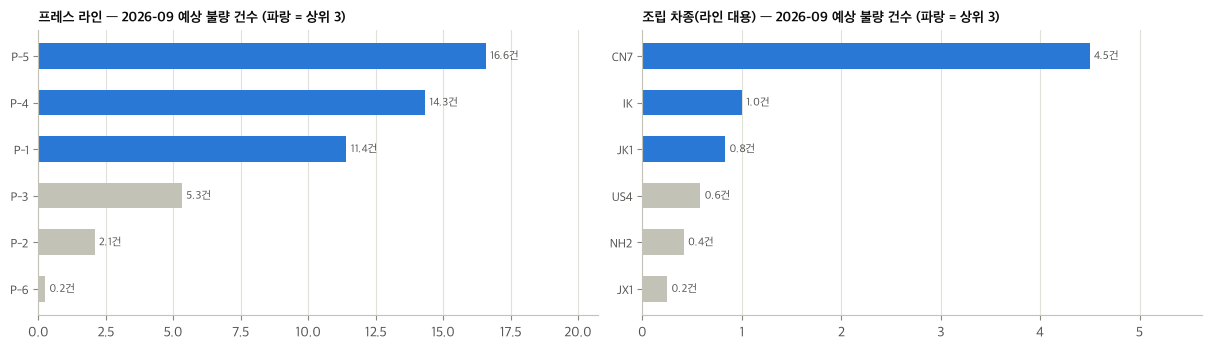

In [45]:
NEXT2 = forecast_groups(P2, GROUP_FEATURES, RES2)
type_P2, _ = type_distribution(line_events, ['라인키'], '공정', NEXT_MONTH)
rows = []
for proc in ['프레스', '조립']:
    sub = NEXT2[NEXT2['공정'] == proc].sort_values('예상건수', ascending=False).copy()
    sub['순위'] = range(1, len(sub) + 1)
    rows.append(sub)
FORECAST2 = pd.concat(rows)
FORECAST2['예상 불량유형'] = [', '.join(f'{k}({v:.0%})' for k, v in type_P2.loc[e].sort_values(ascending=False).head(2).items())
                         for e in FORECAST2['대상']]
FORECAST2['근거'] = FORECAST2.apply(lambda r: f"전월 {r['전월건수']:.0f}건 · 최근3개월 평균 {r['최근3개월평균']:.1f}건 · "
                                             f"추세 {r['추세']:+.1f} · 원자재 비율 {r['최근3개월원자재비율']:.0%}", axis=1)
FORECAST2 = FORECAST2.rename(columns={'대상': '라인'})[['공정', '순위', '라인', '예상건수', '예상 불량유형', '근거']]
print(f'{NEXT_MONTH} 점검 권장 라인 순위 (방법: {RES2["chosen"]}, 예상건수 = 다음 달 불량 기록 건수 예측)')
display(FORECAST2.round(1))
print('방법별 다음 달 상위 3개 라인 (순위가 방법에 따라 흔들리는지 확인):')
display(top_by_method(NEXT2, RES2))

type_eval_2 = evaluate_types(line_events[line_events['공정'] == '프레스'], ['라인키'], '공정', TEST_MONTHS)
print('프레스 라인의 예상 불량유형 평가 (테스트 기간):')
display(type_eval_2.round(3).to_frame('프레스 라인').T)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), layout='constrained')
for ax, proc in zip(axes, ['프레스', '조립']):
    sub = FORECAST2[FORECAST2['공정'] == proc].sort_values('예상건수')
    ax.barh(range(len(sub)), sub['예상건수'], height=0.55, color=[ACCENT if r <= 3 else GRAY for r in sub['순위']])
    ax.set_yticks(range(len(sub)), sub['라인'].str.replace(f'{proc} ', ''), fontsize=9)
    for y, v in enumerate(sub['예상건수']):
        ax.annotate(f'{v:.1f}건', (v, y), xytext=(3, 0), textcoords='offset points', va='center', fontsize=8, color=INK2)
    ax.set_title(f'{proc} {"라인" if proc == "프레스" else "차종(라인 대용)"} — {NEXT_MONTH} 예상 불량 건수 (파랑 = 상위 3)', loc='left', fontsize=10)
    ax.grid(axis='x'); ax.grid(axis='y', visible=False)
    ax.set_xlim(0, sub['예상건수'].max() * 1.25)
save_fig(fig, f'예측2_라인순위_{NEXT_MONTH.strftime("%Y%m")}'); plt.show()

### 5-3. 예측 ③ 협력사 불량 아이템

협력사 품번은 대부분 한 달에만 불량이 납니다(145개 중 105개는 12개월 중 한 달에만 발생). 그래서 두 단계로 나눠 예측합니다.
1. ③-1 협력사 위험 순위: 협력사별 다음 달 불량 건수를 ②와 같은 방법으로 예측해 점검할 협력사를 고릅니다. 최근 6개월 LOT 건수, 최근 6개월 발생 품번 수, 수입검사 발견 비율을 특성으로 더 넣었습니다.
2. ③-2 협력사·품번: ①과 같은 방법으로 품번별 발생 가능성을 예측합니다(그룹은 협력사). 품번 이력이 적으면 협력사의 최근 상태(그룹 특성)로 보완합니다.
3. 최종 목록은 ③-1 상위 협력사 안에서 ③-2 점수가 높은 품번과 예상 불량유형(협력사 유형 분포로 보완)입니다.

In [46]:
sup_events = DEFECTS[DEFECTS['영역'] == '협력사'].copy()
sup_events['품번'] = sup_events['품번'].astype(str)
sup_events['공정'] = '협력사'
lot_events = DEFECTS[DEFECTS['영역'] == '협력사LOT'].copy()
lot_m = month_matrix(lot_events, ['협력사'])
items_m = sup_events.groupby(['협력사', '년월P'])['품번'].nunique().unstack('년월P', fill_value=0).reindex(columns=MONTHS, fill_value=0)
insp_m = month_matrix(sup_events, ['협력사'], mask=sup_events['발생처'] == '수입검사')
all_m = month_matrix(sup_events, ['협력사'])


def last6(matrix, ents, t):
    i = len(MONTHS) if t > LAST_MONTH else MONTHS.get_loc(t)
    return matrix.reindex(ents).fillna(0).iloc[:, max(0, i - 6):i].sum(1).values


SUP_EXTRA = {'최근6개월LOT건수': lambda ents, t: last6(lot_m, ents, t),
             '최근6개월품번수': lambda ents, t: last6(items_m, ents, t),
             '수입검사발견비율': lambda ents, t: last6(insp_m, ents, t) / np.maximum(1, last6(all_m, ents, t))}
P3a = build_group_panel(sup_events, '협력사', extra=SUP_EXTRA)
F3a = [f for f in GROUP_FEATURES if f not in ('최근3개월원자재비율', '프레스여부')] + list(SUP_EXTRA)
RES3a = compare_regressors(P3a, F3a, title='예측 ③-1 협력사 순위')

[예측 ③-1 협력사 순위] 검증 4개월 37행 · 테스트 33행(학습 55행)
검증 상위 3개 모델: ['포아송 회귀', '엑스트라트리', 'Ridge 회귀'] / 가장 좋은 기준선: 기준선: 3개월 평균 → 최종 선택: ML 3개 + 기준선


,구분,검증 순위상관 ρ,검증 상위3 적중,검증 MAE(건),테스트 순위상관 ρ,테스트 상위3 적중,테스트 MAE(건),선택
방법,,,,,,,,
Ridge 회귀,단일 모델,0.455,0.417,1.072,0.509,0.667,1.527,
포아송 회귀,단일 모델,0.516,0.417,0.955,0.611,0.667,1.511,
랜덤포레스트,단일 모델,0.413,0.500,0.926,0.438,0.444,1.632,
엑스트라트리,단일 모델,0.483,0.500,0.910,0.530,0.444,1.588,
그래디언트부스팅,단일 모델,0.375,0.417,1.037,0.257,0.444,1.619,
히스토그램부스팅(포아송),단일 모델,0.212,0.333,1.199,0.376,0.444,1.619,
기준선: 전월 건수,기준선,0.244,0.333,1.144,0.277,0.444,1.848,
기준선: 3개월 평균,기준선,0.555,0.583,0.981,0.540,0.667,1.475,
기준선: 가중 평균,기준선,0.477,0.500,1.073,0.572,0.667,1.453,


In [47]:
P3 = build_item_panel(sup_events, ['협력사', '품번'], '협력사')
P3['최근6개월LOT건수'] = [last6(lot_m, [s], t)[0] for s, t in zip(P3['협력사'], P3['년월P'])]
K3 = 10
new_share = []
for t in TEST_MONTHS:
    act = sup_events[sup_events['년월P'] == t].groupby(['협력사', '품번']).size()
    seen = set(map(tuple, sup_events.loc[sup_events['년월P'] < t, ['협력사', '품번']].values))
    new_share.append(np.mean([k not in seen for k in act.index]))
print(f'테스트 기간에 불량이 난 협력사 품번 중 처음 보는 품번의 비율: {np.mean(new_share):.0%} (예측 후보에 들어갈 수 없음)')
RES3 = choose_feature_set(P3, {'전체 특성': ITEM_FEATURES + ['최근6개월LOT건수'], '핵심 특성': CORE_FEATURES + ['최근6개월LOT건수']},
                          K3, title='예측 ③-2')
F3 = RES3['features']
show_comparison(RES3)
type_eval_3 = evaluate_types(sup_events, ['협력사', '품번'], '협력사', TEST_MONTHS)
print('협력사 품번의 예상 불량유형 평가 (테스트 기간):')
display(type_eval_3.round(3).to_frame('협력사 품번').T)

테스트 기간에 불량이 난 협력사 품번 중 처음 보는 품번의 비율: 62% (예측 후보에 들어갈 수 없음)
[예측 ③-2 · 전체 특성] 검증 4개월 371행 · 테스트 355행(학습 540행) | 테스트 기간 실제 발생 비율(무작위로 고를 때의 적중률) 7.0%
검증 상위 3개 모델: ['로지스틱 회귀', '결정트리', '그래디언트부스팅'] / 가장 좋은 기준선: 기준선: 가중 빈도 → 최종 선택: 기준선: 가중 빈도
[예측 ③-2 · 핵심 특성] 검증 4개월 371행 · 테스트 355행(학습 540행) | 테스트 기간 실제 발생 비율(무작위로 고를 때의 적중률) 7.0%
검증 상위 3개 모델: ['로지스틱 회귀', '단조 제약 부스팅', '결정트리'] / 가장 좋은 기준선: 기준선: 가중 빈도 → 최종 선택: 기준선: 가중 빈도


,특성 수,검증 최고 AP,선택된 방법,테스트 적중률@K,테스트 AUC,선택
전체 특성,21,0.094083,기준선: 가중 빈도,0.133333,0.588303,◀ 최종
핵심 특성,9,0.094083,기준선: 가중 빈도,0.133333,0.588303,


,구분,검증 적중률@K,검증 AP,테스트 적중률@K,테스트 포착률@K,테스트 AP,테스트 AUC,선택
방법,,,,,,,,
로지스틱 회귀,단일 모델,0.050,0.076,0.167,0.195,0.115,0.513,
결정트리,단일 모델,0.050,0.067,0.100,0.134,0.066,0.444,
랜덤포레스트,단일 모델,0.050,0.048,0.133,0.164,0.127,0.504,
엑스트라트리,단일 모델,0.050,0.047,0.133,0.164,0.119,0.538,
그래디언트부스팅,단일 모델,0.075,0.062,0.100,0.134,0.118,0.451,
히스토그램부스팅,단일 모델,0.050,0.045,0.133,0.164,0.141,0.516,
단조 제약 부스팅,단일 모델,0.025,0.048,0.167,0.195,0.107,0.476,
기준선: 전월 발생,기준선,0.100,0.083,0.067,0.097,0.121,0.586,
기준선: 최근 3개월,기준선,0.075,0.085,0.167,0.231,0.123,0.598,


협력사 품번의 예상 불량유형 평가 (테스트 기간):


,평가 건수,예상 Top-1 적중,예상 Top-2 적중,기준선: 직전 유형,기준선: 전체 최빈 유형
협력사 품번,25.0,0.24,0.32,0.24,0.12


In [48]:
NEXT3a = forecast_groups(P3a, F3a, RES3a).sort_values('예상건수', ascending=False)
NEXT3a['순위'] = range(1, len(NEXT3a) + 1)
FORECAST3_SUP = NEXT3a.rename(columns={'대상': '협력사'})[['순위', '협력사', '예상건수', '전월건수', '최근3개월평균', '최근6개월LOT건수', '최근6개월품번수']]
print(f'{NEXT_MONTH} 협력사 위험 순위 (방법: {RES3a["chosen"]})')
display(FORECAST3_SUP.head(10).round(1))
print('방법별 다음 달 상위 5개 협력사:')
display(top_by_method(NEXT3a, RES3a, top=5))

NEXT3 = fit_final_scores(P3, F3, RES3)
sup_info = (sup_events.sort_values('일자').groupby(['협력사', '품번'])
            .agg(품명=('품명', 'last'), 차종=('차종', 'last'), 발생처=('발생처', 'last'), 마지막발생=('일자', 'max'), 누적=('수량', 'size')))
top_suppliers = FORECAST3_SUP['협력사'].head(5).tolist()
rows = []
for rank, s_name in enumerate(top_suppliers, start=1):
    sub = NEXT3[NEXT3['협력사'] == s_name].sort_values('위험점수', ascending=False).head(3).copy()
    sub['협력사순위'] = rank
    rows.append(sub)
FORECAST3 = pd.concat(rows).join(sup_info, on=['협력사', '품번'])
FORECAST3['예상 불량유형'] = expected_types(sup_events, ['협력사', '품번'], '협력사', NEXT_MONTH, list(zip(FORECAST3['협력사'], FORECAST3['품번'])))
FORECAST3['근거'] = FORECAST3.apply(lambda r: f"누적 {r['누적']:.0f}건 · {r['최근6개월발생월수']:.0f}/6개월 발생 · "
                                             f"협력사 최근3개월 {r['그룹최근3개월건수']:.0f}건", axis=1)
FORECAST3['마지막발생'] = FORECAST3['마지막발생'].dt.date
FORECAST3 = FORECAST3[['협력사순위', '협력사', '품번', '품명', '차종', '위험점수', '예상 불량유형', '근거', '마지막발생', '발생처']]
print(f'{NEXT_MONTH} 점검 권장 협력사·품번 (상위 5개 협력사 × 품번 3개, 방법: {RES3["chosen"]})')
display(FORECAST3.round(3))

2026-09 협력사 위험 순위 (방법: ML 3개 + 기준선)


,순위,협력사,예상건수,전월건수,최근3개월평균,최근6개월LOT건수,최근6개월품번수
89,1,대신정공,4.1,3.0,4.3,2.0,16
98,2,정하이텍,3.9,4.0,4.7,7.0,15
88,3,길창,3.7,7.0,3.3,1.0,13
90,4,성심정밀,3.0,3.0,2.3,1.0,13
93,5,영보산업,2.2,1.0,3.3,0.0,15
96,6,유성에프티,1.8,3.0,1.3,0.0,6
95,7,우영산업,1.3,2.0,1.0,0.0,5
91,8,성지산업,1.2,0.0,1.0,1.0,5
99,9,현대제철,1.1,2.0,0.7,2.0,3
92,10,스템테크,0.8,1.0,0.7,1.0,2


방법별 다음 달 상위 5개 협력사:
협력사 상위 5: 모든 방법에 공통 = 길창, 대신정공, 성심정밀, 정하이텍 · 최종 방법 목록과 평균 89% 겹침 (순서는 무시)


,협력사 상위 5
방법,
ML 3개 + 기준선 (최종),"대신정공, 정하이텍, 길창, 성심정밀, 영보산업"
포아송 회귀,"길창, 대신정공, 정하이텍, 성심정밀, 유성에프티"
엑스트라트리,"대신정공, 길창, 성심정밀, 정하이텍, 유성에프티"
Ridge 회귀,"대신정공, 정하이텍, 길창, 성심정밀, 유성에프티"
앙상블: 평균,"대신정공, 길창, 정하이텍, 성심정밀, 유성에프티"
기준선: 전월 건수,"길창, 정하이텍, 대신정공, 성심정밀, 유성에프티"
기준선: 3개월 평균,"정하이텍, 대신정공, 길창, 영보산업, 성심정밀"
기준선: 가중 평균,"정하이텍, 대신정공, 길창, 성심정밀, 영보산업"
기준선: 전체 평균,"대신정공, 성심정밀, 정하이텍, 영보산업, 길창"


2026-09 점검 권장 협력사·품번 (상위 5개 협력사 × 품번 3개, 방법: 기준선: 가중 빈도)


,협력사순위,협력사,품번,품명,차종,위험점수,예상 불량유형,근거,마지막발생,발생처
944,1,대신정공,71788-G9000,PNL-PACKAGE TRAY SD FR LWR RH,IK,0.945,"홀누락(65%), 발청(9%)",누적 3건 · 2/6개월 발생 · 협력사 최근3개월 13건,2026-08-27,IK 조립라인
930,1,대신정공,71556-K2000,EXTN-SIDE OTR RR UPR LH,QX,0.931,"이물질(31%), 홀누락(24%)",누적 5건 · 2/6개월 발생 · 협력사 최근3개월 13건,2026-07-03,QX 조립라인
942,1,대신정공,71721-G9000,PNL ASSY-PACKAGE TRAY SD FR RH,IK,0.838,"발청(61%), 홀누락(7%)",누적 1건 · 1/6개월 발생 · 협력사 최근3개월 13건,2026-08-26,IK 조립라인
1018,2,정하이텍,643B8-AR000,REINF-DASH UPR SIDE RH,JK1,1.000,"홀사이즈미달(39%), 성형미흡(21%)",누적 5건 · 3/6개월 발생 · 협력사 최근3개월 14건,2026-08-19,JK1 조립라인
1025,2,정하이텍,69186-G9500,SUPPORT-LUGGAGE SIDE TRIM RH,IKF/L,0.972,"성형미흡(35%), 홀산포(35%)",누적 2건 · 1/6개월 발생 · 협력사 최근3개월 14건,2026-07-21,IK 조립라인
1031,2,정하이텍,71584-T4000,EXTN-RR COMBI/LAMP HSG RH,RS4,0.924,"이물질(29%), 변형(27%)",누적 3건 · 2/6개월 발생 · 협력사 최근3개월 14건,2026-06-20,RS4 조립라인
902,3,길창,667B1-AR000,REINF ASSY-COWL I/L SD NO.2 RH,JK1,0.903,"성형미흡(61%), 형상밀림(11%)",누적 2건 · 1/6개월 발생 · 협력사 최근3개월 10건,2026-08-28,JK1 조립라인
897,3,길창,643D2-XH000,MEMBER-DASH CTR SUPPORT UPR,NH2,0.897,"발청(58%), 형상밀림(11%)",누적 2건 · 1/6개월 발생 · 협력사 최근3개월 10건,2026-08-27,NH2 조립라인
905,3,길창,71516-K2000,BRKT-GAS LIFTER MTG LH,QX,0.838,"성형미흡(58%), 형상밀림(12%)",누적 1건 · 1/6개월 발생 · 협력사 최근3개월 10건,2026-08-10,QX 조립라인
966,4,성심정밀,71696-G9000,BRKT-RR WHEEL GUARD MTG RH,IK,0.979,"형상밀림(44%), 찍힘(37%)",누적 2건 · 1/6개월 발생 · 협력사 최근3개월 7건,2026-08-27,IK 조립라인


### 5-4. 예측 결과 정리와 저장

- `output/prediction/`에 다음 달 점검 목록(CSV, 엑셀), 모델 비교표, 주요 위험변수를 저장합니다.
- 예측 결과를 보고서 어디에 넣을지는 아직 정해지지 않았습니다. 첨부2 양식에 자리가 없어서(요구사항 R5, 회사 확인 필요) PPT에는 넣지 않고 엑셀로 따로 둡니다.

In [49]:
NEXT_TAG = NEXT_MONTH.strftime('%Y%m')
pred_xlsx = OUT['prediction'] / f'다음달_점검목록_{NEXT_TAG}.xlsx'
with pd.ExcelWriter(pred_xlsx, engine='openpyxl') as writer:
    FORECAST1.to_excel(writer, sheet_name='①사내공정_품번', index=False)
    FORECAST2.to_excel(writer, sheet_name='②사내공정_라인순위', index=False)
    FORECAST3_SUP.to_excel(writer, sheet_name='③협력사_순위', index=False)
    FORECAST3.to_excel(writer, sheet_name='③협력사_품번', index=False)
    for name, res in [('①모델비교', RES1), ('②모델비교', RES2), ('③-1모델비교', RES3a), ('③-2모델비교', RES3)]:
        res['table'].to_excel(writer, sheet_name=name)
    IMP1.to_excel(writer, sheet_name='①주요위험변수')
FORECAST1.to_csv(OUT['prediction'] / f'예측1_사내공정_품번_{NEXT_TAG}.csv', index=False, encoding='utf-8-sig')
FORECAST2.to_csv(OUT['prediction'] / f'예측2_사내공정_라인순위_{NEXT_TAG}.csv', index=False, encoding='utf-8-sig')
FORECAST3_SUP.to_csv(OUT['prediction'] / f'예측3_협력사_순위_{NEXT_TAG}.csv', index=False, encoding='utf-8-sig')
FORECAST3.to_csv(OUT['prediction'] / f'예측3_협력사_품번_{NEXT_TAG}.csv', index=False, encoding='utf-8-sig')


def perf_row(task, res, metric_cols):
    t = res['table']
    rank = int(t[metric_cols[0]].rank(ascending=False, method='min')[res['chosen']])
    return {'예측': task, '최종 방법': res['chosen'], **{c: t.at[res['chosen'], c] for c in metric_cols},
            f'{metric_cols[0]} 순위': f'{rank}/{len(t)}',
            **{f'기준선 {c}': t.at[res['best_base'], c] for c in metric_cols}}


PERF = pd.DataFrame([
    perf_row('① 사내 공정 품번 (프레스 10 · 조립 5)', RES1, ['테스트 적중률@K', '테스트 AUC']),
    perf_row('③-2 협력사 품번 (10)', RES3, ['테스트 적중률@K', '테스트 AUC']),
])
PERF_REG = pd.DataFrame([
    perf_row('② 사내 공정 라인 순위', RES2, ['테스트 순위상관 ρ', '테스트 상위3 적중']),
    perf_row('③-1 협력사 순위', RES3a, ['테스트 순위상관 ρ', '테스트 상위3 적중']),
])
print('테스트 기간(처음 보는 3개월) 성능 요약 — 최종 방법 vs 가장 좋은 기준선 (순위 = 비교한 방법 중 테스트 성적 순위)')
display(PERF.round(3)); display(PERF_REG.round(3))
print('저장:', pred_xlsx.relative_to(PROJECT_DIR))

테스트 기간(처음 보는 3개월) 성능 요약 — 최종 방법 vs 가장 좋은 기준선 (순위 = 비교한 방법 중 테스트 성적 순위)


,예측,최종 방법,테스트 적중률@K,테스트 AUC,테스트 적중률@K 순위,기준선 테스트 적중률@K,기준선 테스트 AUC
0,① 사내 공정 품번 (프레스 10 · 조립 5),로지스틱 회귀,0.600,0.829,6/13,0.583,0.825
1,③-2 협력사 품번 (10),기준선: 가중 빈도,0.133,0.588,4/13,0.133,0.588


,예측,최종 방법,테스트 순위상관 ρ,테스트 상위3 적중,테스트 순위상관 ρ 순위,기준선 테스트 순위상관 ρ,기준선 테스트 상위3 적중
0,② 사내 공정 라인 순위,기준선: 전체 평균,0.591,0.889,12/12,0.591,0.889
1,③-1 협력사 순위,ML 3개 + 기준선,0.564,0.667,5/12,0.540,0.667


저장: output/prediction/다음달_점검목록_202609.xlsx


### 5-5. 예측 결과 해석 (2026-10-24 실행 기준)

| 예측 | 테스트(26.6~8) 성능 | 무작위, 기준선과 비교 | 판단 |
|---|---|---|---|
| ① 프레스 품번 Top-10 | 적중률 80% (매달 10개 중 8개에서 실제 불량), AUC 0.83 (프레스·조립 전체) | 무작위 18%의 약 4.4배, 단순 빈도 기준선 77% | 현장 점검 목록으로 바로 쓸 수 있는 수준 |
| ① 조립 품번 Top-5 | 적중률 40%, 포착률 81% | 무작위 10%의 4배. 단순 빈도 기준선도 40%로 같음 | 테스트 기간 조립 불량 품번이 달마다 4·1·3개뿐이라 5개를 뽑을 때 적중률 상한이 53%임 |
| ① 예상 불량유형 (프레스) | Top-1 76%, Top-2 87% | 직전 유형 68%, 전체 최빈 36% | 점검할 때 어떤 불량을 볼지까지 알려 줄 수 있음 |
| ② 라인 순위 | 최종 방법(기준선: 전체 평균) 상위 3개 적중 89%, 순위상관 0.59. 전체 방법 범위는 상위 3개 적중 83~89%, 순위상관 0.59~0.73 | 전체 평균은 검증 기간 순위상관이 가장 높아(0.76) 골랐지만, 테스트 기간 순위상관은 12개 방법 중 가장 낮았음(5-4 표의 순위 12/12). 방법 사이 차이를 따로 검정하지는 않았고, 공정마다 대상이 6개 이하라 순위상관 값 자체가 크게 흔들릴 수 있음 | 9월 상위 라인(프레스 P-5, P-4, P-1, 조립 CN7, JK1)은 어느 방법으로 해도 같고 순서만 다름. 점검할 라인을 고르는 데는 쓸 수 있지만 순서까지 믿기는 어려움 |
| ③-1 협력사 순위 | 순위상관 0.56, 상위 3개 적중 67% | 기준선(3개월 평균, 0.54)과 비슷. 테스트 순위상관은 12개 방법 중 5위 | 대신정공, 정하이텍, 길창, 성심정밀은 모든 방법에서 상위 5위 안. 협력사 단위 점검 대상으로 쓸 수 있음 |
| ③-2 협력사 품번 Top-10 | 적중률 13%, AUC 0.59 | 무작위 7%의 약 2배 | 품번 단위로는 한계가 있음. 테스트 기간 협력사 불량 품번의 62%가 처음 나오는 품번이라 품번 목록은 참고만 하고, 점검은 위험 협력사와 재발 품번 위주로 |

ML 모델과 앙상블
- 품번 예측(①, ③-2)은 7개 모델, 3가지 앙상블, 2가지 특성 세트를, 건수 예측(②, ③-1)은 6개 모델과 2가지 앙상블을 같은 조건(시간 순서 교차검증으로 선택하고 모델 선택에 쓰지 않은 3개월로 평가)에서 비교했습니다. 기준선도 후보에 넣어서 ML이 기준선보다 못하면 기준선이 선택되게 했습니다.
- 지금 데이터(12개월)에서는 최근에 불량이 자주 난 품번, 라인, 협력사가 다음 달에도 난다는 경향이 가장 강하고, ML은 이를 조금 보정하는 정도였습니다(① 주요 위험변수 1위 가중건수, 2위 같은 라인의 최근 3개월 건수).
- ①에서는 핵심 특성 9개와 전체 특성 21개의 검증 AP가 0.70243과 0.70237로 사실상 같아서 핵심 특성의 로지스틱 회귀가 골라졌습니다. 테스트 적중률(60%)은 13개 방법 중 6위로, 가장 높은 방법(62%)과 거의 같았습니다. ③-2는 두 특성 세트 모두 단순 빈도 기준선이 골라졌습니다. 특성을 줄여도 성능이 떨어지지 않았으므로 설명하기 쉬운 핵심 특성을 쓰는 편이 낫습니다.
- 데이터가 24개월 이상 쌓이고 품번별 생산량, 다음 달 생산계획, 4M 변경 이력이 들어오면 특성으로 추가해 ML 효과가 더 커질 수 있습니다(6장). 특성 목록에 열 이름만 추가하면 다시 비교됩니다.

---
## 6. 데이터 대기 항목과 다음 단계

아직 데이터가 없어 남겨 둔 부분을 점검합니다. 데이터가 들어오면 노트북을 다시 실행하기만 하면 반영되도록 해 두었습니다.

In [50]:
cqi_months_so_far = [m for m in MONTHS if m.year == CQI_YEAR]
missing_receipts = [str(m) for m in cqi_months_so_far if pd.isna(RECEIPTS.get(m))]
missing_manual = [str(m) for m in cqi_months_so_far if MANUAL_SRC.at[m, '품질비용'] == '없음']
gyeongju_sheets = sorted({s for f in DEFECT_FILES for s in pd.ExcelFile(f).sheet_names if '경주' in s})
gyeongju_targets = openpyxl.load_workbook(CQI_BOOK, data_only=True)['경주']['F9'].value if '경주' in openpyxl.load_workbook(CQI_BOOK, read_only=True).sheetnames else None

READINESS = pd.DataFrame([
    {'항목': '협력사 입고수량', '상태': '없음: ' + ', '.join(missing_receipts) if missing_receipts else '있음',
     '지금의 처리': '첨부3 회사값으로 입고불량 PPM을 채우고 출처 표시 (1-4)',
     '데이터가 오면': 'SAP 입고 리스트(협력사입고수량*.xlsx)를 data/raw/ 아래에 넣거나 data/manual/협력사입고수량_월별.csv에 월 합계 입력 → 자동 계산'},
    {'항목': f'예방품질·품질비용 ({NEXT_MONTH.month}월~)', '상태': f'{NEXT_MONTH} 이후 입력 필요' + (f' / 빈 달: {", ".join(missing_manual)}' if missing_manual else ''),
     '지금의 처리': '첨부3 입력값 사용 (빈칸은 첨부3 수식대로 0점)',
     '데이터가 오면': 'data/manual/수기입력_CQI.csv의 해당 월에 점수·비율 입력 → 100점 총점 자동 계산'},
    {'항목': '고객 등록 수량', '상태': f"있음 ('{REG_COL}' 열)" if REG_COL else '없음 (10/1 메일: 등록 0건)',
     '지금의 처리': '고객불량(등록) PPM·고객등록률 = 0', '데이터가 오면': "첨부1 고객 시트에 '등록'이 들어간 열 추가 → 자동 사용"},
    {'항목': '조립 불량 발생 라인', '상태': '있음' if '라인' in D['조립'].columns else '없음',
     '지금의 처리': '차종그룹을 라인 대신 사용 (4-3, 5-2)', '데이터가 오면': "첨부1 조립 시트에 '라인' 열 추가 → 통합 CSV·예측 ②에 자동 사용"},
    {'항목': '경주 공정·협력사 데이터', '상태': ('있음: ' + ', '.join(gyeongju_sheets)) if gyeongju_sheets else '없음',
     '지금의 처리': '보고서 슬라이드 1·3에 "데이터 없음" 표시', '데이터가 오면': '첨부1 형식의 경주 시트 + 첨부3 경주 목표값 필요 (시트 이름 규칙 확인 후 ATT1_SHEETS에 추가)'},
    {'항목': '경주 CQI 목표값 (첨부3 경주 시트)', '상태': '있음' if gyeongju_targets not in (None, '') else '없음 (공정·협력사 목표 빈칸)',
     '지금의 처리': '경주 CQI 미산출', '데이터가 오면': '첨부3 경주 시트 F열에 목표 입력'},
    {'항목': '품번·라인별 생산수량, 다음 달 생산계획', '상태': '없음',
     '지금의 처리': '예측은 건수 기반 (불량률 아님)', '데이터가 오면': '품번별 불량률·물량 특성을 예측 모델에 추가 (5장 특성 표에 열 추가)'},
    {'항목': '4M 변경 이력 (코일 LOT·금형 수리·신차 투입)', '상태': '없음',
     '지금의 처리': '-', '데이터가 오면': '프레스 원자재 귀책 불량(P-1·P-3·P-5 70% 이상)의 원인 변수로 사용'},
])
with pd.option_context('display.max_colwidth', 120):
    display(READINESS)
READINESS.to_csv(OUT_DIR / '데이터_대기항목_점검.csv', index=False, encoding='utf-8-sig')

,항목,상태,지금의 처리,데이터가 오면
0,협력사 입고수량,없음: 2026-08,첨부3 회사값으로 입고불량 PPM을 채우고 출처 표시 (1-4),SAP 입고 리스트(협력사입고수량*.xlsx)를 data/raw/ 아래에 넣거나 data/manual/협력사입고수량_월별.csv에 월 합계 입력 → 자동 계산
1,예방품질·품질비용 (9월~),2026-09 이후 입력 필요,첨부3 입력값 사용 (빈칸은 첨부3 수식대로 0점),data/manual/수기입력_CQI.csv의 해당 월에 점수·비율 입력 → 100점 총점 자동 계산
2,고객 등록 수량,없음 (10/1 메일: 등록 0건),고객불량(등록) PPM·고객등록률 = 0,첨부1 고객 시트에 '등록'이 들어간 열 추가 → 자동 사용
3,조립 불량 발생 라인,없음,"차종그룹을 라인 대신 사용 (4-3, 5-2)",첨부1 조립 시트에 '라인' 열 추가 → 통합 CSV·예측 ②에 자동 사용
4,경주 공정·협력사 데이터,없음,"보고서 슬라이드 1·3에 ""데이터 없음"" 표시",첨부1 형식의 경주 시트 + 첨부3 경주 목표값 필요 (시트 이름 규칙 확인 후 ATT1_SHEETS에 추가)
5,경주 CQI 목표값 (첨부3 경주 시트),없음 (공정·협력사 목표 빈칸),경주 CQI 미산출,첨부3 경주 시트 F열에 목표 입력
6,"품번·라인별 생산수량, 다음 달 생산계획",없음,예측은 건수 기반 (불량률 아님),품번별 불량률·물량 특성을 예측 모델에 추가 (5장 특성 표에 열 추가)
7,4M 변경 이력 (코일 LOT·금형 수리·신차 투입),없음,-,프레스 원자재 귀책 불량(P-1·P-3·P-5 70% 이상)의 원인 변수로 사용


### 6-1. 필요 추가 데이터

| 우선순위 | 데이터 | 이유 (노트북에서 확인한 내용) |
|---|---|---|
| 필수 | 협력사 월 입고수량 (25.9~26.4, 26.8~) | 8월 입고불량 PPM을 계산하지 못해 회사값을 씀(1-4). 2·3월은 회사값과 0.4 PPM 차이(1-7). 8월 물량 효과 중 −2.8점도 회사 PPM으로 역산한 입고수량에서 나온 값이라 확정할 수 없음(3-2) |
| 필수 | 라인·품번별 월 생산수량 (POP, P-6 포함) | 지금은 건수로만 예측함. 8월처럼 고객 납품과 블랭크·프레스 생산이 절반 가까이 준 달은 건수와 PPM이 반대로 움직임(3-2: 물량 효과 −7.1점 중 원천 생산·납품 수량 감소분 −4.3점) |
| 필수 | 조립 불량 발생 라인 | 예측 ②와 상관분석에서 차종으로 대신하고 있음 |
| 높음 | 다음 달 생산·입고 계획 | 물량 변화가 CQI 변화의 가장 큰 원인인 달이 있음. 계획을 알면 다음 달 PPM 변동을 미리 설명할 수 있음 |
| 중간 | 25.9 이전 불량 이력 (24개월 이상) | 계절성(예: 26년 7~8월 협력사 발청 증가) 확인 |
| 중간 | 4M 변경 이력 | 프레스 불량의 약 2/3가 원자재 귀책이고 라인별 유형이 몰려 있음(P-5 크랙 등, 4-3) |
| 확인 | 분리시험·샘플용 폐기를 공정불량 PPM에 넣는지 | 8월 조립 불량 12EA 중 6EA가 품질팀 분리시험(4-3) |
| 확인 | 프레스 유출률 7월 0% 처리 사유, 입고수량 추출 기준일, 초도합격률 산식, 고객등록률 산식 | 1-7 대조 결과 |

### 6-2. 결과 파일 목록

In [51]:
files = sorted(p for p in OUT_DIR.rglob('*') if p.is_file() and not p.name.startswith('.'))
listing = pd.DataFrame([{'폴더': nfc(p.parent.relative_to(OUT_DIR)), '파일': nfc(p.name), '크기(KB)': round(p.stat().st_size / 1024, 1)} for p in files])
print(f'output/ 아래 파일 {len(listing)}개')
with pd.option_context('display.max_rows', 200):
    display(listing.groupby('폴더').agg(파일수=('파일', 'size'), 예시=('파일', lambda s: ', '.join(s.head(4)))))

output/ 아래 파일 77개


,파일수,예시
폴더,,
.,1,데이터_대기항목_점검.csv
analysis,2,"상관분석_요약.csv, 협력사_상위업체_아이템.csv"
cqi,5,"CQI_검증_첨부3대조.csv, CQI_실적_계산과정_월별.csv, CQI_지표별_실적과점수_월별.csv, CQI_지표..."
figures,29,"AI평가_202608_지표별점수변화.png, 보고서_202608_CQI_종합.png, 보고서_202608_고객실질_월별..."
integrated,2,"불량_통합.csv, 월별_수량.csv"
prediction,5,"다음달_점검목록_202609.xlsx, 예측1_사내공정_품번_202609.csv, 예측2_사내공정_라인순위_202609..."
report,2,"AI분석평가_문구_월별.csv, 월품질실적보고_자동_202608.pptx"
report/202608,31,"AI분석평가_문구_202608.txt, CQI_대분류별_전월대비_202608.csv, CQI_지표별_전월대비_20260..."
